# Study 4 — Từ nào, ngôn ngữ nào được chia sẻ ở eo của hourglass? (S3 trên văn bản tự nhiên)

**Câu hỏi.** Conjecture 2 (Zipf như khấu hao): căn chỉnh của một từ theo log-hạng tần suất là chữ **U ngược** (từ rất phổ biến mang mã riêng theo ngôn ngữ, từ hạng giữa được chia sẻ nhiều nhất, đuôi hiếm ước lượng kém), và đỉnh r* **dịch ra ngoài khi capacity tăng**. A2 (Platonic) dự đoán tăng đơn điệu. Ngoài ra: ngôn ngữ gần nhau về loại hình có căn chỉnh tốt hơn không (Mantel)?

**Quy trình (Algorithm 5).** tách từ + UPOS -> tần suất FineWeb-2 -> gióng hàng Eflomal + lọc MUSE -> biểu diễn mức từ (trung bình sub-token) -> R_k = MRR/CSLS cho từng từ ở từng tầng -> GAM(R_k ~ log-hạng + UPOS + độ dài + fertility + ngôn ngữ) -> đơn điệu vs unimodal -> Mantel.

| Cell | Nội dung | GPU |
|---|---|---|
| A1–A2 | config, registry model (core / sweep / 2b local) | |
| A3–A6 | dữ liệu, tách từ + UPOS, tần suất, gióng hàng + MUSE -> `ITEMS`, `NEED` | |
| B1–B2 | trích biểu diễn mức từ theo batch (ngân sách token), truy hồi CSLS theo tầng | x |
| C1–C2 | vòng chạy có resume (`runs/{model}/retrieval.npz`) | x |
| C3–C7 | bảng từ, GAM + bootstrap theo lô, shape CV, Mantel, capacity, kết luận | bootstrap nhanh hơn trên GPU |
| D1–D2 | hình (PDF, quy ước Study 1) | |

**Lưu ý trước khi chạy.** Các mục `[XM]` (tên dataset/model, mã FineWeb-2, URL MUSE, mã Stanza) viết theo trí nhớ, cần xác minh. Cell A5 (đếm tần suất) và A6 (Eflomal) chạy lâu nhưng chỉ một lần và có cache. Sau khi có kết quả, các cell C3–D2 chỉ đọc `study4/analysis/`.

---
### Bản sửa v2 (rà soát phương pháp)
| # | Vấn đề | Sửa |
|---|---|---|
| 1 | CSLS tính trên pool **instance**: từ phổ biến có hàng trăm bản sao nên bị coi là hub và bị phạt -> tự tạo "nhánh trái" | `HUB_MODE="type"`: mỗi loại từ chỉ được đếm một lần trong láng giềng (A1, B2). `"instance"` = hành vi cũ, `"cos"` = cosine thường |
| 2 | `amp` luôn ≥ 0 kể cả với đường đơn điệu | `amp` = đỉnh − max(hai đầu) (≈ 0 khi đơn điệu); công thức cũ giữ ở `amp_mean_ends` |
| 3 | `p_LM` không phải Lind–Mehlum, độ dốc đo bằng hai điểm biên + clip dồn điểm ở biên; `p_monotone_up` đo ngược hướng A2 | độ dốc = OLS trên 20% mỗi đầu; `p_LM` = max hai p một phía; thêm `p_left_up/p_right_down/...`, `shape`; bỏ clip (cắt bằng loại bỏ); `A2_refuted` = đầu trái tăng theo hạng |
| 4 | r\* được báo cáo cả khi không có đỉnh | cột `peak_ok`; slope capacity tính thêm trên các model có đỉnh, kèm Kendall p và leave-one-out |
| 5 | Hạng bằng nhau xếp theo bảng chữ cái | hạng trung bình cho nhóm bằng nhau (A5) |
| 6 | Từ unseen nhận hạng giả V+1; hiệu ứng thành phần cặp ngôn ngữ | `DROP_UNSEEN`, covariate `pmix` (độ dễ trung bình của các cặp mà từ tham gia), `MAIN_PAIRS="muse"` (chỉ cặp xác nhận bằng MUSE), `AXIS` |
| 7 | `n_inst` đếm hàng (instance × cặp); `n_pool`/waist bị cặp nhỏ (Dice) chi phối | `n_inst` đếm instance thật, thêm `n_pairs`; `n_pool` và waist chỉ dùng cặp ≥ `MIN_PAIR_ITEMS` |
| 8 | Chẩn đoán MUSE / hub | cell A7 `muse_coverage()`, cell E1 `diag_hub_modes()` |

**Chạy lại:** kết quả truy hồi cũ bị đánh dấu `stale` (theo `retr_version`/`hub_mode`), `run_all()` sẽ trích lại biểu diễn và tính lại. Chạy lại cell A5 (Cell 9) để cập nhật hạng.


---
### Bản v3 (tận dụng dữ liệu)
| # | Trước | Nay |
|---|---|---|
| 1 | Chỉ FLORES devtest (1012 câu) được ĐO; dev (997) + NTREX (1997) chỉ dùng để học Eflomal rồi **bỏ** liên kết | `MEASURE_SETS`: cả ba nguồn gộp thành một corpus (~4000 câu); thêm tập con `src_*` để kiểm tra lặp lại theo miền |
| 2 | Tần suất: 20M từ/ngôn ngữ (cap docs 100k không bao giờ chạm) | 200M từ (100M cho zh/ja/th/vi), cắt hapax ngoài corpus đo để tiết kiệm RAM; in tỉ lệ unseen mỗi ngôn ngữ |
| 3 | `POOL_N=500`, `POOL_REPS=10` | `1000`, `20` (cặp nhỏ nhất giờ có nhiều mục hơn) |
| 4 | Cache cũ | `RUN_TAG="_full"`, `FREQ_DIR` có hậu tố `FW_TAG`, `RETR_VERSION=3` -> không lẫn kết quả cũ |

Đặt `MEASURE_SETS = ["flores"]` để quay về hành vi cũ. Cache biểu diễn Qwen3-8B tăng ~4x (đặt `KEEP_WORD_CACHE=False`, cần ~200GB đĩa tạm).

---
### Bản v4 (làm sạch gióng hàng / từ điển / độ bền theo ngôn ngữ)
| # | Vấn đề | Sửa |
|---|---|---|
| 1 | MUSE `zh-en` là phồn thể (體, 球隊) còn corpus giản thể -> độ phủ zho 0.04–0.32 | `MUSE_ZH_T2S=True`: đổi MUSE zh sang giản thể khi nạp (OpenCC/zhconv) (A6) |
| 2 | fugashi cắt hình vị ngắn (使っ, 読み, まし) còn MUSE dùng dạng gốc -> độ phủ jpn top-100 chỉ 0.12 | `ALT_KEY_LANGS`: tra từ điển thêm bằng `orthBase`/`lemma` (A4, A6); đơn vị từ, tần suất, gióng hàng, biểu diễn KHÔNG đổi |
| 3 | MUSE không có Swahili (403) -> 11 cặp rơi xuống Dice; UPOS swh = UNK 100% (cộng tuyến với hiệu ứng ngôn ngữ) | Từ điển thay thế (`ALT_DICT`: tệp `raw/dict_alt/sw-en.txt` hoặc tự dựng từ Wiktionary/kaikki.org), nhãn nguồn `alt`; **tầng chính** (`MAIN_SRCS`) tách khỏi **tầng mở rộng**; chiếu UPOS qua căn chỉnh (Cell A6b) |
| 4 | Không có kiểm tra kết luận có phụ thuộc vào jpn / zho / swh hay không | Leave-one-language-out, bỏ cả 3 ngôn ngữ cùng lúc, tầng mở rộng riêng, Mantel chính vs mở rộng, bảng độ bền (Cell C5b) |

Cell mới: **A6b** (chiếu UPOS), **A7b** (chẩn đoán từ điển zho/jpn/swh), **C5b** (bảng độ bền). Kết quả truy hồi cũ tự bị coi là `stale` khi ITEMS đổi (`items_sig`), nên `run_all()` sẽ tính lại.
**Thứ tự chạy lại:** pip (cell 1) -> A1 -> ... -> A6 -> `build_items` (không chạy lại Eflomal, chỉ lọc lại) -> A6b -> A7/A7b -> C2 (`run_all`) -> C3...C7.

---
### Bản v5 (rà soát độ tin cậy: sửa lỗi đo, kiểm định, bootstrap, capacity, sanity, bảo mật)
| # | Vấn đề (đã xác nhận trong code) | Sửa |
|---|---|---|
| A | B2 chỉ che ứng viên CÙNG dạng đích với đáp án; các bản dịch hợp lệ khác (the→le thì la, les) vẫn là "đối thủ" -> từ chức năng/phổ biến nhiều dạng dịch có MRR thấp, tự tạo "đầu trái tăng" | `csls_mrr(which="both")`: thêm mặt nạ `acc` (mọi cặp nguồn→đích đã gióng + xác nhận); lưu cả `RR_*` (strict) và `RR_*_V` (valid); `RR_VARIANT="valid"` là chính, `rr_strict` là đối chiếu; covariate `trans_ent`; chẩn đoán `diag_mask_effect` (E2) |
| B | GAM vẽ đã hiệu chỉnh (UPOS, độ dài, nsub, pmix, ngôn ngữ) còn chấm xám là trung bình thô -> hai thứ khác estimand | GAM `covars="none"` (chỉ spline) + `covars="upos_pmix"` chạy ở tầng waist, vẽ chồng lên chấm thô (D2), báo trong tập con `gam_bare` / `gam_upos_pmix` |
| C | Độ dốc đo trên 20% ngoài cùng của LƯỚI x (không phải dữ liệu), nơi P-spline dao động và có khối hapax chung hạng; tiêu chí `p_LM` không dùng `amp` | Thêm tiêu chí song song, áp dụng đồng loạt cho mọi model: `*_q` (đầu/đuôi theo phân vị dữ liệu `EDGE_Q`) và `p_LM_amp` (đỉnh cao hơn cả hai đầu). Tập con `no_hapax`. `diag_tie_block` (E2). **Tiêu chí cũ giữ nguyên để so sánh** |
| D | MUSE phủ giảm mạnh theo hạng, DROP_SAME_FORM bỏ mục dễ ở đuôi: hai lọc kéo đuôi ngược chiều | Cell A7c `selection_diag()`: tỉ lệ dạng từ sống sót theo ngôn ngữ x khoảng hạng sau từng bộ lọc (chẩn đoán; đổi bộ lọc cần chạy lại build_items + C2) |
| E | Bootstrap theo từng dòng như độc lập (cùng khái niệm ở 12 ngôn ngữ), λ cố định, p = 0.000 là sàn của B lần | `CLUSTER_BOOT`: bootstrap theo cụm khái niệm (`_concepts`, pivot tiếng Anh); `LAM_SENS` (tập con `lam_x0.1`, `lam_x10`); p cộng một `(1+k)/(B+1)` |
| F | 4 decoder; argmax dính biên (0.6B ở cận dưới lưới, 8B/4B có CI chạm cận trên); Kendall n=4 có p tối thiểu 0.083; `peak_ok_only` chỉ 1 model | `at_boundary`, `centroid` (thống kê không dính biên), `kendall_p_floor`, slope gộp có hiệu ứng cố định theo họ + `concordant_pairs`, tập con `interior_peak_only` / `peak_ok_amp_only` |
| G | `sanity_batch_vs_single` trả giá trị nhưng bị bỏ qua; Qwen3-8B (2.50%, max 0.21) và **Qwen3-4B** (1.16%, max 0.84) đều bị cảnh báo lệch; chỉ thử tiếng Anh | Sanity trên `SANITY_LANGS`, kết quả ghi vào `meta.json`; `SANITY_ON_FAIL="fp32_check"` tải bản fp32 và thử lại; `EXTRACT_DTYPE`; cột `numerics_flag`, `n_clip` trong bảng tổng hợp; `diag_numerics()` (E2) |
| H | `.round(3)` làm `d_mono_vs_gam` ~1e-5 hiện thành 0.0; trục y mỗi panel một khác | `fmt_sci` (dạng khoa học có dấu); `plot_s3_curves(sharey=True)` + ghi range của GAM trên mỗi panel |
| S | Notebook chứa HF token ghi thẳng trong code (A1) | Gỡ token; chỉ đọc `HF_TOKEN` từ biến môi trường. **Thu hồi token cũ trên Hugging Face** |

**Phải chạy lại GPU:** `RETR_VERSION` 3 -> 4 (và kết quả lưu thêm `RR_*_V`, `meta.json` thêm `mask_valid`, `dtype`, `sanity`), nên mọi model bị đánh dấu `stale`; chạy lại A1 -> ... -> C2 (`run_all`) -> C3...C7 -> D1-D2 -> A7c, E2. Output còn lại trong notebook này của các cell kết quả đã bị xoá vì không còn khớp code.


---
### Bản v7 (mở rộng từ điển xác nhận để giữ lại từ hiếm ở đuôi)
**Vấn đề.** Bộ lọc xác nhận bằng MUSE đã chạy riêng từng cặp, nhưng MUSE thiên về từ phổ biến và chỉ có dạng gốc/dạng thường gặp. Đuôi tần suất của fin/tur/rus/arb/hin chủ yếu là dạng biến cách nên bị loại dù lemma có trong từ điển; cặp không có tiếng Anh (X–Y) còn phải qua pivot nên độ phủ ≈ tích hai độ phủ.

| Bước | Thay đổi | Nơi |
|---|---|---|
| 1 | **Lemma Stanza làm khoá tra từ điển** cho `LEMMA_LANGS` (cả tiếng Anh: `houses`→`house`). Chỉ đổi KHOÁ TRA; đơn vị từ, tần suất, gióng hàng, biểu diễn không đổi | A1, A6a (`ensure_lemmas`), A6 (`lookup_keys`) |
| 2 | **Hợp thêm Wiktionary (kaikki.org) cho mọi ngôn ngữ**, trước đây chỉ swh. Trích xuất mới: mục chỉ là dạng biến cách / chính tả khác (`form_of`, `alt_of`) được thừa hưởng chú giải của lemma thay vì bị bỏ; bỏ sense `misspelling`; zh đổi giản thể; vi giữ từ ghép `_`; tải theo luồng (tệp vài GB) | A1, A6 (`_kaikki_to_muse`, `wikt_for`, `prefetch_wikt`) |
| 3 | **Kiểm chứng** (cell A7d): độ phủ đuôi trước/sau, và độ ĐÚNG của các mục thêm bằng tín hiệu độc lập với từ điển (khớp lớp từ UPOS giữa hai từ được gióng, so với mức ngẫu nhiên) | A7d |

**Bậc xác nhận từng mục** (`ITEMS["tier"]`): 0 = từ điển gốc (= tập v5, khoá bề mặt [+ khoá phụ jpn]) · 1 = chỉ xác nhận khi thêm lemma · 2 = chỉ xác nhận khi thêm Wiktionary · 3 = Dice (không từ điển). `ITEM_MAX_TIER` (A1) giới hạn bậc khi dựng ITEMS; `word_table(..., max_tier=0)` và tập con `tier0_items` (C5) cho phép so với tập v5 ngay trên cùng kết quả truy hồi.

**Phải chạy lại.** `ensure_lemmas()` (Stanza, một lần), `prefetch_wikt()` (tải một lần), rồi `build_items` (KHÔNG chạy lại Eflomal) -> A6b -> A7d (kiểm chứng) -> C2 (`run_all`: ITEMS đổi nên `items_sig` đổi, mọi model bị coi là `stale`) -> C3...C7. Để dựng lại từ điển swh bằng cách trích xuất mới, đặt `WIKT_FORCE_REBUILD=True` một lần.


In [1]:
%uv pip install --no-cache-dir regex tqdm pyarrow pandas scipy scikit-learn matplotlib datasets eflomal lang2vec "setuptools<81" jieba pyvi pythainlp fugashi unidic-lite stanza opencc-python-reimplemented zhconv
%uv pip install -U huggingface_hub datasets transformers

Using Python 3.12.6 environment at: /usr/local
Resolved 94 packages in 4.83s
Building unidic-lite==1.0.8
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building eflomal==2.0.0
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building eflomal==2.0.0
⠙ Preparing packages... (0/30)
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building eflomal==2.0.0
⠙ Preparing packages... (0/30)
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building eflomal==2.0.0
⠙ Preparing packages... (0/30)
idna       ------------------------------     0 B/67.95 KiB
Building unidic-lite==1.0.8
Building jieba==0.42.1
Building zhconv==1.4.3
Building eflomal==2.0.0
⠙ Preparing packages... (0/30)
idna       ------------------------------ 14.78 KiB/67.95 KiB
Building unidic-lite==1.0.8
Buildi

In [ ]:
# ============================================================
# Cell A1 — Config & đường dẫn lưu trữ (Study 4)
# ============================================================
import os, gc, json, time, math, re, itertools, unicodedata, urllib.request, urllib.error, warnings, pickle, glob, subprocess, shutil
from collections import Counter, defaultdict
from datetime import datetime
import numpy as np

from huggingface_hub import login
HF_TOKEN = os.environ.get("HF_TOKEN", "MY_KEY")      # hoặc dán token trực tiếp ở đây
if HF_TOKEN and HF_TOKEN != "MY_KEY":
    login(token=HF_TOKEN)

# ---- Nguồn dữ liệu ĐO (v3: dùng cả 3 nguồn song song, trước đây chỉ FLORES devtest được đo) ----
MEASURE_SETS = ["flores", "flores_dev", "ntrex"]   # ["flores"] = hành vi cũ (1012 câu). Ba nguồn = ~4000 câu x 12 ngôn ngữ
MEAS         = "all"                                # tên split của corpus gộp (cache words/, align/)
DATA_TAG     = "_full" if len(MEASURE_SETS) > 1 else ""
FW_TAG       = "_200M"                              # đổi khi đổi FW_MAX_WORDS_*: cache tần suất tách thư mục, không lẫn bản cũ

# ---- Storage ----
# data/ dùng chung với Study 1 (cùng ROOT thì FLORES/NTREX đã xử lý sẽ được đọc lại, không tải lại)
ROOT         = "/mnt/cl"
DATA_DIR     = f"{ROOT}/data"
STUDY_DIR    = f"{ROOT}/study4"
N_SENT       = None      # None = toàn bộ FLORES devtest (1012 câu). Đặt 200 để test nhanh: kết quả vào thư mục riêng work_n200
RUN_TAG      = ("" if N_SENT is None else f"_n{N_SENT}") + DATA_TAG
WORK_DIR     = f"{STUDY_DIR}/work{RUN_TAG}"          # tách từ, gióng hàng, cache biểu diễn, kết quả truy hồi
FREQ_DIR     = f"{STUDY_DIR}/freq{FW_TAG}"                   # đếm từ FineWeb-2 (một lần, dùng chung mọi lần chạy)
FIG_DIR      = f"{STUDY_DIR}/figures"
ANALYSIS_DIR = f"{STUDY_DIR}/analysis"
HF_CACHE_DIR = None
for _d in (f"{DATA_DIR}/raw/muse", f"{DATA_DIR}/raw/ntrex128", f"{DATA_DIR}/processed/parallel",
           f"{WORK_DIR}/words", f"{WORK_DIR}/align", f"{WORK_DIR}/cache", f"{WORK_DIR}/runs",
           FREQ_DIR, FIG_DIR, ANALYSIS_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- Ngôn ngữ: giống Study 1 (Table 8); tiếng Anh đứng đầu ----
LANGS = ["eng_Latn", "fra_Latn", "rus_Cyrl", "hin_Deva", "zho_Hans", "vie_Latn",
         "tur_Latn", "arb_Arab", "jpn_Jpan", "fin_Latn", "swh_Latn", "tha_Thai"]
SHORT = {l: l.split("_")[0] for l in LANGS}
PAIRS = list(itertools.combinations(range(len(LANGS)), 2))          # 66 cặp
PAIR_NAME = [f"{SHORT[LANGS[a]]}-{SHORT[LANGS[b]]}" for a, b in PAIRS]
SEED = 42

# ---- Siêu tham số: tách từ / tần suất ----
FW_MAX_DOCS_PER_LANG  = 2_000_000     # v3: trước 100_000 (thực tế bị chặn bởi 20M từ)
FW_MAX_WORDS_PER_LANG = 200_000_000   # v3: 10x (trước 20M). Mục tiêu: tỉ lệ dạng từ FLORES/NTREX 'unseen' < ~1% và hạng đuôi bớt nhiễu
FW_WORDS_OVERRIDE     = {"zho_Hans": 100_000_000, "jpn_Jpan": 100_000_000, "tha_Thai": 100_000_000, "vie_Latn": 100_000_000}   # bộ tách từ chậm (jieba/fugashi/newmm/pyvi)
FW_WORKERS            = max(1, min(8, (os.cpu_count() or 2) - 1))

# ---- Siêu tham số: gióng hàng từ (Eflomal) + lọc MUSE ----
ALIGN_EXTRA     = [d for d in ["flores_dev", "ntrex"] if d not in MEASURE_SETS]   # nguồn CHỈ để học gióng hàng (rỗng khi đã nằm trong MEASURE_SETS)
EFLOMAL_MODEL   = 3                         # 1 = IBM1, 2 = +HMM, 3 = +fertility
EFLOMAL_WORKERS = max(1, min(8, (os.cpu_count() or 2)))
MAX_WORDS_SENT  = 120                       # bỏ câu quá dài khi gióng hàng
CONFIRM_MODE    = "muse"                    # "muse" (kế hoạch: giữ cặp được MUSE xác nhận) | "none"
FALLBACK_DICE   = True                      # cặp ngôn ngữ ít hơn MIN_PAIR_ITEMS cặp từ được MUSE xác nhận -> xác nhận bằng Dice thống kê (ghi rõ trong bảng)
DICE_MIN, DICE_MIN_COUNT = 0.4, 2
MIN_PAIR_ITEMS  = 200
DROP_SAME_FORM  = True                      # bỏ cặp từ cùng dạng chữ (tên riêng, vay mượn): dễ khớp nhờ trùng subword, không phản ánh chia sẻ nghĩa
DROP_NUMERIC    = True

# ---- Siêu tham số: sửa lỗi phương pháp (v2) ----
RETR_VERSION = 4          # tăng số này khi đổi cách tính truy hồi -> kết quả cũ tự bị coi là "stale"
HUB_MODE     = "type"     # CSLS: "type" = hubness tính trên LOẠI từ (mỗi loại đếm một lần) | "instance" = cách cũ (phạt từ phổ biến) | "cos" = cosine thường
MAIN_PAIRS   = "muse"     # "muse": phân tích chính chỉ dùng cặp thuộc MAIN_SRCS (tiêu chí xác nhận đồng nhất) | "all": mọi cặp
DROP_UNSEEN  = True       # bỏ từ không thấy trong FineWeb-2 (hạng giả V+1) khỏi phân tích chính
AXIS         = "logrank"  # trục x chính: "logrank" (hạng trung bình) | "zipf" (-log10 tần suất/triệu từ, so sánh được giữa ngôn ngữ)
USE_PMIX     = True       # thêm covariate: độ dễ trung bình của các cặp ngôn ngữ mà từ tham gia
assert HUB_MODE in ("type", "instance", "cos") and MAIN_PAIRS in ("muse", "all") and AXIS in ("logrank", "zipf")

# ---- Siêu tham số: làm sạch từ điển / tầng phân tích / độ bền theo ngôn ngữ (v4) ----
MUSE_ZH_T2S   = True                 # MUSE zh-en là phồn thể (體, 球隊) còn corpus là giản thể -> đổi MUSE zh sang giản thể khi nạp
ALT_KEY_LANGS = {"jpn_Jpan"}         # ngôn ngữ tra từ điển bằng THÊM dạng gốc (orthBase/lemma). CHỈ ảnh hưởng bước xác nhận bằng từ điển;
                                     # đơn vị từ, tần suất, gióng hàng Eflomal, biểu diễn mô hình vẫn dùng dạng bề mặt (không phải đếm lại 100M từ)
ALT_DICT      = True                 # ngôn ngữ MUSE không có (swh): thử từ điển thay thế (tệp người dùng, hoặc Wiktionary qua kaikki.org) [XM]
MAIN_SRCS     = ("muse",)            # nguồn xác nhận tính vào PHÂN TÍCH CHÍNH. Cặp có nguồn khác ("alt", "dice") = TẦNG MỞ RỘNG, báo cáo riêng
UPOS_PROJECT  = True                 # ngôn ngữ không có tagger (swh): chiếu UPOS từ các ngôn ngữ có tagger qua liên kết Eflomal (Cell A6b)
UPOS_SUBSETS_EXCLUDE_PROJECTED = True    # kiểm tra độ bền theo UPOS (content/function) bỏ ngôn ngữ chỉ có UPOS chiếu (không phải gold)
UPOS_PROJECTED = set()               # được Cell A6b điền: các ngôn ngữ đang dùng UPOS chiếu
PROBLEM_LANGS = ("jpn_Jpan", "zho_Hans", "swh_Latn")   # nhóm ngôn ngữ nghi gây thiên lệch phương pháp: bỏ CÙNG LÚC trong kiểm tra độ bền
LOO_LANGS     = None                 # None = leave-one-language-out cho MỌI ngôn ngữ trong tầng chính; hoặc list, vd. ["jpn_Jpan", "zho_Hans"]
LOO_MIN_WORDS = 500                  # bỏ qua tập con có ít dạng từ hơn ngưỡng này
MANTEL_SCOPE  = "main"               # "main": Mantel chỉ dùng cặp tầng chính (ngôn ngữ thiếu cặp bị loại) | "all": mọi cặp. Cell C6 luôn chạy thêm bản "all" (hậu tố _ext)

# ---- Siêu tham số: bản v5 (sửa theo rà soát độ tin cậy kết quả) ----
MASK_VALID_TRANSLATIONS = True   # B2: che mọi bản dịch HỢP LỆ đã quan sát của từ nguồn (the->le thì la, les không còn là "đối thủ"); False = chỉ che cùng dạng đích (cách cũ)
RR_VARIANT        = "valid"      # biến thể RR dùng cho phân tích CHÍNH: "valid" | "strict". Cả hai đều được lưu; biến thể còn lại chạy thành tập con đối chiếu (rr_strict / rr_valid)
USE_TRANS_ENT     = True         # covariate entropy bản dịch (đa dạng bản dịch của từ) trong GAM
EDGE_Q            = (0.10, 0.90) # (v5) đầu/đuôi theo PHÂN VỊ DỮ LIỆU của trục x (tiêu chí *_q), thay vì 20% ngoài cùng của lưới x
CLUSTER_BOOT      = True         # bootstrap theo CỤM KHÁI NIỆM (cùng bản dịch tiếng Anh vào/ra mẫu cùng nhau) thay vì từng dòng độc lập
RUN_COVAR_CHECKS  = True         # chạy thêm GAM chỉ-spline, GAM không nsub/độ dài/ngôn ngữ, độ nhạy λ (LAM_SENS) ở tầng waist
LAM_SENS          = (0.1, 10.0)  # nhân λ (GCV) với các hệ số này để xem kết luận có đổi không (λ cố định trong bootstrap)
SANITY_ON_FAIL    = "fp32_check" # "warn" | "fp32_check" (lệch ở bf16 -> chạy lại sanity bằng fp32) | "abort" (dừng model đó)
SANITY_LANGS      = ["eng_Latn", "zho_Hans"]   # ngôn ngữ dùng cho sanity batch-vs-single (trước đây chỉ eng)
EXTRACT_DTYPE     = "float32"         # None = bf16 trên GPU; "float32" nếu sanity chỉ qua ở fp32 (cần nhiều VRAM hơn; hạ tok_budget trong A2 nếu OOM)
assert RR_VARIANT in ("valid", "strict") and SANITY_ON_FAIL in ("warn", "fp32_check", "abort") and EXTRACT_DTYPE in (None, "bfloat16", "float16", "float32")

# ---- Siêu tham số: mở rộng từ điển xác nhận (v7) — giảm mất từ hiếm ở đuôi ----
LEMMA_LANGS        = {"eng_Latn", "fra_Latn", "rus_Cyrl", "hin_Deva", "tur_Latn", "arb_Arab", "jpn_Jpan", "fin_Latn"}   # Bước 1: khoá tra phụ = lemma Stanza (Cell A6a). zho/vie không biến cách (lemma = dạng bề mặt); swh/tha không có Stanza
WIKT_DICT          = True        # Bước 2: hợp thêm Wiktionary (kaikki.org) vào từ điển của MỌI ngôn ngữ có MUSE (swh đã dùng Wiktionary làm từ điển chính, nhãn 'alt')
WIKT_CODES         = None        # None = mọi mã MUSE_CODE; hoặc tập con, vd {"fi", "tr", "ru"}
WIKT_KEEP_RAW      = False       # giữ tệp JSONL thô sau khi trích (mỗi ngôn ngữ vài trăm MB – vài GB)
WIKT_FORCE_REBUILD = False       # True = dựng lại mọi từ điển Wiktionary (kể cả swh bản cũ chưa có dạng biến cách)
ITEM_MAX_TIER      = 2           # bậc xác nhận cao nhất được đưa vào ITEMS: 0 = từ điển gốc (hành vi v5) | 1 = +lemma | 2 = +Wiktionary. Đổi -> chạy lại build_items + C2

# ---- Siêu tham số: truy hồi (M3) ----
CSLS_K       = 10        # giống Study 1
RETR_CHUNK   = 4096      # chia khối khi đếm hạng (giới hạn bộ nhớ GPU)
POOL_N       = 1000      # kích thước tập ứng viên cố định để so sánh GIỮA CÁC CẶP (Mantel); thực tế = min(POOL_N, số cặp từ ít nhất)
POOL_REPS    = 20        # số lần rút mẫu con cho mỗi cặp

# ---- Siêu tham số: GAM (P-spline), bootstrap, shape, Mantel ----
N_KNOTS      = 12        # số nút trong của B-spline bậc 3
LAMBDA_GRID  = 10.0 ** np.arange(-2, 4.01, 0.5)
X_QUANT      = (0.01, 0.99)   # đoạn log-hạng dùng để ước lượng đỉnh (cắt 1% hai đuôi cho spline ổn định)
GAM_QUANT    = (0.0, 1.0)     # GAM dùng toàn bộ đoạn x sau khi đã cắt đuôi bằng prep_main (không clip -> không có khối điểm dồn ở biên)
N_BOOT       = 1000      # bootstrap theo TỪ (đơn vị = một dạng từ trong một ngôn ngữ)
BOOT_CHUNK   = 250
CV_FOLDS     = 5
MANTEL_PERMS = 100_000
MIN_INST_PER_TYPE = 1

# ---- Điều khiển chạy ----
RUN_MODELS      = None      # None = mọi model đã đăng ký (core + sweep + 2b nếu có); hoặc list key, vd. ["xlmr_large", "qwen3_8b"]
FORCE_RERUN     = False
KEEP_WORD_CACHE = False     # False = xoá cache biểu diễn mức từ sau khi đã lưu kết quả truy hồi (Qwen3-8B ~50GB; trích lại chỉ vài phút)
SANITY_CHECK    = True      # kiểm tra batch-vs-single 1 lần cho mỗi model
WORD_BUF_GPU_GB = 12.0      # buffer biểu diễn của MỘT ngôn ngữ nằm trên GPU nếu nhỏ hơn ngưỡng này, ngược lại nằm trên CPU

def short_pair(p):
    return PAIR_NAME[p]

In [3]:
# ============================================================
# Cell A2 — Registry model (Study 4)
#   core  : XLM-R large, Qwen3-8B (kế hoạch Study 4, bước 2)
#   sweep : thêm các cỡ khác cùng họ để kiểm "r* dịch ra ngoài khi capacity tăng" (Conjecture 2 / S3)
#   local : các model 2b tự huấn luyện (Study 2b), đăng ký bằng register_local_model()
# [XM] tên model trên HF cần xác minh trước khi chạy
# ============================================================
PALETTE = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#e377c2", "#17becf",
           "#bcbd22", "#393b79", "#e6550d", "#31a354", "#756bb1", "#843c39", "#00868b", "#b8860b"]

def _m(key, hf_id, family, label, group="core", loader="auto", trc=False, final_norm=None, prefix=None,
       max_len=512, tok_budget=32768, max_bs=256, local=False):
    # final_norm: đường dẫn tới norm cuối trong model (để lấy residual TRƯỚC final norm ở tầng cuối)
    # prefix    : token đặt trước câu (decoder): để token "attention sink" rơi vào prefix, không rơi vào từ đầu câu
    # tok_budget: số token (đã đệm) tối đa mỗi lượt forward -> kích thước batch tự co theo độ dài câu
    return dict(key=key, id=hf_id, family=family, label=label, group=group, loader=loader, trc=trc,
                final_norm=final_norm, prefix=prefix, max_len=max_len, tok_budget=tok_budget, max_bs=max_bs, local=local)

MODELS = {m["key"]: m for m in [
    _m("xlmr_large",  "FacebookAI/xlm-roberta-large", "encoder", "XLM-R large", "core",  tok_budget=65536),
    _m("qwen3_8b",    "Qwen/Qwen3-8B-Base",           "decoder", "Qwen3-8B",    "core",  final_norm="norm", prefix="<|endoftext|>", tok_budget=24576),
    _m("xlmr_base",   "FacebookAI/xlm-roberta-base",  "encoder", "XLM-R base",  "sweep", tok_budget=65536),
    _m("qwen3_0.6b",  "Qwen/Qwen3-0.6B-Base",         "decoder", "Qwen3-0.6B",  "sweep", final_norm="norm", prefix="<|endoftext|>", tok_budget=65536),
    _m("qwen3_1.7b",  "Qwen/Qwen3-1.7B-Base",         "decoder", "Qwen3-1.7B",  "sweep", final_norm="norm", prefix="<|endoftext|>", tok_budget=49152),
    _m("qwen3_4b",    "Qwen/Qwen3-4B-Base",           "decoder", "Qwen3-4B",    "sweep", final_norm="norm", prefix="<|endoftext|>", tok_budget=32768),
]}

def register_local_model(key, path, label, final_norm="norm", prefix=None, family="decoder", tok_budget=65536):
    """Model 2b tự huấn luyện (HF format: config.json + trọng số + tokenizer fast). AutoModel -> LlamaModel nên final_norm='norm'."""
    MODELS[key] = _m(key, path, family, label, "local", final_norm=final_norm, prefix=prefix, tok_budget=tok_budget, local=True)

# Tự đăng ký model 2b: {ROOT}/study3_natural/checkpoints/<tên>/ (bỏ qua các thư mục sinh đôi đơn ngữ: tên bắt đầu bằng "twin")
for _p in sorted(glob.glob(f"{ROOT}/study3_natural/checkpoints/*/")):
    _name = os.path.basename(_p.rstrip("/"))
    if os.path.exists(os.path.join(_p, "config.json")) and not _name.startswith("twin"):
        register_local_model(f"le_{_name}", _p.rstrip("/"), f"2b {_name}")

MODEL_COLOR = {k: PALETTE[i % len(PALETTE)] for i, k in enumerate(MODELS)}
FAMILIES = ["encoder", "decoder"]

def scope_models():
    return [k for k in (MODELS if RUN_MODELS is None else RUN_MODELS) if k in MODELS]

print(f"{len(MODELS)} model:", {k: c["group"] for k, c in MODELS.items()})

6 model: {'xlmr_large': 'core', 'qwen3_8b': 'core', 'xlmr_base': 'sweep', 'qwen3_0.6b': 'sweep', 'qwen3_1.7b': 'sweep', 'qwen3_4b': 'sweep'}


In [4]:
# ============================================================
# Cell A3 — Dữ liệu song song: FLORES-200 devtest (đo) + FLORES dev / NTREX-128 (chỉ để học gióng hàng)
# Giống Cell A3 của Study 1 (cùng đường dẫn jsonl -> dùng lại bản đã xử lý nếu có). Thêm split "dev".
# ============================================================
def norm_text(s):
    return unicodedata.normalize("NFKC", s).strip()

def clean_parallel(raw):
    """raw: {lang: [text,...]} cùng độ dài. NFKC + bỏ các content mà BẤT KỲ ngôn ngữ nào rỗng."""
    lens = {l: len(v) for l, v in raw.items()}
    if len(set(lens.values())) != 1:
        raise ValueError(f"Số câu không khớp giữa các ngôn ngữ: {lens}")
    n = next(iter(lens.values()))
    normed = {l: [norm_text(x) for x in v] for l, v in raw.items()}
    keep = [i for i in range(n) if all(normed[l][i] for l in normed)]
    if len(keep) < n:
        print(f"  [clean] bỏ {n - len(keep)} content có câu rỗng ở ít nhất một ngôn ngữ")
    return {l: [normed[l][i] for i in keep] for l in normed}, keep

def write_jsonl(path, clean, ids):
    with open(path, "w", encoding="utf-8") as f:
        for l, sents in clean.items():
            for i, s in zip(ids, sents):
                f.write(json.dumps({"id": int(i), "lang": l, "text": s}, ensure_ascii=False) + "\n")

def read_jsonl(path):
    by = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            by.setdefault(r["lang"], []).append((r["id"], r["text"]))
    return {l: [t for _, t in sorted(v)] for l, v in by.items()}

def load_raw_flores(langs, split="devtest"):
    from datasets import load_dataset
    try:
        ds = load_dataset("facebook/flores", "all", split=split, trust_remote_code=True, cache_dir=HF_CACHE_DIR)
        cols = {l: f"sentence_{l}" for l in langs}
        missing = [l for l, c in cols.items() if c not in ds.column_names]
        if missing:
            raise ValueError(f"Thiếu cột: {missing}")
        return {l: list(ds[c]) for l, c in cols.items()}
    except Exception as e:
        print("  [FLORES] facebook/flores lỗi:", repr(e)[:200], "-> thử openlanguagedata/flores_plus")
    out = {}
    for l in langs:                       # [XM] cấu hình theo mã ngôn ngữ; cần HF token (dataset gated)
        ds = load_dataset("openlanguagedata/flores_plus", l, split=split, cache_dir=HF_CACHE_DIR)
        out[l] = [t for _, t in sorted(zip(ds["id"], ds["text"]))]
    return out

NTREX_RAW = "https://raw.githubusercontent.com/MicrosoftTranslator/NTREX/main/NTREX-128"
NTREX_API = "https://api.github.com/repos/MicrosoftTranslator/NTREX/contents/NTREX-128"
NTREX_DIR = f"{DATA_DIR}/raw/ntrex128"
NTREX_CODES = {"eng_Latn": ["eng"], "fra_Latn": ["fra"], "rus_Cyrl": ["rus"], "hin_Deva": ["hin"],
               "zho_Hans": ["zho-CN", "zho"], "vie_Latn": ["vie"], "tur_Latn": ["tur"],
               "arb_Arab": ["arb"], "jpn_Jpan": ["jpn"], "fin_Latn": ["fin"],
               "swh_Latn": ["swa"], "tha_Thai": ["tha"]}

def _http_get(url, timeout=60):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

def _ntrex_listing():
    p = os.path.join(NTREX_DIR, "_listing.json")
    if os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    try:
        names = [x["name"] for x in json.loads(_http_get(NTREX_API))]
        with open(p, "w") as f:
            json.dump(names, f)
        return names
    except Exception as e:
        print("  [NTREX] không liệt kê được repo qua GitHub API:", repr(e)[:120], "-> dùng tên file đoán")
        return []

def _ntrex_candidates(lang, listing):
    guess = ["newstest2019-src.eng.txt"] if lang == "eng_Latn" else [f"newstest2019-ref.{c}.txt" for c in NTREX_CODES[lang]]
    hit = [g for g in guess if g in listing]
    if not hit and listing:
        iso3 = NTREX_CODES[lang][0].split("-")[0]
        hit = sorted(n for n in listing if re.match(rf"newstest2019-(ref|src)\.{iso3}(-[A-Za-z]+)?\.txt$", n))
    return hit or guess

def _ntrex_fetch_file(lang, listing):
    for fname in _ntrex_candidates(lang, listing):
        path = os.path.join(NTREX_DIR, fname)
        if os.path.exists(path) and os.path.getsize(path) > 0:
            return path
        try:
            data = _http_get(f"{NTREX_RAW}/{fname}")
            if len(data) == 0:
                continue
            with open(path, "wb") as f:
                f.write(data)
            return path
        except (urllib.error.HTTPError, urllib.error.URLError):
            continue
    raise FileNotFoundError(f"Không tải được NTREX-128 cho {lang}. Có thể tự đặt file vào {NTREX_DIR}.")

def _read_lines(path):
    with open(path, encoding="utf-8-sig") as f:       # chỉ tách theo '\n' (splitlines sẽ làm lệch hàng song song)
        txt = f.read().replace("\r\n", "\n")
    lines = txt.split("\n")
    return lines[:-1] if lines and lines[-1] == "" else lines

def load_raw_ntrex(langs):
    listing = _ntrex_listing()
    return {l: _read_lines(_ntrex_fetch_file(l, listing)) for l in langs}

PARALLEL_FILE = {"flores": "flores", "flores_dev": "flores_dev", "ntrex": "ntrex"}

def get_texts(ds, n_sent=None):
    """{lang: [câu]} đã căn hàng. ds in {'flores' (devtest), 'flores_dev', 'ntrex'}; xử lý + cache một lần vào DATA_DIR."""
    path = f"{DATA_DIR}/processed/parallel/{PARALLEL_FILE[ds]}.jsonl"
    texts = read_jsonl(path) if os.path.exists(path) else {}
    if not all(l in texts for l in LANGS):
        print(f"[data] xử lý {ds} -> {path}")
        raw = load_raw_ntrex(LANGS) if ds == "ntrex" else load_raw_flores(LANGS, "devtest" if ds == "flores" else "dev")
        clean, keep = clean_parallel(raw)
        write_jsonl(path, clean, keep)
        texts = read_jsonl(path)
    texts = {l: texts[l] for l in LANGS}
    if n_sent:
        texts = {l: v[:n_sent] for l, v in texts.items()}
    n = {len(v) for v in texts.values()}
    assert len(n) == 1, f"độ dài không khớp: {n}"
    print(f"[data] {ds}: {n.pop()} câu x {len(LANGS)} ngôn ngữ | EN[0]: {texts['eng_Latn'][0][:80]}")
    return texts

In [5]:
# Kiểm tra nhanh dữ liệu (không cần GPU). Lần đầu sẽ tải và xử lý, lần sau đọc lại từ DATA_DIR.
for _ds in MEASURE_SETS + ALIGN_EXTRA:
    _ = get_texts(_ds, N_SENT)


[data] flores: 1012 câu x 12 ngôn ngữ | EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," h
[data] flores_dev: 997 câu x 12 ngôn ngữ | EN[0]: On Monday, scientists from the Stanford University School of Medicine announced 
[data] ntrex: 1997 câu x 12 ngôn ngữ | EN[0]: Welsh AMs worried about 'looking like muppets'


In [6]:
# ============================================================
# Cell A4 — Tách từ + UPOS
# Một bộ tách từ DUY NHẤT cho mọi thứ (đếm tần suất FineWeb-2, gióng hàng Eflomal, đo biểu diễn) để "từ" luôn là cùng một đơn vị:
#   eng/fra/rus/hin/tur/arb/fin/swh : khoảng trắng + dấu câu (regex Unicode, giữ dấu kết hợp \p{M} cho Hindi/Thai/Ả Rập)
#   zho_Hans: jieba | jpn_Jpan: fugashi (unidic-lite) | tha_Thai: PyThaiNLP newmm | vie_Latn: pyvi (từ ghép nhiều âm tiết, nối "_")
# UPOS: Stanza (huấn luyện trên UD) chạy trên các từ đã tách sẵn (tokenize_pretokenized). Ngôn ngữ không có tagger -> "UNK".
# ============================================================
import regex

_WORD_RE   = regex.compile(r"[\p{L}\p{M}\p{N}]+")
_HAS_CHAR  = regex.compile(r"[\p{L}\p{M}\p{N}]")
_ALL_NUM   = regex.compile(r"^\p{N}+$")
_WS_RE     = regex.compile(r"\s+")
_SEG_STATE = {}

def _spans_from_tokens(text, toks):
    """Khôi phục (surface, start, end) từ danh sách token liên tiếp (các tokenizer không trả offset)."""
    out, pos = [], 0
    for t in toks:
        if not t or not t.strip():
            continue
        j = text.find(t, pos)
        if j >= 0:
            out.append((t, j, j + len(t))); pos = j + len(t); continue
        parts = t.split()
        if len(parts) > 1:                                    # từ ghép nhiều âm tiết, khoảng trắng gốc có thể khác
            m = regex.compile(r"\s+".join(regex.escape(p) for p in parts)).search(text, pos)
            if m:
                out.append((m.group(), m.start(), m.end())); pos = m.end()
    return out

def _need(pkg, hint):
    raise ImportError(f"Thiếu thư viện '{pkg}' cho bộ tách từ ({hint}). Cài: %uv pip install {hint}")

def _seg_regex(text):
    return [(m.group(), m.start(), m.end()) for m in _WORD_RE.finditer(text)]

def _seg_jieba(text):
    if "jieba" not in _SEG_STATE:
        try: import jieba
        except ImportError: _need("jieba", "jieba")
        jieba.setLogLevel(60); _SEG_STATE["jieba"] = jieba
    return [(w, s, e) for w, s, e in _SEG_STATE["jieba"].tokenize(text)]

def _get_fugashi():
    if "fugashi" not in _SEG_STATE:
        try: import fugashi
        except ImportError: _need("fugashi", "fugashi unidic-lite")
        _SEG_STATE["fugashi"] = fugashi.Tagger()
    return _SEG_STATE["fugashi"]

def _seg_fugashi(text):
    return _spans_from_tokens(text, [w.surface for w in _get_fugashi()(text)])

def _alt_fugashi(text):
    """Khoá tra từ điển PHỤ cho từng token (cùng thứ tự và cùng bộ lọc như segment_text): tuple (orthBase, lemma) đã chuẩn hoá.
    fugashi/unidic-lite cắt theo hình vị ngắn (使っ, 読み, まし, た) còn mục từ MUSE là từ/dạng gốc (使う, 読む); UniDic cho lemma dạng 'ソフトウェア-software' -> lấy phần trước '-'.
    Chỉ dùng để XÁC NHẬN bằng từ điển; không thay đổi từ là gì (tần suất/gióng hàng/biểu diễn vẫn theo dạng bề mặt)."""
    out = []
    for w in _get_fugashi()(text):
        sf = w.surface
        if not sf or not sf.strip() or not _HAS_CHAR.search(sf):
            continue
        ft, keys = w.feature, []
        for nm in ("orthBase", "lemma"):
            v = getattr(ft, nm, None)
            if v and v != "*":
                v = norm_word(v.split("-")[0])
                if v and v not in keys:
                    keys.append(v)
        out.append(tuple(keys))
    return out

ALT_KEYS = {"jpn_Jpan": _alt_fugashi}      # lang -> hàm(text) -> [tuple khoá phụ] cho mỗi token; bật bằng ALT_KEY_LANGS (Cell A1)

def _seg_thai(text):
    if "thai" not in _SEG_STATE:
        try: from pythainlp.tokenize import word_tokenize
        except ImportError: _need("pythainlp", "pythainlp")
        _SEG_STATE["thai"] = word_tokenize
    return _spans_from_tokens(text, _SEG_STATE["thai"](text, engine="newmm", keep_whitespace=False))

def _seg_vi(text):
    if "vi" not in _SEG_STATE:
        try: from pyvi import ViTokenizer
        except ImportError: _need("pyvi", "pyvi")
        _SEG_STATE["vi"] = ViTokenizer
    toks = [t.replace("_", " ") for t in _SEG_STATE["vi"].tokenize(text).split(" ")]
    return _spans_from_tokens(text, toks)

SEGMENTER = {l: _seg_regex for l in LANGS}
SEGMENTER.update({"zho_Hans": _seg_jieba, "jpn_Jpan": _seg_fugashi, "tha_Thai": _seg_thai, "vie_Latn": _seg_vi})

def norm_word(surf):
    """Dạng chuẩn của một từ: NFKC + chữ thường; khoảng trắng trong từ ghép -> '_' (Eflomal/MUSE dùng token không có khoảng trắng)."""
    return _WS_RE.sub("_", unicodedata.normalize("NFKC", surf).strip().lower())

def segment_text(lang, text):
    """[(surface, start, end)] — chỉ giữ token có ít nhất một chữ/dấu kết hợp/chữ số (bỏ dấu câu, khoảng trắng)."""
    return [(w, s, e) for w, s, e in SEGMENTER[lang](text) if _HAS_CHAR.search(w)]

def _build_alt(lang, sents, ptr):
    """Khoá phụ (xem _alt_fugashi) căn theo từng token của bảng từ; câu nào lệch số token thì bỏ khoá phụ ở câu đó."""
    f, out, n_bad = ALT_KEYS[lang], [], 0
    for i, s in enumerate(sents):
        n = int(ptr[i + 1] - ptr[i]); a = f(s)
        if len(a) != n:
            a = [()] * n; n_bad += 1
        out.extend(a)
    if n_bad:
        print(f"  [warn] khoá phụ {lang}: {n_bad} câu lệch số token -> bỏ khoá phụ ở các câu đó")
    return out

def build_wordtab(lang, sents):
    """Bảng từ phẳng: mỗi từ có chỉ số toàn cục g; câu i gồm các g trong [ptr[i], ptr[i+1])."""
    surf, start, end, ptr = [], [], [], [0]
    for s in sents:
        for w, a, b in segment_text(lang, s):
            surf.append(w); start.append(a); end.append(b)
        ptr.append(len(surf))
    norm = [norm_word(w) for w in surf]
    alt = _build_alt(lang, sents, ptr) if (lang in ALT_KEY_LANGS and lang in ALT_KEYS) else None
    return dict(lang=lang, surf=surf, norm=norm, start=np.asarray(start, np.int32), end=np.asarray(end, np.int32),
                ptr=np.asarray(ptr, np.int64), is_num=np.asarray([bool(_ALL_NUM.match(w)) for w in norm], bool),
                upos=None, seg=SEGMENTER[lang].__name__, alt=alt)

# ---- UPOS ----
STANZA_LANG = {"eng_Latn": "en", "fra_Latn": "fr", "rus_Cyrl": "ru", "hin_Deva": "hi", "zho_Hans": "zh-hans",
               "vie_Latn": "vi", "tur_Latn": "tr", "arb_Arab": "ar", "jpn_Jpan": "ja", "fin_Latn": "fi",
               "swh_Latn": None, "tha_Thai": None}      # [XM] Stanza không có Swahili; Thai dùng PyThaiNLP (bên dưới)
UPOS_TAGS = ["ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN", "SCONJ", "SYM", "VERB", "X", "UNK"]

def _tag_stanza(lang, wt):
    import stanza
    code = STANZA_LANG[lang]
    stanza.download(code, processors="tokenize,pos", verbose=False)
    nlp = stanza.Pipeline(code, processors="tokenize,pos", tokenize_pretokenized=True, use_gpu=True,
                          pos_batch_size=5000, verbose=False)
    ptr = wt["ptr"]; N = len(ptr) - 1
    inp = [wt["surf"][ptr[i]:ptr[i + 1]] or ["."] for i in range(N)]
    doc = nlp(inp)
    up = ["UNK"] * len(wt["surf"])
    for i, sent in enumerate(doc.sentences):
        ws = [w.upos for w in sent.words]
        if ptr[i + 1] - ptr[i] == len(ws):
            up[ptr[i]:ptr[i + 1]] = [u if u in UPOS_TAGS else "X" for u in ws]
    return up

def _tag_thai(wt):
    from pythainlp.tag import pos_tag
    ptr = wt["ptr"]; up = ["UNK"] * len(wt["surf"])
    for i in range(len(ptr) - 1):
        ws = wt["surf"][ptr[i]:ptr[i + 1]]
        if ws:
            tg = pos_tag(ws, corpus="orchid_ud")              # nhãn kiểu UD (NOUN, VERB, ...)
            up[ptr[i]:ptr[i + 1]] = [t if t in UPOS_TAGS else "X" for _, t in tg]
    return up

def tag_upos(lang, wt):
    try:
        if STANZA_LANG.get(lang):
            wt["upos"] = _tag_stanza(lang, wt)
        elif lang == "tha_Thai":
            wt["upos"] = _tag_thai(wt)
        else:
            wt["upos"] = ["UNK"] * len(wt["surf"])
    except Exception as e:
        print(f"  [warn] UPOS {lang} lỗi ({repr(e)[:140]}) -> 'UNK'")
        wt["upos"] = ["UNK"] * len(wt["surf"])
    return wt

def get_wordtab(split, lang, sents, with_upos=False):
    """Cache pickle ở WORK_DIR/words. split in {'test','dev','ntrex'}; UPOS chỉ cần cho devtest ('test')."""
    p = f"{WORK_DIR}/words/{split}_{SHORT[lang]}.pkl"
    if os.path.exists(p):
        with open(p, "rb") as f:
            wt = pickle.load(f)
        if len(wt["ptr"]) - 1 == len(sents) and (not with_upos or wt["upos"] is not None):
            if lang in ALT_KEY_LANGS and lang in ALT_KEYS and wt.get("alt") is None:      # cache cũ chưa có khoá phụ: bổ sung, KHÔNG tách lại từ / gắn lại UPOS
                wt["alt"] = _build_alt(lang, sents, wt["ptr"])
                with open(p, "wb") as f:
                    pickle.dump(wt, f)
            return wt
    wt = build_wordtab(lang, sents)
    if with_upos:
        tag_upos(lang, wt)
    with open(p, "wb") as f:
        pickle.dump(wt, f)
    return wt

In [7]:
# ---- Gộp các nguồn ĐO thành MỘT corpus song song (devtest + dev + NTREX), tách từ + UPOS một lần ----
# Câu i của mọi ngôn ngữ vẫn là bản dịch của nhau (mỗi nguồn đã được clean_parallel cùng chỉ số cho mọi ngôn ngữ, nối cùng thứ tự).
# SENT_SRC[i] = chỉ số nguồn của câu i (để kiểm tra lặp lại theo miền: FLORES wiki/du lịch vs NTREX tin tức).
_src = {ds: get_texts(ds, N_SENT) for ds in MEASURE_SETS + ALIGN_EXTRA}
TEXTS = {MEAS: {l: [s for ds in MEASURE_SETS for s in _src[ds][l]] for l in LANGS}}
SENT_SRC = np.concatenate([np.full(len(_src[ds][LANGS[0]]), i, np.int8) for i, ds in enumerate(MEASURE_SETS)])
assert len(SENT_SRC) == len(TEXTS[MEAS][LANGS[0]])
print(f"[data] corpus đo '{MEAS}': {len(SENT_SRC)} câu x {len(LANGS)} ngôn ngữ ({ {ds: int((SENT_SRC == i).sum()) for i, ds in enumerate(MEASURE_SETS)} })")
SPLIT_OF = {ds: f"x_{ds}" for ds in ALIGN_EXTRA}          # nguồn chỉ-gióng-hàng (nếu còn)
WT = {MEAS: {}}
for _l in LANGS:
    WT[MEAS][_l] = get_wordtab(MEAS, _l, TEXTS[MEAS][_l], with_upos=True)
    wt = WT[MEAS][_l]
    n_w = len(wt["norm"]); n_s = len(wt["ptr"]) - 1
    unk = np.mean([u == "UNK" for u in wt["upos"]]) if n_w else 1.0
    print(f"  [words] {SHORT[_l]}: {n_w:,} từ ({n_w / n_s:.1f} từ/câu) | UPOS UNK {unk:.0%} | tách từ: {wt['seg']}")
for _ds in ALIGN_EXTRA:
    TEXTS[_ds] = _src[_ds]; WT[SPLIT_OF[_ds]] = {_l: get_wordtab(SPLIT_OF[_ds], _l, _src[_ds][_l]) for _l in LANGS}


[data] flores: 1012 câu x 12 ngôn ngữ | EN[0]: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," h
[data] flores_dev: 997 câu x 12 ngôn ngữ | EN[0]: On Monday, scientists from the Stanford University School of Medicine announced 
[data] ntrex: 1997 câu x 12 ngôn ngữ | EN[0]: Welsh AMs worried about 'looking like muppets'
[data] corpus đo 'all': 4006 câu x 12 ngôn ngữ ({'flores': 1012, 'flores_dev': 997, 'ntrex': 1997})


models/tokenize/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B /  661kB            

models/tokenize/combined_nocharlm.pt: downloading bytes:           |  0.00B            

models/mwt/combined.pt: reconstructing file:   0%|          |  0.00B /  512kB            

models/mwt/combined.pt: downloading bytes:           |  0.00B            

models/pos/combined_charlm.pt: reconstructing file:   0%|          |  0.00B / 38.8MB            

... (113 outputs left out)

models/backward_charlm/conll17.pt: downloading bytes:           |  0.00B            

models/forward_charlm/conll17.pt: reconstructing file:   0%|          |  0.00B / 20.8MB            

models/forward_charlm/conll17.pt: downloading bytes:           |  0.00B            

  [words] fin: 63,119 từ (15.8 từ/câu) | UPOS UNK 0% | tách từ: _seg_regex
  [words] swh: 83,584 từ (20.9 từ/câu) | UPOS UNK 100% | tách từ: _seg_regex
  [words] tha: 100,261 từ (25.0 từ/câu) | UPOS UNK 0% | tách từ: _seg_thai


In [8]:
# ============================================================
# Cell A5 — Tần suất từ (FineWeb-2) -> hạng r của từng dạng từ, theo từng ngôn ngữ
# Đếm một lần bằng CHÍNH bộ tách từ ở A4 (nên "từ" ở FLORES và ở FineWeb-2 là cùng một đơn vị).
# FineWeb-2 không có tiếng Anh -> lấy từ HuggingFaceFW/fineweb. [XM] tên cấu hình theo mã ngôn ngữ.
# ============================================================
import multiprocessing as mp

FW_SRC = {"eng_Latn": ("HuggingFaceFW/fineweb", "sample-10BT"),
          "fra_Latn": ("HuggingFaceFW/fineweb-2", "fra_Latn"), "rus_Cyrl": ("HuggingFaceFW/fineweb-2", "rus_Cyrl"),
          "hin_Deva": ("HuggingFaceFW/fineweb-2", "hin_Deva"), "zho_Hans": ("HuggingFaceFW/fineweb-2", "cmn_Hani"),
          "vie_Latn": ("HuggingFaceFW/fineweb-2", "vie_Latn"), "tur_Latn": ("HuggingFaceFW/fineweb-2", "tur_Latn"),
          "arb_Arab": ("HuggingFaceFW/fineweb-2", "arb_Arab"), "jpn_Jpan": ("HuggingFaceFW/fineweb-2", "jpn_Jpan"),
          "fin_Latn": ("HuggingFaceFW/fineweb-2", "fin_Latn"), "swh_Latn": ("HuggingFaceFW/fineweb-2", "swh_Latn"),
          "tha_Thai": ("HuggingFaceFW/fineweb-2", "tha_Thai")}

def count_words_chunk(args):
    """Worker: (lang, [văn bản]) -> Counter các dạng từ chuẩn hoá (cùng bộ tách từ như A4)."""
    lang, docs = args
    c = Counter()
    for d in docs:
        for w, _, _ in segment_text(lang, d):
            n = norm_word(w)
            if not _ALL_NUM.match(n):
                c[n] += 1
    return c

def count_words_stream(lang, text_iter, max_words, chunk_docs=1000, workers=FW_WORKERS, max_docs=None):
    """Đếm tần suất từ từ một iterator văn bản; chạy song song theo khối tài liệu; dừng khi đủ max_words / max_docs."""
    total, n_docs, tot_tokens = Counter(), 0, 0
    def chunks():
        nonlocal n_docs
        buf = []
        for t in text_iter:
            buf.append(t); n_docs += 1
            if len(buf) >= chunk_docs:
                yield (lang, buf); buf = []
            if max_docs and n_docs >= max_docs:
                break
        if buf:
            yield (lang, buf)
    if workers <= 1:
        it = (count_words_chunk(a) for a in chunks()); pool = None
    else:
        pool = mp.get_context("fork").Pool(workers)
        it = pool.imap(count_words_chunk, chunks())
    try:
        for c in it:
            total.update(c); tot_tokens += sum(c.values())
            if tot_tokens >= max_words:
                break
    finally:
        if pool is not None:
            pool.terminate()
    return dict(counts=total, n_tokens=int(tot_tokens), n_docs=int(n_docs))

def fw_text_iter(lang):
    from datasets import load_dataset
    path, name = FW_SRC[lang]
    ds = load_dataset(path, name, split="train", streaming=True, cache_dir=HF_CACHE_DIR)
    return (ex["text"] for ex in ds)

def freq_path(lang):
    return f"{FREQ_DIR}/{SHORT[lang]}.pkl"

FW_KEEP = {}          # {lang: tập dạng từ cần giữ cả khi count == 1} = mọi dạng từ trong corpus đo (được gán ở cell tần suất)

def build_freq(lang, force=False):
    p = freq_path(lang)
    if os.path.exists(p) and not force:
        return
    t0 = time.time()
    res = count_words_stream(lang, fw_text_iter(lang), FW_WORDS_OVERRIDE.get(lang, FW_MAX_WORDS_PER_LANG), max_docs=FW_MAX_DOCS_PER_LANG)
    keep, c = FW_KEEP.get(lang, set()), res["counts"]
    res["n_extra_c1"] = sum(1 for w, v in c.items() if v == 1 and w not in keep)          # hapax không thuộc corpus đo: chỉ cần số lượng
    res["counts"] = {w: v for w, v in c.items() if v >= 2 or w in keep}
    res["src"] = FW_SRC[lang]
    with open(p + ".tmp", "wb") as f:
        pickle.dump(res, f)
    os.replace(p + ".tmp", p)
    print(f"  [freq] {SHORT[lang]}: {res['n_docs']} tài liệu, {res['n_tokens'] / 1e6:.1f}M từ, {len(c)} dạng từ ({time.time() - t0:.0f}s)")

class RankTable:
    """Hạng tần suất (1 = phổ biến nhất; hạng bằng nhau lấy trung bình) của dạng từ trong một ngôn ngữ. Dạng từ chưa từng thấy -> hạng V+1 (seen=False; bị loại khỏi phân tích chính nếu DROP_UNSEEN).
    n_extra_c1: số dạng từ đếm đúng 1 lần đã bị cắt khỏi `counts` để tiết kiệm bộ nhớ (chúng chỉ nằm trong nhóm hạng bằng nhau cuối cùng nên không ảnh hưởng hạng của từ có count >= 2)."""
    def __init__(self, counts, n_tokens, n_extra_c1=0):
        order = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
        self.rank, n, i = {}, len(order), 0
        while i < n:                                   # hạng bằng nhau -> HẠNG TRUNG BÌNH của nhóm (không xếp theo bảng chữ cái)
            j, c = i, order[i][1]
            while j < n and order[j][1] == c:
                j += 1
            r = (i + 1 + j + (n_extra_c1 if c == 1 else 0)) / 2.0
            for t in range(i, j):
                self.rank[order[t][0]] = r
            i = j
        self.count = counts
        self.V, self.n_tokens = n + n_extra_c1, n_tokens
    def log_rank(self, w):
        r = self.rank.get(w)
        return (math.log10(r), True) if r is not None else (math.log10(self.V + 1), False)
    def zipf(self, w):
        """log10(tần suất trên triệu từ) — thang Zipf, dùng cho kiểm tra độ bền."""
        c = self.count.get(w, 0)
        return math.log10((c + 0.5) / self.n_tokens * 1e6)

RANKS = {}
def load_ranks(langs=None):
    for l in (langs or LANGS):
        if l in RANKS:
            continue
        with open(freq_path(l), "rb") as f:
            d = pickle.load(f)
        RANKS[l] = RankTable(d["counts"], d["n_tokens"], d.get("n_extra_c1", 0))

In [9]:
import stanza
from concurrent.futures import ThreadPoolExecutor
_codes = [c for c in STANZA_LANG.values() if c]
def _dl(c): stanza.download(c, processors="tokenize,pos", verbose=False)
with ThreadPoolExecutor(4) as ex:
    list(ex.map(_dl, _codes))

2026-10-18 05:02:51 INFO: File exists: /root/.cache/stanza/1.15.0/resources/ja/pretrain/conll17.pt
2026-10-18 05:02:51 INFO: File exists: /root/.cache/stanza/1.15.0/resources/fi/pretrain/conll17.pt
2026-10-18 05:02:51 INFO: File exists: /root/.cache/stanza/1.15.0/resources/fi/backward_charlm/conll17.pt
2026-10-18 05:02:51 INFO: File exists: /root/.cache/stanza/1.15.0/resources/ja/backward_charlm/conll17.pt
2026-10-18 05:02:51 INFO: File exists: /root/.cache/stanza/1.15.0/resources/fi/forward_charlm/conll17.pt
2026-10-18 05:02:51 INFO: Finished downloading models and saved to /root/.cache/stanza/1.15.0/resources


In [10]:
RANKS.clear()   # bắt buộc sau khi đổi RankTable
# ---- Đếm tần suất (một lần/ngôn ngữ; 200M từ nên chạy nền, có thể mất vài giờ/ngôn ngữ ở bộ tách từ chậm) ----
FW_KEEP.update({_l: set(WT[MEAS][_l]["norm"]) for _l in LANGS})
for _l in LANGS:
    build_freq(_l)
load_ranks()
print({SHORT[l]: f"V={RANKS[l].V:,}" for l in LANGS})
# Chẩn đoán độ phủ: tỉ lệ DẠNG TỪ của corpus đo không thấy trong mẫu tần suất (bị DROP_UNSEEN loại). Cao (>2-3%) -> tăng FW_MAX_WORDS_PER_LANG cho ngôn ngữ đó.
_un = {}
for _l in LANGS:
    _ty = [w for w in set(WT[MEAS][_l]["norm"]) if not _ALL_NUM.match(w)]
    _un[SHORT[_l]] = f"{np.mean([w not in RANKS[_l].rank for w in _ty]):.1%}"
print("[freq] unseen:", _un)


README.md:   0%|          | 0.00/44.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

  [freq] eng: 396000 tài liệu, 200.2M từ, 1243828 dạng từ (78s)


README.md:   0%|          | 0.00/329k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/135 [00:00<?, ?it/s]

  [freq] fra: 373000 tài liệu, 200.2M từ, 1308390 dạng từ (79s)


... (10 outputs left out)

Resolving data files:   0%|          | 0/175 [00:00<?, ?it/s]

  [freq] jpn: 158000 tài liệu, 100.1M từ, 481220 dạng từ (66s)
  [freq] fin: 506000 tài liệu, 200.2M từ, 6165341 dạng từ (103s)
  [freq] swh: 493000 tài liệu, 200.1M từ, 2107418 dạng từ (80s)


Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

  [freq] tha: 180000 tài liệu, 100.5M từ, 568127 dạng từ (154s)
{'eng': 'V=1,243,828', 'fra': 'V=1,308,390', 'rus': 'V=2,604,067', 'hin': 'V=1,299,185', 'zho': 'V=1,585,437', 'vie': 'V=763,585', 'tur': 'V=2,764,847', 'arb': 'V=3,221,131', 'jpn': 'V=481,220', 'fin': 'V=6,165,341', 'swh': 'V=2,107,418', 'tha': 'V=568,127'}
[freq] unseen: {'eng': '1.4%', 'fra': '1.8%', 'rus': '2.5%', 'hin': '7.4%', 'zho': '5.1%', 'vie': '9.3%', 'tur': '2.3%', 'arb': '5.1%', 'jpn': '4.0%', 'fin': '5.7%', 'swh': '4.6%', 'tha': '5.4%'}


In [11]:
# ============================================================
# Cell A6 — Gióng hàng từ (Eflomal) + xác nhận bằng từ điển MUSE -> các "cặp từ" dùng để đo truy hồi
# Quy trình cho mỗi cặp ngôn ngữ (a, b):
#   1. Eflomal (model 3) chạy hai chiều trên devtest + dev + NTREX (nhiều dữ liệu hơn -> gióng hàng tốt hơn; chỉ devtest được đo).
#      Giữ GIAO của hai chiều => mỗi từ có tối đa một liên kết => cặp một-một. Gióng hàng KHÔNG dùng biểu diễn của model đang đo.
#   2. Giữ cặp được MUSE xác nhận: hai từ có chung ít nhất một từ tiếng Anh tương ứng (xx<->en, pivot qua tiếng Anh cho cặp không có en).
#      v4: MUSE zh đổi giản thể; jpn tra thêm bằng dạng gốc (lemma); ngôn ngữ MUSE không có (swh) dùng từ điển thay thế -> nhãn 'alt' (tầng mở rộng).
#      Cặp ngôn ngữ ít hơn MIN_PAIR_ITEMS cặp được xác nhận -> xác nhận bằng Dice thống kê (cột confirm_src ghi rõ, để lọc khi phân tích).
#   3. Bỏ số, bỏ cặp cùng dạng chữ (tên riêng/vay mượn).
# Kết quả: ITEMS (mọi cặp, mọi câu devtest) + NEED[lang] (từ nào cần trích biểu diễn).
# v7: từ điển xác nhận = MUSE ∪ Wiktionary, khoá tra = dạng bề mặt (+ khoá phụ jpn) + LEMMA (Cell A6a). Mỗi mục có BẬC xác nhận ITEMS['tier']:
#     0 = từ điển gốc (= v5) | 1 = chỉ khi thêm lemma | 2 = chỉ khi thêm Wiktionary | 3 = Dice. Cặp 'tầng chính' vẫn định nghĩa theo MAIN_SRCS (cả hai ngôn ngữ có MUSE).
# ============================================================
from concurrent.futures import ThreadPoolExecutor

# ---------------- MUSE ----------------
MUSE_BASE = "https://dl.fbaipublicfiles.com/arrival/dictionaries"
MUSE_CODE = {"eng_Latn": "en", "fra_Latn": "fr", "rus_Cyrl": "ru", "hin_Deva": "hi", "zho_Hans": "zh", "vie_Latn": "vi",
             "tur_Latn": "tr", "arb_Arab": "ar", "jpn_Jpan": "ja", "fin_Latn": "fi", "swh_Latn": "sw", "tha_Thai": "th"}   # [XM]
_MUSE, _EN_INV, _DICTS = {}, {}, {}

_T2S = {}
def _t2s(s):
    """Phồn thể -> giản thể (OpenCC, rồi zhconv). Không có thư viện nào -> giữ nguyên và cảnh báo MỘT lần."""
    f = _T2S.get("f")
    if f is None:
        f = False
        try:
            from opencc import OpenCC
            try: cc = OpenCC("t2s")
            except Exception: cc = OpenCC("t2s.json")
            f = cc.convert
        except Exception:
            try:
                from zhconv import convert as _zc
                f = lambda x: _zc(x, "zh-hans")
            except Exception:
                print("  [warn] thiếu opencc-python-reimplemented / zhconv -> MUSE zh giữ nguyên (phồn thể). Cài: %uv pip install opencc-python-reimplemented zhconv")
        _T2S["f"] = f
    return f(s) if f else s

def load_muse(src, tgt):
    """Từ điển MUSE đầy đủ src-tgt -> dict {từ: {từ dịch}}; None nếu MUSE không có cặp này.
    v4: cột tiếng Trung được đổi sang GIẢN THỂ (MUSE_ZH_T2S) cho khớp corpus."""
    k = (src, tgt)
    if k in _MUSE:
        return _MUSE[k]
    path = f"{DATA_DIR}/raw/muse/{src}-{tgt}.txt"
    if not os.path.exists(path):
        try:
            data = _http_get(f"{MUSE_BASE}/{src}-{tgt}.txt", timeout=120)
            with open(path, "wb") as f:
                f.write(data)
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as e:
            print(f"  [MUSE] không có {src}-{tgt} ({repr(e)[:60]})")
            _MUSE[k] = None
            return None
    conv = [(_t2s if (MUSE_ZH_T2S and c == "zh") else None) for c in (src, tgt)]
    d = defaultdict(set); n_all = n_bad = 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.split(); n_all += 1
            if len(p) == 2:
                x, y = p
                if conv[0]: x = conv[0](x)
                if conv[1]: y = conv[1](y)
                d[norm_word(x)].add(norm_word(y))
            else:
                n_bad += 1
    if n_all and n_bad / n_all > 0.01:
        print(f"  [MUSE] {src}-{tgt}: bỏ {n_bad}/{n_all} dòng không đúng dạng 'từ từ' (mục nhiều từ?) -> kiểm tra độ phủ bằng muse_coverage()")
    _MUSE[k] = dict(d)
    return _MUSE[k]

# ---- Từ điển THAY THẾ cho ngôn ngữ MUSE không có (swh) + (v7) Wiktionary BỔ SUNG cho mọi ngôn ngữ ----
ALT_DICT_DIR  = f"{DATA_DIR}/raw/dict_alt"
ALT_DICT_AUTO = {"sw": dict(name="Swahili")}                                               # [XM] mã MUSE -> tên ngôn ngữ trên kaikki.org (ngôn ngữ MUSE không có: Wiktionary là từ điển DUY NHẤT, nhãn 'alt')
WIKT_NAME     = {"fr": "French", "ru": "Russian", "hi": "Hindi", "zh": "Chinese", "vi": "Vietnamese", "tr": "Turkish",
                 "ar": "Arabic", "ja": "Japanese", "fi": "Finnish", "sw": "Swahili", "th": "Thai"}   # [XM] tên ngôn ngữ (đúng chính tả, hoa chữ đầu) trên kaikki.org
KAIKKI_URL    = "https://kaikki.org/dictionary/{n}/kaikki.org-dictionary-{n}.jsonl"        # [XM] Wiktionary tiếng Anh, trích xuất theo ngôn ngữ (JSONL)
_WIKT_BUILT = set()           # mã đã dựng trong phiên này (WIKT_FORCE_REBUILD chỉ dựng lại MỘT lần mỗi phiên, kể cả khi diag_zh_t2s xoá cache từ điển)
WIKT_EXTRACT_VERSION = 2          # tăng khi đổi cách trích: tệp dựng bởi bản cũ (có .meta.json cũ hơn) được dựng lại từ JSONL
_GLOSS_PAREN = regex.compile(r"\([^)]*\)|\[[^\]]*\]")
_GLOSS_LEAD  = regex.compile(r"^(?:to|a|an|the)\s+")
_GLOSS_WORD  = regex.compile(r"^[a-z][a-z'\-]*$")
_GLOSS_STOP  = {"plural", "singular", "genitive", "nominative", "accusative", "dative", "ablative", "locative", "instrumental", "vocative",
                "partitive", "inessive", "elative", "illative", "adessive", "allative", "essive", "translative", "abessive", "comitative",
                "alternative", "obsolete", "archaic", "inflection", "participle", "gerund", "infinitive", "imperative", "misspelling",
                "romanization", "transliteration", "abbreviation", "initialism", "acronym", "nonstandard", "spelling"}      # từ ngữ pháp/siêu dữ liệu lọt vào chú giải
_GLOSS_BAD_TAGS = {"misspelling", "obsolete", "archaic", "nonstandard"}
_FORM_OF_RE  = regex.compile(r"\bof\s+([^\s:,;()]+)\s*$")                        # dự phòng: sense gắn tag form-of/alt-of nhưng thiếu trường form_of -> lấy lemma ở cuối chú giải ("illative plural of talo")                     # sense mang nhãn này không phải bản dịch dùng trong văn bản hiện đại

def _download_stream(url, path, timeout=600):
    """Tải về đĩa theo khối (tệp kaikki.org có thể vài GB: KHÔNG đọc cả tệp vào RAM như _http_get)."""
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r, open(path + ".part", "wb") as f:
        shutil.copyfileobj(r, f, 1 << 20)
    os.replace(path + ".part", path)

def _gloss_parts(gl):
    """Một chú giải kaikki -> các từ Anh đơn lẻ (bỏ ngoặc, 'to/a/an/the', từ ngữ pháp)."""
    out = []
    for part in regex.split(r"[,;/]", _GLOSS_PAREN.sub(" ", gl.lower())):
        part = _GLOSS_LEAD.sub("", part.strip())
        if _GLOSS_WORD.match(part) and part not in _GLOSS_STOP:
            out.append(part)
    return out

def _kaikki_to_muse(raw_path, out_path, conv=None, keep_us=False, max_hops=3):
    """JSONL kaikki.org -> tệp định dạng MUSE ('từ từ_anh' mỗi dòng). Chỉ giữ chú giải MỘT từ tiếng Anh.
    v7: mục chỉ là DẠNG BIẾN CÁCH / chính tả khác (form_of / alt_of, vd 'inessive plural of talo') KHÔNG còn bị bỏ: ghi ánh xạ dạng -> lemma, rồi dạng đó THỪA HƯỞNG
    chú giải của lemma (tối đa max_hops bước). Đây là chỗ Wiktionary phủ đuôi tần suất: phần lớn từ hiếm trong corpus là dạng biến cách, trước đây chúng bị loại.
    conv: hàm đổi chuỗi áp lên từ đầu mục và lemma (zh: phồn -> giản); keep_us: giữ mục chứa '_' (tiếng Việt: từ ghép nối '_').
    Trả về (số mục, số cặp ghi ra, số dạng biến cách nhận được chú giải từ lemma)."""
    cv = conv or (lambda x: x)
    ok = lambda w: bool(w) and (keep_us or "_" not in w)
    gl, fm = defaultdict(set), defaultdict(set)
    n_ent = 0
    with open(raw_path, encoding="utf-8") as f:
        for line in f:
            try: e = json.loads(line)
            except ValueError: continue
            w = norm_word(cv(e.get("word", "")))
            if not ok(w):
                continue
            n_ent += 1
            for sn in e.get("senses", []):
                if (set(sn.get("tags") or ()) | set(sn.get("raw_tags") or ())) & _GLOSS_BAD_TAGS:
                    continue
                base = sn.get("form_of") or sn.get("alt_of")
                if not base and ({"form-of", "alt-of"} & set(sn.get("tags") or ())):
                    m_ = _FORM_OF_RE.search((sn.get("glosses") or [""])[0])
                    base = [m_.group(1)] if m_ else None
                if base:
                    for x in base:
                        t = x.get("word") if isinstance(x, dict) else x
                        t = norm_word(cv(t)) if t else ""
                        if ok(t) and t != w:
                            fm[w].add(t)
                    continue
                for g_ in sn.get("glosses", []):
                    gl[w].update(_gloss_parts(g_))
    add = {}
    for w, lems in fm.items():                       # dạng biến cách -> lemma (có thể qua vài bước) -> chú giải của lemma
        seen, frontier, got = {w}, set(lems), set()
        for _ in range(max_hops):
            nxt = set()
            for lm in frontier:
                if lm in seen:
                    continue
                seen.add(lm); got |= gl.get(lm, set()); nxt |= fm.get(lm, set())
            frontier = nxt
            if not frontier:
                break
        if got:
            add[w] = got
    n_form = sum(1 for w in add if not gl.get(w))
    for w, gs in add.items():
        gl[w] |= gs
    n_pair = 0
    with open(out_path + ".tmp", "w", encoding="utf-8") as g:
        for w, gs in gl.items():
            for t in sorted(gs):
                g.write(f"{w} {t}\n"); n_pair += 1
    os.replace(out_path + ".tmp", out_path)
    return n_ent, n_pair, n_form

def _read_pairs(path):
    dd = defaultdict(set)
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.split()
            if len(p) == 2:
                dd[norm_word(p[0])].add(norm_word(p[1]))
    return dict(dd) or None

def _wikt_path(code):
    """swh: tệp từ điển alt cũ ({code}-en.txt, để tương thích); ngôn ngữ khác: {code}-en.wikt.txt (bổ sung cho MUSE)."""
    return f"{ALT_DICT_DIR}/{code}-en.txt" if code in ALT_DICT_AUTO else f"{ALT_DICT_DIR}/{code}-en.wikt.txt"

def _build_wikt_file(code):
    """Đảm bảo tệp Wiktionary của `code` tồn tại. Có sẵn mà không có .meta.json (người dùng tự đặt) hoặc đủ phiên bản -> dùng nguyên;
    thiếu / cũ phiên bản / WIKT_FORCE_REBUILD -> tải kaikki.org (theo luồng) rồi trích. Trả về đường dẫn hoặc None."""
    path = _wikt_path(code); meta_p = path + ".meta.json"
    os.makedirs(ALT_DICT_DIR, exist_ok=True)
    have, stale = os.path.exists(path), False
    if have and os.path.exists(meta_p):
        try:
            with open(meta_p) as f:
                stale = json.load(f).get("version", 0) < WIKT_EXTRACT_VERSION
        except Exception:
            stale = True
    if have and not stale and not (WIKT_FORCE_REBUILD and code not in _WIKT_BUILT):
        return path
    name = WIKT_NAME.get(code)
    if not name:
        return path if have else None
    raw = f"{ALT_DICT_DIR}/{code}.kaikki.jsonl"
    try:
        if not os.path.exists(raw):
            print(f"  [WIKT] tải {name} từ kaikki.org (vài trăm MB – vài GB, chỉ một lần)...")
            _download_stream(KAIKKI_URL.format(n=name), raw)
        conv = _t2s if (code == "zh" and MUSE_ZH_T2S) else None
        n_ent, n_pair, n_form = _kaikki_to_muse(raw, path, conv=conv, keep_us=(code == "vi"))
        with open(meta_p, "w") as f:
            json.dump(dict(version=WIKT_EXTRACT_VERSION, n_entries=n_ent, n_pairs=n_pair, n_form_entries=n_form,
                           built=datetime.now().isoformat(timespec="seconds")), f)
        print(f"  [WIKT] {code}-en dựng từ Wiktionary: {n_ent:,} mục -> {n_pair:,} cặp (từ, từ Anh); {n_form:,} dạng biến cách/chính tả khác nhận chú giải từ lemma")
        _WIKT_BUILT.add(code)
        if not WIKT_KEEP_RAW and os.path.exists(raw):
            os.remove(raw)
    except (urllib.error.URLError, OSError, TimeoutError) as e:
        print(f"  [WIKT] không dựng được từ điển '{code}' ({repr(e)[:80]}); đặt tệp MUSE-format vào {path} để dùng nguồn khác (hoặc cập nhật network)")
        return path if have else None
    return path

def load_alt_dict(code):
    """Từ điển xx->en thay thế (dict {từ: {từ Anh}}) cho ngôn ngữ MUSE không có; None nếu không có nguồn nào.
    Thứ tự: (1) tệp người dùng đặt sẵn {ALT_DICT_DIR}/{code}-en.txt; (2) ALT_DICT_AUTO: tải Wiktionary (kaikki.org) và trích (v7: có dạng biến cách)."""
    if not ALT_DICT:
        return None
    k = ("alt", code)
    if k in _MUSE:
        return _MUSE[k]
    d = None
    p = _build_wikt_file(code) if code in ALT_DICT_AUTO else f"{ALT_DICT_DIR}/{code}-en.txt"
    if p and os.path.exists(p):
        d = _read_pairs(p)
    _MUSE[k] = d
    return d

def wikt_for(code):
    """(v7) Từ điển xx->en từ Wiktionary BỔ SUNG cho ngôn ngữ đã có MUSE. None nếu tắt / không dựng được / ngôn ngữ dùng từ điển 'alt' (đã là Wiktionary)."""
    if not WIKT_DICT or code == "en" or (WIKT_CODES is not None and code not in WIKT_CODES):
        return None
    k = ("wikt", code)
    if k in _MUSE:
        return _MUSE[k]
    d = None
    if dicts_for(code)[2] == "muse":
        p = _build_wikt_file(code)
        if p and os.path.exists(p):
            d = _read_pairs(p)
    _MUSE[k] = d
    return d

def dicts_for(code):
    """(xx->en, en->xx, nguồn) của một mã ngôn ngữ; nguồn: 'muse' | 'alt' | None."""
    if code not in _DICTS:
        d1, d2 = load_muse(code, "en"), load_muse("en", code)
        origin = "muse" if (d1 is not None or d2 is not None) else None
        if origin is None:
            d1 = load_alt_dict(code); origin = "alt" if d1 else None
        _DICTS[code] = (d1, d2, origin)
    return _DICTS[code]

def dict_origin(lang):
    return "muse" if lang == "eng_Latn" else dicts_for(MUSE_CODE[lang])[2]

def prefetch_wikt():
    """Tải/dựng/nạp trước từ điển Wiktionary cho mọi ngôn ngữ (chạy trước build_items để lỗi tải hiện ra sớm, không phải giữa vòng lọc)."""
    for l in LANGS:
        if l == "eng_Latn":
            continue
        c = MUSE_CODE[l]; d1, d2, o = dicts_for(c)
        dw = wikt_for(c) if o == "muse" else None
        print(f"  [dict] {SHORT[l]}: nguồn chính={o or 'không có'} (xx->en {len(d1) if d1 else 0:,} | en->xx {len(d2) if d2 else 0:,}) | Wiktionary bổ sung: "
              + (f"{len(dw):,} từ" if dw else ("— (dùng làm từ điển chính)" if o == "alt" else "KHÔNG CÓ")))

def to_en(lang, w, level=0):
    """Tập từ tiếng Anh ứng với w. level 0 = từ điển gốc (MUSE; swh: từ điển alt) — đúng hành vi v4/v5; level >= 2 = hợp thêm Wiktionary (wikt_for).
    None nếu ngôn ngữ không có từ điển nào. Tiếng Anh: chính nó."""
    if lang == "eng_Latn":
        return {w}
    code = MUSE_CODE[lang]
    d1, d2, _ = dicts_for(code)
    dw = wikt_for(code) if level >= 2 else None
    if d1 is None and d2 is None and dw is None:
        return None
    s = set(d1.get(w, ())) if d1 else set()
    if d2:
        if code not in _EN_INV:
            inv = defaultdict(set)
            for en_w, xs in d2.items():
                for x in xs:
                    inv[x].add(en_w)
            _EN_INV[code] = inv
        s |= _EN_INV[code].get(w, set())
    if dw:
        s |= dw.get(w, set())
    return s

def to_en_keys(lang, keys, level=0):
    """Hợp các bản dịch của nhiều khoá tra (dạng bề mặt + khoá phụ + lemma). None nếu ngôn ngữ không có từ điển."""
    if isinstance(keys, str):
        keys = (keys,)
    out, none = set(), True
    for k in keys:
        t = to_en(lang, k, level)
        if t is not None:
            none = False; out |= t
    return None if none else out

def lookup_keys(wt, g):
    """(keys0, keys1) của token g. keys0 = (dạng chuẩn + khoá phụ ALT_KEY_LANGS như orthBase/lemma fugashi) — đúng khoá v5; keys1 = keys0 + LEMMA Stanza (v7, Cell A6a).
    Khoá phụ chỉ dùng để tra từ điển; đơn vị từ, tần suất, gióng hàng, biểu diễn vẫn theo dạng bề mặt."""
    n = wt["norm"][g]; k0 = [n]
    alt = wt.get("alt")
    if alt is not None and wt.get("lang") in ALT_KEY_LANGS and alt[g]:
        k0 += [x for x in alt[g] if x and x not in k0]
    k1 = list(k0)
    lem = wt.get("lemma")
    if lem is not None and wt.get("lang") in LEMMA_LANGS:
        x = lem[g]
        if x and x not in k1:
            k1.append(x)
    return tuple(k0), tuple(k1)

def muse_confirm(la, lb, ka, kb):
    """(v4/v5, giữ để tương thích) 1 = xác nhận, 0 = từ điển có nhưng không xác nhận, -1 = không kiểm được. Chỉ dùng từ điển gốc (level 0). Hàm mới: dict_tier."""
    ea, eb = to_en_keys(la, ka), to_en_keys(lb, kb)
    if ea is None or eb is None:
        return -1
    return int(len(ea & eb) > 0)

def dict_tier(la, lb, ka, kb):
    """(tier, known); ka/kb = (keys0, keys1) từ lookup_keys.
    tier: -2 = không kiểm được (thiếu từ điển) | -1 = kiểm được nhưng không có bản dịch chung | 0 = xác nhận bởi từ điển gốc (= v5) |
          1 = chỉ xác nhận khi thêm LEMMA | 2 = chỉ xác nhận khi thêm WIKTIONARY.
    known: cả hai từ đều có ít nhất một bản dịch trong từ điển đầy đủ (-> từ điển đủ khả năng PHÁN XÉT cặp này; known & tier == -1 = bị loại có cơ sở).\n    Lưu ý: tiếng Anh luôn 'có' (tập bản dịch của nó là chính nó) nên với cặp eng-X, known phản ánh phía X."""
    ea2, eb2 = to_en_keys(la, ka[1], 2), to_en_keys(lb, kb[1], 2)
    if ea2 is None or eb2 is None:
        return -2, False
    known = bool(ea2) and bool(eb2)
    e0a, e0b = to_en_keys(la, ka[0], 0), to_en_keys(lb, kb[0], 0)
    if e0a is not None and e0b is not None and (e0a & e0b):
        return 0, known
    if ka[1] != ka[0] or kb[1] != kb[0]:
        e1a, e1b = to_en_keys(la, ka[1], 1), to_en_keys(lb, kb[1], 1)
        if e1a is not None and e1b is not None and (e1a & e1b):
            return 1, known
    if ea2 & eb2:
        return 2, known
    return -1, known

# ---------------- Eflomal ----------------
def pair_sources(a, b):
    """[(tên nguồn, bảng từ a, bảng từ b)]: devtest đứng đầu (chỉ nguồn này được đo)."""
    return [("test", WT[MEAS][a], WT[MEAS][b])] + [(SPLIT_OF[ds], WT[SPLIT_OF[ds]][a], WT[SPLIT_OF[ds]][b]) for ds in ALIGN_EXTRA]

def align_pair(pi, force=False):
    """Chạy Eflomal cho cặp pi, lưu mọi liên kết giao (một-một) ở devtest + thống kê Dice. Trả về đường dẫn links.npz."""
    a, b = LANGS[PAIRS[pi][0]], LANGS[PAIRS[pi][1]]
    d = f"{WORK_DIR}/align/{PAIR_NAME[pi]}"; os.makedirs(d, exist_ok=True)
    out = f"{d}/links.npz"
    if os.path.exists(out) and not force:
        return out
    srcs = pair_sources(a, b)
    ls, lt, meta = [], [], []
    for si, (_, wa, wb) in enumerate(srcs):
        for i in range(len(wa["ptr"]) - 1):
            na, nb = wa["norm"][wa["ptr"][i]:wa["ptr"][i + 1]], wb["norm"][wb["ptr"][i]:wb["ptr"][i + 1]]
            if 0 < len(na) <= MAX_WORDS_SENT and 0 < len(nb) <= MAX_WORDS_SENT:
                ls.append(" ".join(na)); lt.append(" ".join(nb)); meta.append((si, i))
    fs, ft, ff, fr = (f"{d}/{n}" for n in ("src.txt", "trg.txt", "fwd.txt", "rev.txt"))
    for p, L in ((fs, ls), (ft, lt)):
        with open(p, "w", encoding="utf-8") as f:
            f.write("\n".join(L) + "\n")
    cmd = ["eflomal-align", "-s", fs, "-t", ft, "-f", ff, "-r", fr, "-m", str(EFLOMAL_MODEL), "--n-samplers", "2", "--overwrite"]
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"eflomal-align lỗi ({PAIR_NAME[pi]}): {r.stderr[-400:]}")
    with open(ff) as f:
        fwd = f.read().split("\n")
    with open(fr) as f:
        rev = f.read().split("\n")
    cnt_pair, cnt_a, cnt_b = Counter(), Counter(), Counter()
    t_sent, t_wa, t_wb = [], [], []
    for k, (si, i) in enumerate(meta):
        inter = set(fwd[k].split()) & set(rev[k].split())          # giao hai chiều => một-một
        if not inter:
            continue
        _, wa, wb = srcs[si]
        ga, gb = wa["ptr"][i], wb["ptr"][i]
        for lk in inter:
            x, y = lk.split("-")
            x, y = int(x), int(y)
            na, nb = wa["norm"][ga + x], wb["norm"][gb + y]
            cnt_pair[(na, nb)] += 1; cnt_a[na] += 1; cnt_b[nb] += 1
            if si == 0:
                t_sent.append(i); t_wa.append(ga + x); t_wb.append(gb + y)
    wa0, wb0 = srcs[0][1], srcs[0][2]
    n_pair = np.zeros(len(t_sent), np.int32); dice = np.zeros(len(t_sent), np.float32)
    for q, (i, ga, gb) in enumerate(zip(t_sent, t_wa, t_wb)):
        na, nb = wa0["norm"][ga], wb0["norm"][gb]
        c = cnt_pair[(na, nb)]
        n_pair[q] = c; dice[q] = 2.0 * c / (cnt_a[na] + cnt_b[nb])
    np.savez_compressed(out + ".tmp.npz", sent=np.asarray(t_sent, np.int32), wa=np.asarray(t_wa, np.int64),
                        wb=np.asarray(t_wb, np.int64), n_pair=n_pair, dice=dice, n_lines=np.int64(len(meta)))
    os.replace(out + ".tmp.npz", out)
    for p in (fs, ft, ff, fr):                                       # bỏ tệp trung gian (lớn)
        os.remove(p)
    return out

_LINKS = {}      # cache trong bộ nhớ: pi -> liên kết Eflomal + bộ lọc + bậc xác nhận (build_items xoá cache; cell A7d đọc lại)

def link_tiers(pi, wt_a, wt_b, force=False):
    """(v7) Mọi liên kết Eflomal giao hai chiều của cặp pi + bộ lọc DROP_* + BẬC xác nhận từ điển của từng liên kết.
    keep: qua DROP_NUMERIC / DROP_SAME_FORM | tier: -2 không kiểm được (hoặc không thuộc keep), -1 bị từ điển loại, 0/1/2 xem dict_tier | known: từ điển đủ khả năng phán xét."""
    if pi in _LINKS and not force:
        return _LINKS[pi]
    a, b = LANGS[PAIRS[pi][0]], LANGS[PAIRS[pi][1]]
    z = np.load(f"{WORK_DIR}/align/{PAIR_NAME[pi]}/links.npz")
    sent, wa, wb, n_pair, dice = z["sent"], z["wa"], z["wb"], z["n_pair"], z["dice"]
    na = np.asarray(wt_a["norm"], dtype=object)[wa] if len(wa) else np.asarray([], dtype=object)
    nb = np.asarray(wt_b["norm"], dtype=object)[wb] if len(wb) else np.asarray([], dtype=object)
    keep = np.ones(len(wa), bool)
    if DROP_NUMERIC and len(wa):
        keep &= ~(wt_a["is_num"][wa] | wt_b["is_num"][wb])
    if DROP_SAME_FORM and len(wa):
        keep &= (na != nb)
    tier = np.full(len(wa), -2, np.int8); known = np.zeros(len(wa), bool)
    if CONFIRM_MODE == "muse" and len(wa):
        memo = {}
        for q in np.where(keep)[0]:
            ka, kb = lookup_keys(wt_a, wa[q]), lookup_keys(wt_b, wb[q])      # (khoá v5, khoá v5 + lemma)
            if (ka, kb) not in memo:
                memo[(ka, kb)] = dict_tier(a, b, ka, kb)
            tier[q], known[q] = memo[(ka, kb)]
    _LINKS[pi] = dict(sent=sent, wa=wa, wb=wb, n_pair=n_pair, dice=dice, keep=keep, tier=tier, known=known)
    return _LINKS[pi]

def select_items(pi, wt_a, wt_b):
    """Áp bộ lọc lên các liên kết Eflomal của cặp pi. Trả về (dict mảng, dòng thống kê).
    confirm_src: 'muse' (cả hai ngôn ngữ có MUSE) | 'alt' (ít nhất một ngôn ngữ dùng từ điển thay thế) | 'dice' (thống kê) | 'none'.
    Chỉ 'muse' (MAIN_SRCS) vào phân tích chính; phần còn lại là TẦNG MỞ RỘNG.
    v7: mục được giữ nếu bậc xác nhận nằm trong [0, ITEM_MAX_TIER]; items['tier'] ghi bậc (3 = Dice / không từ điển)."""
    a, b = LANGS[PAIRS[pi][0]], LANGS[PAIRS[pi][1]]
    L = link_tiers(pi, wt_a, wt_b)
    sent, wa, wb, n_pair, dice, keep, tier = (L[k] for k in ("sent", "wa", "wb", "n_pair", "dice", "keep", "tier"))
    n_links, n_filtered = len(wa), int(keep.sum())
    oa, ob = dict_origin(a), dict_origin(b)
    src, sel = "none", keep
    if CONFIRM_MODE == "muse":
        src = "muse" if (oa == "muse" and ob == "muse") else ("alt" if (oa and ob) else "none")
        sel = keep & (tier >= 0) & (tier <= ITEM_MAX_TIER)
        if sel.sum() < MIN_PAIR_ITEMS and FALLBACK_DICE:
            sel, src = keep & (dice >= DICE_MIN) & (n_pair >= DICE_MIN_COUNT), "dice"
    t_sel = tier[sel].astype(np.int8) if (CONFIRM_MODE == "muse" and src != "dice") else np.full(int(sel.sum()), 3, np.int8)
    items = dict(sent=sent[sel], wa=wa[sel], wb=wb[sel], tier=t_sel)
    st = dict(pair=PAIR_NAME[pi], n_links=n_links, n_after_filters=n_filtered, n_muse_checked=int((tier >= -1).sum()),
              n_muse_ok=int((tier >= 0).sum()), n_tier0=int((tier == 0).sum()), n_tier1=int((tier == 1).sum()), n_tier2=int((tier == 2).sum()),
              n_items=int(sel.sum()), confirm_src=src, low_items=bool(sel.sum() < MIN_PAIR_ITEMS), dict_a=str(oa), dict_b=str(ob))
    return items, st

def build_items(force=False):
    """Gióng hàng 66 cặp (song song) -> ITEMS, NEED, bảng thống kê. Lưu WORK_DIR/align/items.npz."""
    path = f"{WORK_DIR}/align/items.npz"
    _LINKS.clear()                                                   # v7: bậc xác nhận phụ thuộc từ điển/lemma hiện tại
    todo = [pi for pi in range(len(PAIRS)) if force or not os.path.exists(f"{WORK_DIR}/align/{PAIR_NAME[pi]}/links.npz")]
    if todo:
        print(f"[align] chạy Eflomal cho {len(todo)}/{len(PAIRS)} cặp ({EFLOMAL_WORKERS} luồng)...")
        t0 = time.time()
        with ThreadPoolExecutor(EFLOMAL_WORKERS) as ex:
            list(ex.map(lambda pi: align_pair(pi, force), todo))
        print(f"[align] xong sau {time.time() - t0:.0f}s")
    rows, parts = [], []
    for pi in range(len(PAIRS)):
        a, b = LANGS[PAIRS[pi][0]], LANGS[PAIRS[pi][1]]
        it, st = select_items(pi, WT[MEAS][a], WT[MEAS][b])
        parts.append(it); rows.append(st)
    ptr = np.cumsum([0] + [len(p["sent"]) for p in parts])
    cat = lambda k: np.concatenate([p[k] for p in parts]) if ptr[-1] else np.zeros(0, np.int64)
    items = dict(ptr=ptr, sent=cat("sent"), wa=cat("wa"), wb=cat("wb"), tier=cat("tier").astype(np.int8))
    import pandas as pd
    stats = pd.DataFrame(rows)
    np.savez_compressed(path, **items)
    stats.to_csv(f"{WORK_DIR}/align/pair_stats.csv", index=False)
    return items, stats

def need_masks(items):
    need = {l: np.zeros(len(WT[MEAS][l]["norm"]), bool) for l in LANGS}
    for pi, (ia, ib) in enumerate(PAIRS):
        s, e = items["ptr"][pi], items["ptr"][pi + 1]
        need[LANGS[ia]][items["wa"][s:e]] = True
        need[LANGS[ib]][items["wb"][s:e]] = True
    return need

def items_signature(items):
    """Chữ ký của ITEMS: kết quả truy hồi chỉ hợp lệ với đúng bộ cặp từ đã dùng để tính (đổi từ điển/khoá tra -> ITEMS đổi -> kết quả cũ stale)."""
    import hashlib
    h = hashlib.md5()
    for k in ("ptr", "sent", "wa", "wb"):
        h.update(np.ascontiguousarray(items[k]).tobytes())
    return h.hexdigest()[:12]


In [12]:
# ============================================================
# Cell A6a — (v7, bước 1) LEMMA bằng Stanza -> khoá tra từ điển phụ (chạy sau A4/A4b, TRƯỚC build_items)
# Vì sao: đuôi tần suất của fin/tur/rus/arb/hin chủ yếu là dạng biến cách (taloissamme, evlerimizde, ...) còn từ điển (MUSE) chỉ có dạng gốc/dạng thường gặp
#   -> bị loại dù lemma có trong từ điển. Tiếng Anh cũng cần (to_en('eng') = chính từ đó: 'houses' khớp 'house' khi thêm lemma).
# Cách làm: chạy lại Stanza (tokenize_pretokenized, như UPOS ở A4) với processor lemma trên CÙNG token -> wt['lemma'][g] (chuỗi rỗng nếu = dạng bề mặt / không có).
#   Chỉ dùng làm KHOÁ TRA từ điển (lookup_keys). Đơn vị từ, tần suất, gióng hàng, biểu diễn mô hình KHÔNG đổi. Lemma theo NGỮ CẢNH từng token (Stanza dùng UPOS).
#   Lưu vào chính cache words/*.pkl nên chỉ chạy một lần mỗi ngôn ngữ (WT nạp lại từ cache sẽ có sẵn lemma).
# ============================================================
def _arb_lemma(x):
    return regex.sub(r"\p{Mn}", "", regex.sub(r"_\d+$", "", x))                  # Stanza ar: 'كِتاب_1' -> bỏ số phân biệt nghĩa và dấu (từ điển/corpus không dấu)
LEMMA_POST = {"arb_Arab": _arb_lemma}

def _lemmas_stanza(lang, wt):
    import stanza
    code = STANZA_LANG[lang]
    stanza.download(code, processors="tokenize,pos,lemma", verbose=False)
    nlp = stanza.Pipeline(code, processors="tokenize,pos,lemma", tokenize_pretokenized=True, use_gpu=True, pos_batch_size=5000, verbose=False)
    ptr = wt["ptr"]; N = len(ptr) - 1
    doc = nlp([wt["surf"][ptr[i]:ptr[i + 1]] or ["."] for i in range(N)])
    post = LEMMA_POST.get(lang)
    out, n_bad = [""] * len(wt["surf"]), 0
    for i, sent in enumerate(doc.sentences):
        n = int(ptr[i + 1] - ptr[i])
        if n == 0:
            continue
        if n != len(sent.words):
            n_bad += 1; continue
        for j, w in enumerate(sent.words):
            lm = w.lemma
            if not lm or lm == "_":
                continue
            lm = norm_word((post(lm) if post else lm).replace("#", ""))               # '#' = ranh giới từ ghép trong lemma tiếng Phần Lan (nối lại)
            if lm and lm != wt["norm"][ptr[i] + j]:
                out[ptr[i] + j] = lm
    return out, n_bad

def ensure_lemmas(langs=None, force=False):
    """Tính lemma cho các ngôn ngữ trong LEMMA_LANGS chưa có (hoặc force), ghi vào cache words/{MEAS}_*.pkl. Lỗi Stanza -> cảnh báo, ngôn ngữ đó chỉ dùng khoá bề mặt."""
    for l in (langs or [x for x in LANGS if x in LEMMA_LANGS]):
        wt = WT[MEAS][l]
        if wt.get("lemma") is not None and len(wt["lemma"]) == len(wt["norm"]) and not force:
            continue
        if not STANZA_LANG.get(l):
            print(f"  [lemma] {SHORT[l]}: không có Stanza -> chỉ khoá bề mặt"); continue
        t0 = time.time()
        try:
            lem, n_bad = _lemmas_stanza(l, wt)
        except Exception as e:
            print(f"  [warn] lemma {SHORT[l]} lỗi ({repr(e)[:140]}) -> chỉ khoá bề mặt"); wt["lemma"] = None; continue
        wt["lemma"] = lem
        keep_ = dict(wt)
        if l in UPOS_PROJECTED:                      # đừng ghi UPOS chiếu (A6b) vào cache: A6b cần thấy UNK để chiếu lại mỗi phiên
            keep_["upos"] = ["UNK"] * len(wt["norm"])
        p = f"{WORK_DIR}/words/{MEAS}_{SHORT[l]}.pkl"
        with open(p + ".tmp", "wb") as f:
            pickle.dump(keep_, f)
        os.replace(p + ".tmp", p)
        share = float(np.mean([bool(x) for x in lem])) if lem else 0.0
        print(f"  [lemma] {SHORT[l]}: {share:.1%} số token có lemma khác dạng bề mặt | {n_bad} câu lệch số từ (bỏ lemma ở câu đó) | {time.time() - t0:.0f}s")



In [13]:
ensure_lemmas()          # (v7, bước 1) lemma Stanza -> khoá tra từ điển (cache vào words/*.pkl; chạy một lần)
prefetch_wikt()          # (v7, bước 2) Wiktionary (kaikki.org) cho mọi ngôn ngữ (cache ở raw/dict_alt/; chạy một lần)
ITEMS, PAIR_STATS = build_items()
NEED = need_masks(ITEMS)
PAIR_MAIN = np.array([s in MAIN_SRCS for s in PAIR_STATS.confirm_src], bool)      # cặp thuộc TẦNG CHÍNH (tiêu chí xác nhận đồng nhất)
ITEMS_SIG = items_signature(ITEMS)
print(f"[tiers] chính {int(PAIR_MAIN.sum())}/{len(PAIR_MAIN)} cặp (MAIN_SRCS={MAIN_SRCS}) | mở rộng: {PAIR_STATS[~PAIR_MAIN].pair.tolist()} | nguồn từ điển: {({SHORT[l]: dict_origin(l) for l in LANGS})} | items_sig={ITEMS_SIG}")
_n = PAIR_STATS.n_items.values
print(f"[items] {int(_n.sum()):,} cặp từ trên {len(PAIRS)} cặp ngôn ngữ | trung vị {int(np.median(_n))}, min {int(_n.min())}, max {int(_n.max())}")
print("[items] xác nhận:", PAIR_STATS.confirm_src.value_counts().to_dict(), "| cặp < MIN_PAIR_ITEMS:", int(PAIR_STATS.low_items.sum()))
_t = ITEMS["tier"]
print(f"[tiers v7] số mục theo bậc xác nhận: 0 (từ điển gốc, = v5) {int((_t == 0).sum()):,} | 1 (+lemma) {int((_t == 1).sum()):,} | 2 (+Wiktionary) {int((_t == 2).sum()):,} | 3 (Dice) {int((_t == 3).sum()):,}  (ITEM_MAX_TIER={ITEM_MAX_TIER})")
print("[items] số từ cần trích mỗi ngôn ngữ:", {SHORT[l]: int(NEED[l].sum()) for l in LANGS})
PAIR_STATS.head(10)

models/lemma/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 2.51MB            

models/lemma/combined_nocharlm.pt: downloading bytes:           |  0.00B            

  [lemma] eng: 20.1% số token có lemma khác dạng bề mặt | 0 câu lệch số từ (bỏ lemma ở câu đó) | 15s


models/lemma/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 2.81MB            

models/lemma/combined_nocharlm.pt: downloading bytes:           |  0.00B            

  [lemma] fra: 37.5% số token có lemma khác dạng bề mặt | 0 câu lệch số từ (bỏ lemma ở câu đó) | 16s


... (15 outputs left out)

models/lemma/combined_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 2.77MB            

models/lemma/combined_nocharlm.pt: downloading bytes:           |  0.00B            

  [lemma] fin: 62.5% số token có lemma khác dạng bề mặt | 0 câu lệch số từ (bỏ lemma ở câu đó) | 23s
  [WIKT] tải French từ kaikki.org (vài trăm MB – vài GB, chỉ một lần)...
  [WIKT] fr-en dựng từ Wiktionary: 382,284 mục -> 582,131 cặp (từ, từ Anh); 249,519 dạng biến cách/chính tả khác nhận chú giải từ lemma
  [dict] fra: nguồn chính=muse (xx->en 97,021 | en->xx 94,681) | Wiktionary bổ sung: 312,346 từ
  [WIKT] tải Russian từ kaikki.org (vài trăm MB – vài GB, chỉ một lần)...
  [WIKT] ru-en dựng từ Wiktionary: 426,674 mục -> 153,149 cặp (từ, từ Anh); 19,424 dạng biến cách/chính tả khác nhận chú giải từ lemma
  [dict] rus: nguồn chính=muse (xx->en 40,486 | en->xx 42,615) | Wiktionary bổ sung: 63,718 từ
  [WIKT] tải Hindi từ kaikki.org (vài trăm MB – vài GB, chỉ một lần)...
  [WIKT] hi-en dựng từ Wiktionary: 36,924 mục -> 93,181 cặp (từ, từ Anh); 12,172 dạng biến cách/chính tả khác nhận chú giải từ lemma
  [dict] hin: nguồn chính=muse (xx->en 25,732 | en->xx 31,719) | Wiktionary bổ sung: 

,pair,n_links,n_after_filters,n_muse_checked,n_muse_ok,n_tier0,n_tier1,n_tier2,n_items,confirm_src,low_items,dict_a,dict_b
0,eng-fra,64724,56567,56567,42247,31615,2783,7849,42247,muse,False,muse,muse
1,eng-rus,50542,48525,48525,33625,18079,7172,8374,33625,muse,False,muse,muse
2,eng-hin,52500,50880,50880,34978,28104,3106,3768,34978,muse,False,muse,muse
3,eng-zho,42055,39993,39993,23512,15229,1124,7159,23512,muse,False,muse,muse
4,eng-vie,55500,51121,51121,29686,14737,1446,13503,29686,muse,False,muse,muse
5,eng-tur,35591,30268,30268,20795,14682,4017,2096,20795,muse,False,muse,muse
6,eng-arb,43089,41772,41772,23347,15678,2541,5128,23347,muse,False,muse,muse
7,eng-jpn,39822,37498,37498,20242,11735,870,7637,20242,muse,False,muse,muse
8,eng-fin,40888,36682,36682,24638,13539,6540,4559,24638,muse,False,muse,muse
9,eng-swh,55704,49560,49560,18259,16885,1374,0,18259,alt,False,muse,alt


In [25]:
# ============================================================
# Cell A6b — Chiếu UPOS cho ngôn ngữ không có tagger (swh) qua liên kết Eflomal (chạy sau build_items; chạy lại mỗi phiên vì WT nạp lại từ cache UNK)
#   Vì sao: UPOS swh = UNK 100% -> cột upos:UNK trong GAM trùng hệt cột lang:swh (cộng tuyến), và swh không vào được các kiểm tra theo UPOS.
#   Cách làm: với mỗi từ swh, bỏ phiếu theo UPOS (gold: Stanza/PyThaiNLP) của từ được gióng cùng ở các ngôn ngữ có tagger (liên kết giao hai chiều, mọi cặp
#   chứa swh, KHÔNG phụ thuộc từ điển); tiếng Anh nặng 1.5, ngôn ngữ khác nặng 1. Từ không có liên kết nào giữ UNK. UPOS chiếu kém chính xác hơn gold:
#   được ghi vào UPOS_PROJECTED và (UPOS_SUBSETS_EXCLUDE_PROJECTED) bị loại khỏi kiểm tra content/function; vẫn dùng làm covariate trong GAM.
# ============================================================
UPOS_PIVOT_ORDER = ["eng_Latn", "fra_Latn", "rus_Cyrl", "tur_Latn", "fin_Latn", "arb_Arab", "hin_Deva", "vie_Latn", "zho_Hans", "jpn_Jpan", "tha_Thai"]
import pandas as pd
def _has_gold_upos(l):
    u = WT[MEAS][l]["upos"]
    return u is not None and len(u) > 0 and np.mean([x != "UNK" for x in u]) > 0.5

def project_upos(lang, pivots=None, w_eng=1.5):
    wt = WT[MEAS][lang]; N = len(wt["norm"]); tid = {u: i for i, u in enumerate(UPOS_TAGS)}
    votes = np.zeros((N, len(UPOS_TAGS)), np.float32); li = LANGS.index(lang); used = []
    for pv in (pivots or UPOS_PIVOT_ORDER):
        if pv == lang or not _has_gold_upos(pv):
            continue
        pj = LANGS.index(pv); pair = (min(li, pj), max(li, pj)); pi = PAIRS.index(pair)
        z = np.load(f"{WORK_DIR}/align/{PAIR_NAME[pi]}/links.npz")
        g_l, g_p = (z["wa"], z["wb"]) if li == pair[0] else (z["wb"], z["wa"])
        tag = np.array([tid.get(u, tid["X"]) for u in WT[MEAS][pv]["upos"]])[g_p]
        ok = tag != tid["UNK"]
        np.add.at(votes, (g_l[ok], tag[ok]), w_eng if pv == "eng_Latn" else 1.0); used.append(SHORT[pv])
    has = votes.sum(1) > 0
    up = np.where(has, votes.argmax(1), tid["UNK"])
    wt["upos"] = [UPOS_TAGS[i] for i in up]
    return dict(lang=SHORT[lang], pivots=used, coverage=float(has.mean()))

if UPOS_PROJECT:
    UPOS_PROJECTED.clear()
    for _l in LANGS:
        if _l != "eng_Latn" and WT[MEAS][_l]["upos"] is not None and np.all(np.asarray(WT[MEAS][_l]["upos"], dtype=object) == "UNK"):
            _r = project_upos(_l); UPOS_PROJECTED.add(_l)
            _d = pd.Series(WT[MEAS][_l]["upos"]).value_counts(normalize=True).round(3).head(8).to_dict()
            print(f"[upos] {_r['lang']}: chiếu từ {_r['pivots']} | có UPOS cho {_r['coverage']:.0%} số token | phân bố: {_d}")
    if not UPOS_PROJECTED:
        print("[upos] không có ngôn ngữ nào cần chiếu UPOS")


[upos] không có ngôn ngữ nào cần chiếu UPOS


In [26]:
# ============================================================
# Cell A7 — CHẨN ĐOÁN gióng hàng / MUSE (chạy sau Cell A6): MUSE phủ bao nhiêu từ của FLORES, theo ngôn ngữ và theo log-hạng?
# Hàng = ngôn ngữ, cột = khoảng log10-hạng; giá trị = tỉ lệ LOẠI từ của FLORES devtest có ít nhất một bản dịch trong MUSE.
# has_dict=False -> không tải được từ điển -> mọi cặp có ngôn ngữ đó rơi xuống Dice. Độ phủ giảm mạnh ở đuôi -> MUSE cắt cụt đuôi tần suất.
# ============================================================
import pandas as pd
def _type_keys(l):
    """{dạng chuẩn: khoá phụ} của một ngôn ngữ (hợp các khoá phụ qua mọi lần xuất hiện)."""
    wt, d = WT[MEAS][l], {}
    if l not in ALT_KEY_LANGS or wt.get("alt") is None:
        return d
    for g, n in enumerate(wt["norm"]):
        if wt["alt"][g]:
            d.setdefault(n, set()).update(wt["alt"][g])
    return {n: tuple(sorted(v - {n})) for n, v in d.items()}

def muse_coverage(bins=(0, 2, 3, 4, 5, 9), use_alt=True):
    rows = []
    for l in LANGS:
        if l == "eng_Latn":
            continue
        norms = list(dict.fromkeys(WT[MEAS][l]["norm"]))
        tk = _type_keys(l) if use_alt else {}
        tr = [to_en_keys(l, (w,) + tuple(tk.get(w, ()))) for w in norms]
        has_dict = any(t is not None for t in tr)
        hit = np.array([bool(t) for t in tr])
        lr = np.array([RANKS[l].log_rank(w)[0] for w in norms])
        b = np.digitize(lr, bins[1:-1])
        for i in range(len(bins) - 1):
            m = b == i
            rows.append(dict(lang=SHORT[l], has_dict=has_dict, bin=f"{bins[i]}-{bins[i + 1]}", n_types=int(m.sum()),
                             muse_hit=float(hit[m].mean()) if m.sum() else np.nan))
    d = pd.DataFrame(rows)
    order = [f"{bins[i]}-{bins[i + 1]}" for i in range(len(bins) - 1)]
    cov = d.pivot(index="lang", columns="bin", values="muse_hit")[order].round(2)
    cov.insert(0, "has_dict", d.groupby("lang").has_dict.first())
    return cov.loc[[SHORT[l] for l in LANGS if l != "eng_Latn"]], d

MUSE_COV, _ = muse_coverage()
print(MUSE_COV.to_string())
print("\nCặp theo nguồn xác nhận:", PAIR_STATS.confirm_src.value_counts().to_dict())
print(PAIR_STATS.sort_values("n_items")[["pair", "n_links", "n_after_filters", "n_muse_checked", "n_muse_ok", "n_items", "confirm_src"]].head(15).to_string(index=False))


bin   has_dict   0-2   2-3   3-4   4-5   5-9
lang                                        
fra       True  0.77  0.93  0.87  0.68  0.24
rus       True  0.74  0.64  0.53  0.33  0.10
hin       True  0.83  0.82  0.73  0.48  0.06
zho       True  0.43  0.62  0.59  0.30  0.06
vie       True  0.89  0.51  0.26  0.36  0.18
tur       True  0.75  0.75  0.52  0.28  0.14
arb       True  0.63  0.63  0.53  0.27  0.04
jpn       True  0.15  0.50  0.53  0.40  0.10
fin       True  0.75  0.63  0.54  0.29  0.05
swh       True  0.64  0.59  0.31  0.08  0.01
tha       True  0.85  0.63  0.41  0.13  0.03

Cặp theo nguồn xác nhận: {'muse': 55, 'alt': 11}
   pair  n_links  n_after_filters  n_muse_checked  n_muse_ok  n_items confirm_src
fin-swh    30023            26688           26688       8949     8949         alt
arb-fin    22934            21669           21669       9072     9072        muse
jpn-fin    21636            19678           19678       9306     9306        muse
zho-arb    23054            21913    

In [27]:
# ============================================================
# Cell A7b — CHẨN ĐOÁN từ điển theo ngôn ngữ (zho / jpn / swh). Chạy sau A7. Chỉ để KIỂM CHỨNG; kết quả thật nằm ở ITEMS (cell build_items).
#   zho: độ phủ MUSE trước/sau khi đổi phồn -> giản thể | jpn: độ phủ khi chỉ tra dạng bề mặt vs thêm orthBase/lemma + các dạng phổ biến vẫn thiếu
#   swh: nguồn từ điển đang dùng (muse / alt / None) và độ phủ theo hạng. Nếu số liệu ở đây khác kỳ vọng, đổi cấu hình ở A1 rồi chạy lại A6 + build_items.
# ============================================================
def _coverage_by_bin(l, use_alt, bins=(0, 2, 3, 4, 5, 9)):
    norms = list(dict.fromkeys(WT[MEAS][l]["norm"])); tk = _type_keys(l) if use_alt else {}
    tr = [to_en_keys(l, (w,) + tuple(tk.get(w, ()))) for w in norms]
    hit = np.array([bool(t) for t in tr]); lr = np.array([RANKS[l].log_rank(w)[0] for w in norms]); bi = np.digitize(lr, bins[1:-1])
    cov = {f"{bins[i]}-{bins[i + 1]}": (round(float(hit[bi == i].mean()), 2) if (bi == i).any() else np.nan) for i in range(len(bins) - 1)}
    return cov, norms, hit, lr

def diag_dict_keys(l="jpn_Jpan", n_missing=40):
    """Độ phủ từ điển theo log10-hạng: tra dạng bề mặt vs thêm khoá phụ; liệt kê các dạng phổ biến nhất vẫn KHÔNG có trong từ điển."""
    c0, *_ = _coverage_by_bin(l, False); c1, norms, hit, lr = _coverage_by_bin(l, True)
    print(f"[{SHORT[l]}] nguồn từ điển: {dict_origin(l)}"); print(pd.DataFrame({"bề mặt": c0, "bề mặt + khoá phụ": c1}).T.to_string())
    order = np.argsort(lr); print(f"  {n_missing} dạng phổ biến nhất vẫn thiếu:", [norms[i] for i in order if not hit[i]][:n_missing])

def diag_zh_t2s():
    """Độ phủ zho khi nạp MUSE zh nguyên bản vs đã đổi giản thể (tạm đổi cờ, rồi khôi phục + xoá cache từ điển)."""
    global MUSE_ZH_T2S
    orig, out = MUSE_ZH_T2S, {}
    try:
        for flag in (False, True):
            MUSE_ZH_T2S = flag; _MUSE.clear(); _EN_INV.clear(); _DICTS.clear()
            out["đã đổi giản thể" if flag else "nguyên bản"] = _coverage_by_bin("zho_Hans", False)[0]
    finally:
        MUSE_ZH_T2S = orig; _MUSE.clear(); _EN_INV.clear(); _DICTS.clear()
    print("[zho] độ phủ MUSE theo log10-hạng"); print(pd.DataFrame(out).T.to_string())

diag_zh_t2s()
diag_dict_keys("jpn_Jpan")
print("[swh] nguồn từ điển:", dict_origin("swh_Latn"))
if dict_origin("swh_Latn"):
    print(pd.DataFrame({"swh": _coverage_by_bin("swh_Latn", False)[0]}).T.to_string())


[zho] độ phủ MUSE theo log10-hạng
                  0-2   2-3   3-4   4-5   5-9
nguyên bản       0.28  0.32  0.27  0.13  0.04
đã đổi giản thể  0.43  0.62  0.59  0.30  0.06
[jpn] nguồn từ điển: muse
                    0-2   2-3   3-4   4-5   5-9
bề mặt             0.12  0.47  0.49  0.37  0.08
bề mặt + khoá phụ  0.15  0.50  0.53  0.40  0.10
  40 dạng phổ biến nhất vẫn thiếu: ['の', 'に', 'て', 'は', 'を', 'が', 'で', 'と', 'た', 'し', 'も', 'ます', 'です', 'な', 'か', 'ない', 'こと', 'する', 'お', 'い', 'いる', 'さ', 'れ', 'まし', 'ん', 'だ', 'いう', 'ある', 'や', 'よう', 'あり', '年', 'その', '人', '日', 'など', '的', 'さん', 'ね', 'なっ']
  [MUSE] không có sw-en (<HTTPError 403: 'Forbidden'>)
  [MUSE] không có en-sw (<HTTPError 403: 'Forbidden'>)
[swh] nguồn từ điển: alt
      0-2   2-3   3-4   4-5   5-9
swh  0.64  0.59  0.31  0.08  0.01


In [28]:
# ============================================================
# Cell A7c — (v5) CHẨN ĐOÁN thành phần theo hạng sau các bộ lọc (chạy sau build_items / A6, cần WT, RANKS, ITEMS)
#   MUSE phủ giảm mạnh theo hạng (cell A7) nên các từ hiếm còn lại có thể là loại dịch "sạch"; DROP_SAME_FORM thì bỏ các mục dễ (tên riêng, từ mượn) vốn tập trung ở đuôi.
#   Hai bộ lọc kéo đuôi về hai hướng ngược nhau -> hình dạng đuôi phụ thuộc cách lọc. Bảng dưới cho thấy mỗi khoảng log10-hạng giữ lại bao nhiêu DẠNG TỪ:
#     keep_filters = tỉ lệ dạng từ có liên kết Eflomal còn sau DROP_NUMERIC / DROP_SAME_FORM ; keep_final = tỉ lệ còn trong ITEMS (sau xác nhận từ điển).
# ============================================================
def selection_diag(bins=(0, 2, 3, 4, 5, 9)):
    rows = []
    for li, l in enumerate(LANGS):
        cand, kept, conf = set(), set(), set()
        for pi, (a, b) in enumerate(PAIRS):
            if li not in (a, b):
                continue
            z = np.load(f"{WORK_DIR}/align/{PAIR_NAME[pi]}/links.npz"); ga, gb = z["wa"], z["wb"]
            if not len(ga):
                continue
            wta, wtb = WT[MEAS][LANGS[a]], WT[MEAS][LANGS[b]]
            na = np.asarray(wta["norm"], dtype=object)[ga]; nb = np.asarray(wtb["norm"], dtype=object)[gb]
            ok = np.ones(len(ga), bool)
            if DROP_NUMERIC:
                ok &= ~(wta["is_num"][ga] | wtb["is_num"][gb])
            if DROP_SAME_FORM:
                ok &= (na != nb)
            mine = na if li == a else nb
            cand.update(mine.tolist()); kept.update(mine[ok].tolist())
            s, e = ITEMS["ptr"][pi], ITEMS["ptr"][pi + 1]
            g_it = ITEMS["wa"][s:e] if li == a else ITEMS["wb"][s:e]
            conf.update(np.asarray(WT[MEAS][l]["norm"], dtype=object)[g_it].tolist())
        ws = [w for w in cand if not _ALL_NUM.match(w) and RANKS[l].log_rank(w)[1]]
        lr = np.array([RANKS[l].log_rank(w)[0] for w in ws]); bi = np.digitize(lr, bins[1:-1])
        kf = np.array([w in kept for w in ws]); kc = np.array([w in conf for w in ws])
        for i in range(len(bins) - 1):
            m = bi == i
            rows.append(dict(lang=SHORT[l], bin=f"{bins[i]}-{bins[i + 1]}", n_cand=int(m.sum()),
                             keep_filters=float(kf[m].mean()) if m.any() else np.nan, keep_final=float(kc[m].mean()) if m.any() else np.nan))
    d = pd.DataFrame(rows); order = [f"{bins[i]}-{bins[i + 1]}" for i in range(len(bins) - 1)]
    for col in ("n_cand", "keep_filters", "keep_final"):
        print(f"\n[{col}] theo ngôn ngữ x log10-hạng"); print(d.pivot(index="lang", columns="bin", values=col)[order].round(2).to_string())
    return d

SELECTION = selection_diag()



[n_cand] theo ngôn ngữ x log10-hạng
bin   0-2  2-3   3-4    4-5   5-9
lang                             
arb    96  830  5491   9460  4158
eng    99  896  5578   4389   509
fin    89  741  4681   9376  7233
fra    99  884  5707   6100   852
hin    99  842  4367   4261  1237
jpn    98  821  4554   4810   495
rus    99  861  5530  10446  4271
swh    98  855  4245   5070  2271
tha    96  841  4670   4028   471
tur    99  858  5132   9378  3991
vie    99  873  4120   2493   644
zho    95  795  4187   6264  2353

[keep_filters] theo ngôn ngữ x log10-hạng
bin   0-2  2-3   3-4   4-5   5-9
lang                            
arb   1.0  1.0  1.00  1.00  1.00
eng   1.0  1.0  1.00  0.99  0.97
fin   1.0  1.0  1.00  0.99  0.99
fra   1.0  1.0  1.00  0.99  0.98
hin   1.0  1.0  1.00  1.00  0.99
jpn   1.0  1.0  1.00  0.99  0.99
rus   1.0  1.0  1.00  1.00  0.99
swh   1.0  1.0  0.99  0.99  0.99
tha   1.0  1.0  1.00  0.98  0.94
tur   1.0  1.0  1.00  1.00  0.99
vie   1.0  1.0  1.00  0.98  0.96
zho   1.0  1.0 

In [29]:
# ============================================================
# Cell A7d — (v7, bước 3) KIỂM CHỨNG mở rộng từ điển (lemma + Wiktionary): thêm được bao nhiêu từ hiếm, và các mục thêm có ĐÚNG không?
# Chạy sau build_items (A6) + A6b. Không cần GPU. Chỉ đọc WT, RANKS, ITEMS, links.npz.
#   (1) tail_gain()    : tỉ lệ DẠNG TỪ có liên kết Eflomal (sau DROP_*) còn trong ITEMS theo ngôn ngữ x khoảng log10-hạng — chỉ bậc 0 (= v5) vs mọi bậc.
#   (2) tier_quality() : ĐỘ ĐÚNG của từng nhóm liên kết theo khoảng hạng (hạng = của từ HIẾM hơn trong cặp). Không có gold nên dùng tín hiệu ĐỘC LẬP với từ điển:
#        tỉ lệ khớp LỚP TỪ thô (N / V / A / R / NUM / chức năng) giữa hai từ được gióng. UPOS do Stanza/PyThaiNLP gán riêng từng ngôn ngữ;
#        ngôn ngữ có UPOS CHIẾU qua liên kết (swh) bị loại khỏi phép đo này vì vòng tròn. `chance` = tỉ lệ khớp khi hoán vị ngẫu nhiên đối tác trong cùng ô.
#        Nhóm: t0 = từ điển gốc (= v5) | t1 = chỉ khi thêm lemma | t2 = chỉ khi thêm Wiktionary | new = t1 + t2 | rej = cả hai từ có trong từ điển nhưng KHÔNG chung bản dịch | unk = có từ không có trong từ điển.
#   Cách đọc:  new ≈ t0 (trong dung sai) và >> chance  -> phần mở rộng thêm cặp đúng, không chỉ thêm nhiễu.
#              unk ≈ t0                                -> liên kết Eflomal ngoài từ điển ở khoảng hạng đó cũng đáng tin (cơ sở để cân nhắc kéo vào đuôi, quyết định để người dùng).
#              rej >> chance                           -> từ điển còn thiếu bản dịch: nhiều liên kết bị loại vẫn đúng.
#   Giới hạn: lớp từ thô chỉ là bằng chứng gián tiếp (N<->V khi dịch thoáng, PROPN/NOUN đã gộp); không thay cho kiểm tay một mẫu nhỏ ở đuôi (xem sample_links()).
# ============================================================
import pandas as pd

_RB  = (0, 2, 3, 4, 5, 9)                                    # khoảng log10-hạng (giống A7/A7c)
_CC  = {"NOUN": 0, "PROPN": 0, "VERB": 1, "AUX": 1, "ADJ": 2, "ADV": 3, "NUM": 4,
        "ADP": 5, "CCONJ": 5, "SCONJ": 5, "PART": 5, "DET": 5, "PRON": 5}        # lớp từ thô; INTJ/SYM/X/UNK -> -1 (không dùng)
_GRP = ["t0", "t1", "t2", "rej", "unk"]
_LR_CACHE = {}

def _lr_tokens(l):
    """(log10-hạng, đã thấy trong FineWeb-2) cho từng token của bảng từ ngôn ngữ l."""
    if l not in _LR_CACHE:
        u, inv = np.unique(np.asarray(WT[MEAS][l]["norm"], dtype=object).astype(str), return_inverse=True)
        lr, sn = np.empty(len(u)), np.empty(len(u), bool)
        for i, w in enumerate(u):
            lr[i], sn[i] = RANKS[l].log_rank(w)
        _LR_CACHE[l] = (lr[inv], sn[inv])
    return _LR_CACHE[l]

def _upos_codes(l):
    up = WT[MEAS][l]["upos"]
    if up is None or l in UPOS_PROJECTED:
        return None
    return np.array([_CC.get(u, -1) for u in up], np.int8)

def _main_ok(pi):
    return not (len(PAIR_MAIN) == len(PAIRS) and PAIR_MAIN.any() and not PAIR_MAIN[pi])

def link_frame(main_only=True):
    """DataFrame mỗi dòng = một liên kết Eflomal (sau DROP_*, cả hai từ đã thấy trong FineWeb-2): pair, rare_lang, rmax, bin, grp, ua, ub (lớp từ; -1 = không dùng)."""
    if CONFIRM_MODE != "muse":
        print("[A7d] CONFIRM_MODE != 'muse' -> không có bậc xác nhận để kiểm"); return None
    LR = {l: _lr_tokens(l) for l in LANGS}; UC = {l: _upos_codes(l) for l in LANGS}; parts = []
    for pi, (a, b) in enumerate(PAIRS):
        if main_only and not _main_ok(pi):
            continue
        la, lb = LANGS[a], LANGS[b]
        L = link_tiers(pi, WT[MEAS][la], WT[MEAS][lb]); k = L["keep"]
        if not k.any():
            continue
        ga, gb = L["wa"][k], L["wb"][k]
        ra, sa, rb, sb = LR[la][0][ga], LR[la][1][ga], LR[lb][0][gb], LR[lb][1][gb]
        m = sa & sb
        t, kn = L["tier"][k][m], L["known"][k][m]
        grp = np.where(t == 0, 0, np.where(t == 1, 1, np.where(t == 2, 2, np.where(kn, 3, 4)))).astype(np.int8)
        rmax = np.maximum(ra, rb)[m].astype(np.float32)
        ua = UC[la][ga][m] if UC[la] is not None else np.full(int(m.sum()), -1, np.int8)
        ub = UC[lb][gb][m] if UC[lb] is not None else np.full(int(m.sum()), -1, np.int8)
        parts.append(pd.DataFrame(dict(pair=np.full(int(m.sum()), pi, np.int16), rare_lang=np.where(ra >= rb, a, b)[m].astype(np.int8), rmax=rmax,
                                       bin=np.digitize(rmax, _RB[1:-1]).astype(np.int8), grp=grp, ua=ua, ub=ub)))
    return pd.concat(parts, ignore_index=True) if parts else None

def tail_gain(main_only=True):
    """Tỉ lệ DẠNG TỪ (có liên kết Eflomal sau DROP_*) còn trong ITEMS, theo ngôn ngữ x khoảng log10-hạng: chỉ bậc 0 (= v5) vs mọi bậc. Cùng định nghĩa với A7c (selection_diag)."""
    if "tier" not in ITEMS:
        print("[A7d] ITEMS chưa có 'tier' -> chạy lại cell build_items"); return None
    rows = []
    for li, l in enumerate(LANGS):
        norms = np.asarray(WT[MEAS][l]["norm"], dtype=object); cand, k_all, k_t0 = set(), set(), set()
        for pi, (a, b) in enumerate(PAIRS):
            if li not in (a, b) or (main_only and not _main_ok(pi)):
                continue
            L = link_tiers(pi, WT[MEAS][LANGS[a]], WT[MEAS][LANGS[b]]); k = L["keep"]
            cand.update(norms[(L["wa"] if li == a else L["wb"])[k]].tolist())
            s, e = ITEMS["ptr"][pi], ITEMS["ptr"][pi + 1]
            gi = (ITEMS["wa"][s:e] if li == a else ITEMS["wb"][s:e]); ti = ITEMS["tier"][s:e]
            k_all.update(norms[gi].tolist()); k_t0.update(norms[gi[ti == 0]].tolist())
        ws = [w for w in cand if not _ALL_NUM.match(w) and RANKS[l].log_rank(w)[1]]
        lr = np.array([RANKS[l].log_rank(w)[0] for w in ws]); bi = np.digitize(lr, _RB[1:-1])
        f0 = np.array([w in k_t0 for w in ws]); fa = np.array([w in k_all for w in ws])
        for i in range(len(_RB) - 1):
            m = bi == i
            rows.append(dict(lang=SHORT[l], bin=f"{_RB[i]}-{_RB[i + 1]}", n_cand=int(m.sum()),
                             keep_t0=float(f0[m].mean()) if m.any() else np.nan, keep_all=float(fa[m].mean()) if m.any() else np.nan))
    d = pd.DataFrame(rows); d["gain"] = d.keep_all - d.keep_t0
    order = [f"{_RB[i]}-{_RB[i + 1]}" for i in range(len(_RB) - 1)]; langs = [SHORT[l] for l in LANGS]
    for col, ttl in (("n_cand", "số dạng từ ứng viên"), ("keep_t0", "tỉ lệ còn lại, chỉ bậc 0 (= v5)"), ("keep_all", "tỉ lệ còn lại, mọi bậc (v7)"), ("gain", "tăng (v7 − v5)")):
        print(f"\n[{col}] {ttl} — ngôn ngữ x log10-hạng"); print(d.pivot(index="lang", columns="bin", values=col)[order].reindex(langs).round(3).to_string())
    return d

def tier_quality(fr, tol=0.05, min_n=200, seed=SEED):
    """Độ nhất quán lớp từ giữa hai từ được gióng, theo khoảng hạng (của từ hiếm hơn) x nhóm. Trả về DataFrame dài."""
    rng = np.random.default_rng(seed)
    b, g, ua, ub = fr.bin.values, fr.grp.values, fr.ua.values, fr.ub.values
    views = [("t0", (0,)), ("t1", (1,)), ("t2", (2,)), ("new", (1, 2)), ("rej", (3,)), ("unk", (4,))]
    cells_ = [(f"{_RB[i]}-{_RB[i + 1]}", b == i) for i in range(len(_RB) - 1)] + [("tail>=4", b >= 3)]
    rows = []
    for lab, mb in cells_:
        for vn, gs in views:
            m = mb & np.isin(g, gs); inf = m & (ua >= 0) & (ub >= 0); ni = int(inf.sum())
            if ni:
                x, y = ua[inf], ub[inf]; ag, ch = float((x == y).mean()), float((x == rng.permutation(y)).mean())
            else:
                ag = ch = np.nan
            rows.append(dict(bin=lab, grp=vn, n_links=int(m.sum()), n_upos=ni, upos_agree=ag, chance=ch))
    q = pd.DataFrame(rows); order = [c[0] for c in cells_]; cols = [v[0] for v in views]
    pv = lambda v: q.pivot(index="bin", columns="grp", values=v)[cols].reindex(order)
    print("\n[số liên kết] theo khoảng log10-hạng của từ hiếm hơn x nhóm (new = t1 + t2 nên chồng lên hai cột đó)"); print(pv("n_links").astype(int).to_string())
    print("\n[tỉ lệ khớp lớp từ] (chỉ liên kết có UPOS gold ở cả hai phía)"); print(pv("upos_agree").round(3).to_string())
    ch = q.groupby("bin").chance.mean().reindex(order)
    print("\n[chance] tỉ lệ khớp khi hoán vị ngẫu nhiên đối tác (mức nền):", {k: round(float(v), 3) for k, v in ch.items()})
    n = pv("n_links"); known = n[["t0", "t1", "t2", "rej"]].sum(axis=1)
    print("\n[phủ của từ điển trên các liên kết nó PHÁN XÉT được (cả hai từ có trong từ điển)] t0 = v5, v7 = t0+t1+t2")
    print(pd.DataFrame({"known": known.astype(int), "confirmed_v5": (n.t0 / known).round(3), "confirmed_v7": ((n.t0 + n.t1 + n.t2) / known).round(3)}).to_string())
    ag, nu = pv("upos_agree"), pv("n_upos")
    inf0 = (g == 0) & (ua >= 0) & (ub >= 0); pooled_t0 = float((ua[inf0] == ub[inf0]).mean()) if inf0.any() else np.nan       # t0 gộp mọi khoảng hạng: tham chiếu dự phòng khi t0 ở khoảng đó quá thưa
    print(f"\n[kết luận gợi ý] dung sai {tol}; cần n_upos >= {min_n} ở nhóm được so; khi t0 thưa ở khoảng đó thì tham chiếu = t0 gộp mọi khoảng ({pooled_t0:.3f}), ghi chú '*'")
    for lab in order:
        r0, nw, un, rj = ag.loc[lab, "t0"], ag.loc[lab, "new"], ag.loc[lab, "unk"], ag.loc[lab, "rej"]
        thin = not (nu.loc[lab, "t0"] >= min_n) or np.isnan(r0); r = pooled_t0 if thin else r0
        def _cmp(x, nx):
            if nx < min_n or np.isnan(x) or np.isnan(r):
                return "n nhỏ -> chưa kết luận"
            return f"Δ={x - r:+.3f}{'*' if thin else ''} " + ("(đạt)" if x >= r - tol else "(THẤP hơn bậc gốc: kiểm lại)")
        print(f"  [{lab}] t0={r0:.3f} | new={nw:.3f} {_cmp(nw, nu.loc[lab, 'new'])} | unk={un:.3f} {_cmp(un, nu.loc[lab, 'unk'])} | rej={rj:.3f} | chance={ch[lab]:.3f}")
    return q

def tail_by_lang(fr, min_bin=3):
    """Đuôi (log10-hạng của từ hiếm hơn >= _RB[min_bin]) theo ngôn ngữ của từ hiếm hơn: số liên kết và tỉ lệ khớp lớp từ của t0 / new / unk."""
    rows = []
    for li, l in enumerate(LANGS):
        m0 = (fr.rare_lang.values == li) & (fr.bin.values >= min_bin)
        for vn, gs in (("t0", (0,)), ("new", (1, 2)), ("unk", (4,))):
            m = m0 & np.isin(fr.grp.values, gs); inf = m & (fr.ua.values >= 0) & (fr.ub.values >= 0)
            rows.append(dict(lang=SHORT[l], grp=vn, n_links=int(m.sum()), agree=float((fr.ua.values[inf] == fr.ub.values[inf]).mean()) if inf.any() else np.nan))
    d = pd.DataFrame(rows); langs = [SHORT[l] for l in LANGS]
    print(f"\n[đuôi theo ngôn ngữ] log10-hạng >= {_RB[min_bin]}: số liên kết"); print(d.pivot(index="lang", columns="grp", values="n_links")[["t0", "new", "unk"]].reindex(langs).to_string())
    print(f"[đuôi theo ngôn ngữ] tỉ lệ khớp lớp từ (NaN = không có UPOS gold, vd swh)"); print(d.pivot(index="lang", columns="grp", values="agree")[["t0", "new", "unk"]].reindex(langs).round(3).to_string())
    return d

def sample_links(grp="new", lang="fin_Latn", min_log_rank=4.0, n=30, seed=SEED):
    """Mẫu liên kết để KIỂM TAY (nhìn bằng mắt): n cặp (từ hiếm, đối tác, bậc) ở đuôi cho nhóm `grp` ('t0','t1','t2','new'=t1+t2,'rej','unk'), từ hiếm hơn thuộc `lang`. In ra và trả về DataFrame."""
    want = {"t0": (0,), "t1": (1,), "t2": (2,), "new": (1, 2), "rej": (3,), "unk": (4,)}[grp]
    li, rows = LANGS.index(lang), []
    for pi, (a, b) in enumerate(PAIRS):
        if li not in (a, b) or not _main_ok(pi):
            continue
        la, lb = LANGS[a], LANGS[b]; wa_, wb_ = WT[MEAS][la], WT[MEAS][lb]; L = link_tiers(pi, wa_, wb_); k = np.where(L["keep"])[0]
        ra, sa = _lr_tokens(la); rb, sb = _lr_tokens(lb)
        for q in k:
            ga, gb = L["wa"][q], L["wb"][q]
            if not (sa[ga] and sb[gb]):
                continue
            t = int(L["tier"][q]); g_ = 0 if t == 0 else 1 if t == 1 else 2 if t == 2 else (3 if L["known"][q] else 4)
            if g_ not in want:
                continue
            rare_is_a = ra[ga] >= rb[gb]
            if (la if rare_is_a else lb) != lang or max(ra[ga], rb[gb]) < min_log_rank:
                continue
            rows.append(dict(pair=PAIR_NAME[pi], rare=wa_["norm"][ga] if rare_is_a else wb_["norm"][gb], partner=wb_["norm"][gb] if rare_is_a else wa_["norm"][ga], tier=t))
    d = pd.DataFrame(rows)
    if len(d):
        d = d.sample(min(n, len(d)), random_state=seed).reset_index(drop=True)
    print(d.to_string(index=False) if len(d) else "(không có liên kết thoả điều kiện)")
    return d

FR = link_frame()
TIER_GAIN = tail_gain()
TIER_QUALITY = tier_quality(FR) if FR is not None else None
TIER_TAIL_LANG = tail_by_lang(FR) if FR is not None else None



[n_cand] số dạng từ ứng viên — ngôn ngữ x log10-hạng
bin   0-2  2-3   3-4    4-5   5-9
lang                             
eng    99  896  5563   4358   495
fra    99  883  5679   6027   829
rus    99  860  5506  10335  4214
hin    99  841  4347   4225  1218
zho    95  794  4142   6159  2284
vie    99  872  4093   2432   617
tur    99  854  5092   9241  3909
arb    96  827  5447   9293  4050
jpn    98  819  4516   4730   485
fin    89  739  4655   9248  7126
swh     0    0     0      0     0
tha    96  841  4634   3924   438

[keep_t0] tỉ lệ còn lại, chỉ bậc 0 (= v5) — ngôn ngữ x log10-hạng
bin     0-2    2-3    3-4    4-5    5-9
lang                                   
eng   0.960  0.944  0.773  0.447  0.067
fra   0.768  0.855  0.610  0.353  0.084
rus   0.697  0.562  0.363  0.207  0.085
hin   0.717  0.710  0.528  0.330  0.088
zho   0.411  0.524  0.402  0.158  0.027
vie   0.848  0.416  0.138  0.220  0.117
tur   0.657  0.602  0.336  0.157  0.063
arb   0.562  0.563  0.353  0.149  0.034
jpn

In [30]:
# ============================================================
# Cell B1 — Load model + trích xuất biểu diễn MỨC TỪ theo batch
# Z_k(w): residual stream tầng k (tầng cuối lấy TRƯỚC final norm), trung bình các sub-token chồng lấn với từ w (offset ký tự).
# Tối ưu cho A100 80GB:
#   - chỉ forward các câu có từ cần đo, sắp theo độ dài, batch theo NGÂN SÁCH TOKEN (tok_budget) thay vì số câu cố định;
#   - gộp sub-token -> từ bằng một phép bmm [B,W,S] x [B,S,d] cho mọi tầng (không vòng lặp theo từ);
#   - chỉ lưu các từ thực sự nằm trong cặp từ (NEED), ghi liền khối vào buffer fp16 [K1, n_rows, d] rồi np.save.
# ============================================================
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer
import transformers

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_DT = {"bfloat16": torch.bfloat16, "float16": torch.float16, "float32": torch.float32}
DTYPE  = _DT[EXTRACT_DTYPE] if EXTRACT_DTYPE else (torch.bfloat16 if DEVICE == "cuda" else torch.float32)
torch.manual_seed(SEED); np.random.seed(SEED)
FP16_CLIP = 65000.0

def _with_trc_fallback(fn, cfg):
    try:
        return fn(cfg["trc"])
    except Exception as e:
        print(f"  [warn] load lỗi với trust_remote_code={cfg['trc']}: {repr(e)[:160]} -> thử lại với {not cfg['trc']}")
        return fn(not cfg["trc"])

def load_tokenizer(cfg):
    tok = _with_trc_fallback(lambda t: AutoTokenizer.from_pretrained(cfg["id"], trust_remote_code=t, use_fast=True,
                                                                       cache_dir=HF_CACHE_DIR), cfg)
    if not tok.is_fast:
        raise RuntimeError(f"{cfg['id']}: cần tokenizer fast (offset_mapping) để gộp sub-token -> từ.")
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token if tok.eos_token is not None else tok.unk_token
    return tok

def load_model(cfg, dtype=None):
    model = _with_trc_fallback(lambda t: AutoModel.from_pretrained(cfg["id"], torch_dtype=(dtype or DTYPE), trust_remote_code=t,
                                                                    cache_dir=HF_CACHE_DIR), cfg)
    model.eval().to(DEVICE)
    emb = model.get_input_embeddings()
    n_total = sum(p.numel() for p in model.parameters())
    n_nonemb = n_total - (emb.weight.numel() if emb is not None else 0)
    print(f"  [model] {cfg['key']}: dtype={next(model.parameters()).dtype}, {n_total / 1e6:.0f}M tham số ({n_nonemb / 1e6:.0f}M không-embedding)")
    return model, int(n_nonemb)

def get_final_norm(model, cfg):
    path = cfg.get("final_norm")
    if not path:
        return None
    m = model
    try:
        for p in path.split("."):
            m = getattr(m, p)
        return m
    except AttributeError:
        print(f"  [warn] không thấy final norm '{path}' -> tầng cuối = hidden state sau norm")
        return None

# ---------------- Tokenize + gộp sub-token -> từ ----------------
def tokenize_sentences(tok, cfg, sents):
    enc = tok(list(sents), add_special_tokens=True, return_offsets_mapping=True, truncation=True,
              max_length=cfg["max_len"], padding=False)
    ids, offs = enc["input_ids"], [np.asarray(o, np.int32).reshape(-1, 2) for o in enc["offset_mapping"]]
    if cfg.get("prefix"):
        pid = tok.convert_tokens_to_ids(cfg["prefix"])
        ids = [[pid] + list(x) for x in ids]
        offs = [np.concatenate([np.zeros((1, 2), np.int32), o]) for o in offs]
    return [list(x) for x in ids], offs

def word_token_overlap(offs, ws, we):
    """bool [W,S]: token t chồng lấn từ w (khoảng ký tự [ws,we)) và có độ rộng > 0 (loại token đặc biệt có offset (0,0))."""
    ts, te = offs[:, 0], offs[:, 1]
    return (ts[None, :] < we[:, None]) & (te[None, :] > ws[:, None]) & (te > ts)[None, :]

def plan_language(tok, cfg, sents, wt, need, sent_ids=None, budget=None, max_bs=None):
    """Kế hoạch trích xuất cho một ngôn ngữ: batch, hàng (row) của từng từ trong buffer, số sub-token của MỌI từ (fertility)."""
    budget, max_bs = budget or cfg["tok_budget"], max_bs or cfg["max_bs"]
    ids, offs = tokenize_sentences(tok, cfg, sents)
    N, ptr, nW = len(sents), wt["ptr"], len(wt["norm"])
    keep_s = None if sent_ids is None else set(int(i) for i in sent_ids)
    ntok = np.zeros(nW, np.int32)
    sent_words = [np.zeros(0, np.int64) for _ in range(N)]
    for i in range(N):
        g0, g1 = ptr[i], ptr[i + 1]
        if g1 == g0:
            continue
        ov = word_token_overlap(offs[i], wt["start"][g0:g1], wt["end"][g0:g1])
        ntok[g0:g1] = ov.sum(1)
        if keep_s is not None and i not in keep_s:
            continue
        use = np.where(need[g0:g1] & (ntok[g0:g1] > 0))[0]
        sent_words[i] = g0 + use
    order = sorted((i for i in range(N) if len(sent_words[i])), key=lambda i: len(ids[i]))
    batches, cur, curmax = [], [], 0
    for i in order:
        L = len(ids[i])
        if cur and (max(curmax, L) * (len(cur) + 1) > budget or len(cur) >= max_bs):
            batches.append(cur); cur, curmax = [], 0
        cur.append(i); curmax = max(curmax, L)
    if cur:
        batches.append(cur)
    row_of_g = np.full(nW, -1, np.int64); r = 0
    for b in batches:                                # thứ tự gán hàng = thứ tự ghi (batch, câu trong batch, từ trong câu)
        for i in b:
            for g in sent_words[i]:
                row_of_g[g] = r; r += 1
    n_cut = int(sum(1 for i in range(N) if len(ids[i]) >= cfg["max_len"]))
    return dict(ids=ids, offs=offs, sent_words=sent_words, batches=batches, row_of_g=row_of_g, n_rows=r,
                ntok=ntok, n_trunc=n_cut)

@torch.no_grad()
def extract_language(model, tok, cfg, plan, wt):
    """Trả về (buf fp16 [K1, n_rows, d], thống kê). Từng batch: forward -> bmm gộp sub-token -> ghi liền khối vào buf."""
    stats = dict(n_clip=0, pre_norm_used=False)
    if plan["n_rows"] == 0:
        return None, stats
    state = {"pre_norm": None}
    handles = []
    fn = get_final_norm(model, cfg)
    if fn is not None:
        def _hook(mod, args, kwargs):
            state["pre_norm"] = (args[0] if len(args) else next(iter(kwargs.values()))).detach()
        handles.append(fn.register_forward_pre_hook(_hook, with_kwargs=True))
    pad = tok.pad_token_id if tok.pad_token_id is not None else 0
    ptr, start, end = wt["ptr"], wt["start"], wt["end"]
    buf, r0 = None, 0
    try:
        for b in plan["batches"]:
            B = len(b); L = max(len(plan["ids"][i]) for i in b); Wm = max(len(plan["sent_words"][i]) for i in b)
            ids = torch.full((B, L), pad, dtype=torch.long); am = torch.zeros((B, L), dtype=torch.long)
            A = np.zeros((B, Wm, L), np.float32); wmask = np.zeros((B, Wm), bool)
            for r, i in enumerate(b):
                n = len(plan["ids"][i]); gs = plan["sent_words"][i]
                ids[r, :n] = torch.tensor(plan["ids"][i]); am[r, :n] = 1
                ov = word_token_overlap(plan["offs"][i], start[gs], end[gs]).astype(np.float32)
                ov /= ov.sum(1, keepdims=True)                                   # trung bình các sub-token của từ
                A[r, :len(gs), :n] = ov; wmask[r, :len(gs)] = True
            ids, am = ids.to(DEVICE), am.to(DEVICE)
            A, wmask = torch.from_numpy(A).to(DEVICE), torch.from_numpy(wmask).to(DEVICE)
            state["pre_norm"] = None
            out = model(input_ids=ids, attention_mask=am, output_hidden_states=True, return_dict=True)
            hs = list(out.hidden_states)
            pn = state["pre_norm"]
            if pn is not None and tuple(pn.shape) == tuple(hs[-1].shape):
                hs[-1] = pn; stats["pre_norm_used"] = True
            n = int(wmask.sum())
            if buf is None:
                gb = len(hs) * plan["n_rows"] * hs[0].shape[-1] * 2 / 1e9
                buf = torch.empty((len(hs), plan["n_rows"], hs[0].shape[-1]), dtype=torch.float16,
                                  device=DEVICE if gb <= WORD_BUF_GPU_GB else "cpu")
            for k, h in enumerate(hs):
                sel = torch.bmm(A, h.float())[wmask]                               # [n, d], thứ tự (b, w)
                bad = (~torch.isfinite(sel)) | (sel.abs() > FP16_CLIP)
                stats["n_clip"] += int(bad.sum())
                sel = torch.nan_to_num(sel, nan=0.0, posinf=FP16_CLIP, neginf=-FP16_CLIP).clamp_(-FP16_CLIP, FP16_CLIP)
                buf[k, r0:r0 + n] = sel.to(buf.device, torch.float16)
            r0 += n
            del out, hs
    finally:
        for h in handles:
            h.remove()
    assert r0 == plan["n_rows"], (r0, plan["n_rows"])
    return buf, stats

@torch.no_grad()
def sanity_batch_vs_single(model, tok, cfg, sents, wt, need, n=24, tol=0.05, max_frac=0.01):
    """Biểu diễn từ khi batch (có padding) so với chạy từng câu. Lệch hệ thống -> ok=False (padding/mask/offset/số học bf16).
    v5: trả về dict(ok, frac, median, p99, max, n, dtype) — trước đây trả bool và run_model BỎ QUA giá trị trả về."""
    dt = str(next(model.parameters()).dtype)
    ids_ = [i for i in range(len(sents)) if need[wt["ptr"][i]:wt["ptr"][i + 1]].any()][:n]
    if len(ids_) < 2:
        return dict(ok=True, frac=0.0, median=0.0, p99=0.0, max=0.0, n=0, dtype=dt)
    pb = plan_language(tok, cfg, sents, wt, need, sent_ids=ids_, budget=10 ** 7, max_bs=len(ids_))
    ps = plan_language(tok, cfg, sents, wt, need, sent_ids=ids_, budget=10 ** 7, max_bs=1)
    bb, _ = extract_language(model, tok, cfg, pb, wt); bs, _ = extract_language(model, tok, cfg, ps, wt)
    g = np.where((pb["row_of_g"] >= 0) & (ps["row_of_g"] >= 0))[0]
    a = bb[:, torch.from_numpy(pb["row_of_g"][g]).to(bb.device)].float()
    b = bs[:, torch.from_numpy(ps["row_of_g"][g]).to(bs.device)].float()
    rel = ((a - b).norm(dim=-1) / b.norm(dim=-1).clamp_min(1e-6)).flatten()
    frac = float((rel > tol).float().mean())
    res = dict(ok=bool(frac <= max_frac), frac=frac, median=float(rel.median()), p99=float(torch.quantile(rel, 0.99)), max=float(rel.max()), n=int(rel.numel()), dtype=dt)
    print(f"  [sanity] batch vs single ({dt}): median={res['median']:.4f}, p99={res['p99']:.4f}, max={res['max']:.4f}; "
          f"{frac:.2%} giá trị > {tol} ->", "OK" if res["ok"] else "CẢNH BÁO: lệch hệ thống")
    return res


In [31]:
# ============================================================
# Cell B2 — Truy hồi bản dịch (M3) cho từng từ, theo TẦNG, trên GPU
# Với mỗi cặp (a,b) và mỗi tầng k: ma trận cosine [n,n] giữa các cặp từ -> CSLS -> hạng của bản dịch đúng -> 1/hạng (RR).
#   - ứng viên = mọi cặp từ của cặp ngôn ngữ đó; ứng viên có CÙNG dạng từ đích với đáp án đúng KHÔNG bị tính là đối thủ
#     (nếu không, "the" xuất hiện 500 lần sẽ tự chặn chính nó);
#   - tiền xử lý giống M1/M3 của Study 1: chuẩn hoá từng chiều (chung mọi ngôn ngữ) rồi trừ trung bình từng ngôn ngữ.
# Ngoài RR trên toàn bộ ứng viên (dùng cho phân tích theo từ), còn tính RR trên tập ứng viên CỐ ĐỊNH n=POOL (rút mẫu con, POOL_REPS lần)
# để so sánh GIỮA CÁC CẶP ngôn ngữ (Mantel): RR phụ thuộc kích thước tập ứng viên nên không so thẳng được giữa các cặp.
# ============================================================
def _compact_ids(t):
    u, inv = torch.unique(t, return_inverse=True)
    return inv, int(u.numel())

@torch.no_grad()
def _hub_terms(C, ta, tb, k, mode, chunk=RETR_CHUNK):
    """Số hạng hubness r_T(x), r_S(y) của CSLS.
    "instance": trung bình top-k trên mọi instance (cách cũ). Từ phổ biến có rất nhiều instance gần giống nhau -> trông như hub -> bị phạt oan.
    "type"    : mỗi LOẠI từ đối diện chỉ được đếm MỘT lần (lấy cosine lớn nhất trong loại) rồi mới lấy top-k.
    "cos"     : không hiệu chỉnh (trả về None)."""
    n = C.shape[0]; kk = min(k, n)
    if mode == "cos":
        return None, None
    if mode == "instance":
        return C.topk(kk, dim=1).values.mean(1), C.topk(kk, dim=0).values.mean(0)
    ib, Tb = _compact_ids(tb); ia, Ta = _compact_ids(ta)
    ra = torch.empty(n, device=C.device, dtype=C.dtype); rb = torch.empty(n, device=C.device, dtype=C.dtype)
    for s in range(0, n, chunk):
        e = min(n, s + chunk)
        Cb = torch.full((e - s, Tb), -2.0, device=C.device, dtype=C.dtype).scatter_reduce(
            1, ib[None, :].expand(e - s, n), C[s:e], reduce="amax", include_self=True)           # [hàng, loại đích]
        ra[s:e] = Cb.topk(min(kk, Tb), dim=1).values.mean(1)
        Ca = torch.full((Ta, e - s), -2.0, device=C.device, dtype=C.dtype).scatter_reduce(
            0, ia[:, None].expand(n, e - s), C[:, s:e], reduce="amax", include_self=True)        # [loại nguồn, cột]
        rb[s:e] = Ca.topk(min(kk, Ta), dim=0).values.mean(0)
        del Cb, Ca
    return ra, rb

@torch.no_grad()
def csls_mrr(C, ta, tb, k=CSLS_K, chunk=RETR_CHUNK, mode=None, acc=None, ia=None, ib=None, which="strict"):
    """C: cosine [n,n] (hàng = từ ở ngôn ngữ a, cột = từ ở b; đáp án đúng nằm trên đường chéo).
    ta, tb: id dạng từ (long [n]). mode mặc định = HUB_MODE.
    which = "strict": ứng viên CÙNG dạng từ đích với đáp án bị che (cách cũ) -> trả (rr_ab, rr_ba).
    which = "valid" : (v5) ứng viên là MỌI bản dịch hợp lệ đã quan sát của từ nguồn bị che (vd. the->le thì la, les không còn là "sai"),
                      cần acc [Ta,Tb] bool (loại nguồn x loại đích; True = cặp đã được gióng hàng + xác nhận trong ITEMS) và ia, ib = id nén của từng hàng trong acc -> trả (rr_ab, rr_ba).
    which = "both"  : trả (rr_ab, rr_ba, rr_ab_valid, rr_ba_valid) từ CÙNG một ma trận S (rẻ hơn chạy hai lần).
    Vì (ta_i, tb_i) luôn nằm trong acc nên mặt nạ "valid" là tập cha của mặt nạ "strict": RR_valid >= RR_strict."""
    mode = mode or HUB_MODE
    n = C.shape[0]
    ra, rb = _hub_terms(C, ta, tb, k, mode)
    S = C if ra is None else 2.0 * C - ra[:, None] - rb[None, :]
    dg = S.diagonal()
    want_s, want_v = which in ("strict", "both"), which in ("valid", "both")
    if want_v and (acc is None or ia is None or ib is None):
        raise ValueError("which='valid'/'both' cần acc, ia, ib (đặt MASK_VALID_TRANSLATIONS=True)")
    rk = {nm: (torch.empty(n, device=C.device), torch.empty(n, device=C.device)) for nm, w in (("s", want_s), ("v", want_v)) if w}
    for s in range(0, n, chunk):
        e = min(n, s + chunk)
        gt_ab = S[s:e] > dg[s:e, None]                      # a_i truy hồi trong tập b_j
        gt_ba = S[:, s:e] > dg[None, s:e]                   # b_j truy hồi trong tập a_i
        if want_s:
            rk["s"][0][s:e] = 1 + (gt_ab & (tb[s:e, None] != tb[None, :])).sum(1)
            rk["s"][1][s:e] = 1 + (gt_ba & (ta[:, None] != ta[None, s:e])).sum(0)
        if want_v:
            rk["v"][0][s:e] = 1 + (gt_ab & ~acc[ia[s:e]][:, ib]).sum(1)        # acc[ia_i, ib_j]  [e-s, n]
            rk["v"][1][s:e] = 1 + (gt_ba & ~acc[:, ib[s:e]][ia]).sum(0)        # acc[ia_i, ib_j]  [n, e-s]
        del gt_ab, gt_ba
    out = []
    for nm in ("s", "v"):
        if nm in rk:
            out += [1.0 / rk[nm][0], 1.0 / rk[nm][1]]
    return tuple(out)

def type_ids(wt):
    """id số của dạng từ trong một ngôn ngữ (theo bảng từ devtest)."""
    _, inv = np.unique(np.asarray(wt["norm"], dtype=object).astype(str), return_inverse=True)
    return inv.astype(np.int64)

def cache_path(key, lang):
    return f"{WORK_DIR}/cache/{key}/{SHORT[lang]}.npy"

def pair_rows(items, plans, valid_only=True):
    """Chỉ số hàng buffer của từng cặp từ (a,b) + mặt nạ hợp lệ (cả hai từ có sub-token và được trích)."""
    out = []
    for pi, (ia, ib) in enumerate(PAIRS):
        s, e = items["ptr"][pi], items["ptr"][pi + 1]
        ra = plans[LANGS[ia]]["row_of_g"][items["wa"][s:e]]
        rb = plans[LANGS[ib]]["row_of_g"][items["wb"][s:e]]
        out.append((s, e, ra, rb, (ra >= 0) & (rb >= 0)))
    return out

@torch.no_grad()
def compute_retrieval(key, items, plans, tid):
    """Đọc cache từng tầng, tính RR cho mọi cặp ngôn ngữ. Trả về dict mảng (xem cuối hàm)."""
    mms = [np.load(cache_path(key, l), mmap_mode="r") for l in LANGS]
    K1 = mms[0].shape[0]
    prow = pair_rows(items, plans)
    nv = [int(v.sum()) for *_, v in prow]
    big = [x for x in nv if x >= MIN_PAIR_ITEMS]                 # cặp quá nhỏ (Dice) không được kéo n_pool xuống
    n_pool = int(min(POOL_N, min(big) if big else min(nv)))
    if n_pool < 100:
        print(f"  [warn] n_pool={n_pool} quá nhỏ: có cặp ngôn ngữ chỉ còn {min(nv)} cặp từ hợp lệ")
    off = np.concatenate([[0], np.cumsum(nv)])
    RR_AB = np.zeros((K1, off[-1]), np.float16); RR_BA = np.zeros((K1, off[-1]), np.float16)
    RR_ABV = np.zeros((K1, off[-1]), np.float16) if MASK_VALID_TRANSLATIONS else None; RR_BAV = np.zeros((K1, off[-1]), np.float16) if MASK_VALID_TRANSLATIONS else None
    POOL_R = np.zeros((len(PAIRS), K1), np.float32)
    # dữ liệu theo cặp (cố định qua các tầng)
    pd_ = []
    for pi, (ia, ib) in enumerate(PAIRS):
        s, e, ra, rb, v = prow[pi]
        g = torch.Generator().manual_seed(SEED + pi)
        sub = [torch.randperm(nv[pi], generator=g)[:n_pool].to(DEVICE) for _ in range(POOL_REPS)]
        ga, gb = items["wa"][s:e][v], items["wb"][s:e][v]
        ta_np, tb_np = tid[LANGS[ia]][ga], tid[LANGS[ib]][gb]
        acc = ia_c = ib_c = None
        if MASK_VALID_TRANSLATIONS:          # (v5) acc[loại nguồn, loại đích] = True nếu cặp đó đã được gióng hàng + xác nhận ở BẤT KỲ đâu trong ITEMS của cặp ngôn ngữ này
            _, ia_n = np.unique(ta_np, return_inverse=True); _, ib_n = np.unique(tb_np, return_inverse=True)
            ia_n, ib_n = ia_n.astype(np.int64).reshape(-1), ib_n.astype(np.int64).reshape(-1)
            acc = torch.zeros((int(ia_n.max()) + 1, int(ib_n.max()) + 1), dtype=torch.bool)
            acc[torch.from_numpy(ia_n), torch.from_numpy(ib_n)] = True
            acc, ia_c, ib_c = acc.to(DEVICE), torch.from_numpy(ia_n).to(DEVICE), torch.from_numpy(ib_n).to(DEVICE)
        pd_.append(dict(ra=torch.from_numpy(ra[v]).to(DEVICE), rb=torch.from_numpy(rb[v]).to(DEVICE),
                        ta=torch.from_numpy(ta_np).to(DEVICE), tb=torch.from_numpy(tb_np).to(DEVICE), sub=sub, acc=acc, ia=ia_c, ib=ib_c))
    t0 = time.time()
    for k in range(K1):
        Xs = [torch.from_numpy(np.array(m[k])).to(DEVICE).float() for m in mms]     # mặt phẳng tầng k liền khối
        n_all = sum(x.shape[0] for x in Xs)
        mu = sum(x.sum(0) for x in Xs) / n_all
        sd = (sum(((x - mu) ** 2).sum(0) for x in Xs) / n_all).sqrt().clamp_min(1e-6)
        Xs = [(x - mu) / sd for x in Xs]
        Xs = [x - x.mean(0, keepdim=True) for x in Xs]
        for pi, (ia, ib) in enumerate(PAIRS):
            d = pd_[pi]
            Xa = F.normalize(Xs[ia][d["ra"]], dim=1); Xb = F.normalize(Xs[ib][d["rb"]], dim=1)
            C = Xa @ Xb.T
            if d["acc"] is None:
                rab, rba = csls_mrr(C, d["ta"], d["tb"])
            else:
                rab, rba, rabv, rbav = csls_mrr(C, d["ta"], d["tb"], acc=d["acc"], ia=d["ia"], ib=d["ib"], which="both")
                RR_ABV[k, off[pi]:off[pi + 1]] = rabv.cpu().numpy().astype(np.float16)
                RR_BAV[k, off[pi]:off[pi + 1]] = rbav.cpu().numpy().astype(np.float16)
            RR_AB[k, off[pi]:off[pi + 1]] = rab.cpu().numpy().astype(np.float16)
            RR_BA[k, off[pi]:off[pi + 1]] = rba.cpu().numpy().astype(np.float16)
            s_acc = 0.0
            for idx in d["sub"]:               # R_pool (Mantel) dùng cùng biến thể RR_VARIANT với phân tích chính
                if d["acc"] is not None and RR_VARIANT == "valid":
                    r1, r2 = csls_mrr(C[idx][:, idx], d["ta"][idx], d["tb"][idx], acc=d["acc"], ia=d["ia"][idx], ib=d["ib"][idx], which="valid")
                else:
                    r1, r2 = csls_mrr(C[idx][:, idx], d["ta"][idx], d["tb"][idx])
                s_acc += 0.5 * float(r1.mean() + r2.mean())
            POOL_R[pi, k] = s_acc / len(d["sub"])
            del C, Xa, Xb
        del Xs
        if k % 6 == 0 or k == K1 - 1:
            print(f"    tầng {k + 1}/{K1}: R_pool trung bình = {POOL_R[:, k].mean():.3f}  ({time.time() - t0:.0f}s)", flush=True)
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
    valid_idx = np.concatenate([np.arange(s, e)[v] for s, e, _, _, v in prow]) if off[-1] else np.zeros(0, np.int64)
    res = dict(RR_AB=RR_AB, RR_BA=RR_BA, POOL_R=POOL_R, valid_idx=valid_idx, pair_ptr=off, n_pool=np.int64(n_pool), K1=np.int64(K1))
    if MASK_VALID_TRANSLATIONS:
        res.update(RR_AB_V=RR_ABV, RR_BA_V=RR_BAV)
    return res

In [34]:
# ============================================================
# Cell C1 — Lưu / đọc kết quả, resume, vòng chạy
# Mỗi model một thư mục runs/{key}/ với retrieval.npz + meta.json; có retrieval.npz là coi như đã xong (bỏ qua ở lần sau).
# Cache biểu diễn mức từ: cache/{key}/{lang}.npy (resume theo từng ngôn ngữ); xoá sau khi đo nếu KEEP_WORD_CACHE=False.
# ============================================================
def read_json(path, default=None):
    if not os.path.exists(path):
        return default
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    os.replace(tmp, path)

def run_dir(key):
    return f"{WORK_DIR}/runs/{key}"

def _retr_current(rd):
    """Kết quả truy hồi hiện hành? (đúng retr_version và hub_mode). Kết quả cũ -> 'stale' -> chạy lại."""
    m = read_json(f"{rd}/meta.json", {})
    return (os.path.exists(f"{rd}/retrieval.npz") and m.get("retr_version") == RETR_VERSION and m.get("hub_mode") == HUB_MODE
            and m.get("items_sig") == ITEMS_SIG          # v4: ITEMS đổi (từ điển/khoá tra) -> kết quả cũ stale
            and m.get("mask_valid") == MASK_VALID_TRANSLATIONS and m.get("dtype") == str(DTYPE))          # v5: đổi mặt nạ / dtype -> stale

TID = {l: type_ids(WT[MEAS][l]) for l in LANGS}          # id dạng từ theo ngôn ngữ (dùng để che ứng viên cùng dạng)

def run_model(key):
    cfg = MODELS[key]; rd = run_dir(key); os.makedirs(rd, exist_ok=True)
    res_path = f"{rd}/retrieval.npz"
    if _retr_current(rd) and not FORCE_RERUN:
        print(f"[skip] {key}: đã có kết quả"); return "skipped"
    print("=" * 78); print(f"[run] {key} ({cfg['id']})"); t_start = time.time()
    model = None
    try:
        tok = load_tokenizer(cfg)
        plans = {l: plan_language(tok, cfg, TEXTS[MEAS][l], WT[MEAS][l], NEED[l]) for l in LANGS}
        os.makedirs(f"{WORK_DIR}/cache/{key}", exist_ok=True)
        cmeta_p = f"{WORK_DIR}/cache/{key}/meta.json"; cmeta = read_json(cmeta_p, {})
        todo = [l for l in LANGS if FORCE_RERUN or not os.path.exists(cache_path(key, l))]
        n_clip = int(cmeta.get("n_clip", 0))
        if todo:
            model, n_nonemb = load_model(cfg)
            if SANITY_CHECK:       # v5: kết quả sanity được ĐỌC và ghi vào meta (trước đây bị bỏ qua, chỉ in cảnh báo rồi chạy tiếp)
                san = {SHORT[l0]: sanity_batch_vs_single(model, tok, cfg, TEXTS[MEAS][l0], WT[MEAS][l0], NEED[l0]) for l0 in SANITY_LANGS}
                bad = [s_ for s_, v in san.items() if not v["ok"]]
                cmeta.update(sanity=san, sanity_failed=bool(bad), sanity_dtype=str(DTYPE))
                if bad:
                    msg = f"{key}: batch-vs-single lệch hệ thống ở {bad} (dtype={DTYPE})"
                    if SANITY_ON_FAIL == "abort":
                        raise RuntimeError("[SANITY] " + msg)
                    print(f"  [SANITY][CẢNH BÁO] {msg}")
                    if SANITY_ON_FAIL == "fp32_check" and DTYPE != torch.float32 and DEVICE == "cuda":
                        del model; model = None; gc.collect(); torch.cuda.empty_cache()
                        m32, _ = load_model(cfg, dtype=torch.float32)
                        san32 = {SHORT[l0]: sanity_batch_vs_single(m32, tok, cfg, TEXTS[MEAS][l0], WT[MEAS][l0], NEED[l0]) for l0 in SANITY_LANGS}
                        del m32; gc.collect(); torch.cuda.empty_cache()
                        cmeta.update(sanity_fp32=san32, sanity_fp32_ok=all(v["ok"] for v in san32.values()))
                        model, n_nonemb = load_model(cfg)
                        if cmeta["sanity_fp32_ok"]:
                            print("  [SANITY] fp32 QUA nhưng bf16 lệch -> sai khác do số học bf16 (không phải lỗi padding/offset). Cân nhắc EXTRACT_DTYPE='float32' cho model này; "
                                  "kết quả hiện tại được đánh dấu numerics_flag=True.")
                        else:
                            print("  [SANITY] fp32 cũng lệch -> nghi lỗi padding/mask/offset hoặc attention-sink; KHÔNG dùng kết quả của model này cho kết luận cho tới khi điều tra.")
                write_json(cmeta_p, cmeta)
            for l in todo:
                t0 = time.time()
                buf, st = extract_language(model, tok, cfg, plans[l], WT[MEAS][l])
                if buf is None:
                    raise RuntimeError(f"{l}: không có từ nào để trích (kiểm tra tách từ / gióng hàng / offset của tokenizer)")
                arr = buf.cpu().numpy(); del buf
                tmp = cache_path(key, l) + ".tmp"
                with open(tmp, "wb") as f:
                    np.save(f, arr)
                os.replace(tmp, cache_path(key, l))
                n_clip += st["n_clip"]
                cmeta.update(n_nonemb=n_nonemb, n_clip=n_clip, K1=int(arr.shape[0]), d=int(arr.shape[2]), pre_norm_used=bool(st["pre_norm_used"]))
                write_json(cmeta_p, cmeta)
                print(f"  [extract] {SHORT[l]}: {plans[l]['n_rows']:,} từ x {arr.shape[0]} tầng x d={arr.shape[2]} "
                      f"({arr.nbytes / 1e9:.1f}GB, {time.time() - t0:.0f}s, cắt cụt {plans[l]['n_trunc']} câu)", flush=True)
                del arr
            del model; model = None
            gc.collect()
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
        if n_clip:
            print(f"  [warn] {key}: {n_clip:,} giá trị biểu diễn bị cắt/NaN khi ép fp16 (FP16_CLIP) — kiểm tra meta.json:n_clip")
        print("  -> truy hồi CSLS theo tầng")
        out = compute_retrieval(key, ITEMS, plans, TID)
        for l in LANGS:
            out[f"ntok_{SHORT[l]}"] = plans[l]["ntok"]
        tmp = res_path + ".tmp.npz"
        np.savez_compressed(tmp, **out); os.replace(tmp, res_path)
        fert = {SHORT[l]: float(plans[l]["ntok"][plans[l]["ntok"] > 0].mean()) for l in LANGS}    # sub-token / từ (cả từ không thuộc cặp nào)
        write_json(f"{rd}/meta.json", dict(key=key, hf_id=cfg["id"], family=cfg["family"], label=cfg["label"], group=cfg["group"],
                                           n_params_nonemb=cmeta.get("n_nonemb"), K1=int(out["K1"]), d=cmeta.get("d"),
                                           n_pool=int(out["n_pool"]), fertility=fert, n_clip=n_clip, status="ok",
                                           n_rows={SHORT[l]: plans[l]["n_rows"] for l in LANGS},
                                           seconds=round(time.time() - t_start, 1), finished=datetime.now().isoformat(timespec="seconds"),
                                           versions=dict(torch=torch.__version__, transformers=transformers.__version__),
                                           retr_version=RETR_VERSION, hub_mode=HUB_MODE, axis=AXIS, items_sig=ITEMS_SIG,
                                           mask_valid=MASK_VALID_TRANSLATIONS, rr_variant=RR_VARIANT, dtype=str(DTYPE),
                                           sanity=cmeta.get("sanity"), sanity_fp32=cmeta.get("sanity_fp32"), numerics_flag=bool(cmeta.get("sanity_failed", False)),
                                           hparams=dict(csls_k=CSLS_K, pool_n=POOL_N, pool_reps=POOL_REPS, seed=SEED)))
        if not KEEP_WORD_CACHE:
            shutil.rmtree(f"{WORK_DIR}/cache/{key}", ignore_errors=True)
        print(f"[done] {key} trong {(time.time() - t_start) / 60:.1f} phút")
        return "ok"
    except Exception as e:
        import traceback
        with open(f"{rd}/error.txt", "w") as f:
            f.write(traceback.format_exc())
        print(f"[ERROR] {key}: {repr(e)[:300]} (chi tiết trong error.txt) -> chuyển sang model kế tiếp")
        return "error"
    finally:
        del model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

def run_all():
    report = {k: run_model(k) for k in scope_models()}
    print("\nTổng kết:", {s: sum(v == s for v in report.values()) for s in ("ok", "skipped", "error")})
    return report

def show_status():
    import pandas as pd
    rows = []
    for k in MODELS:
        done = _retr_current(run_dir(k)); stale = os.path.exists(f"{run_dir(k)}/retrieval.npz") and not done
        n_cache = len(glob.glob(f"{WORK_DIR}/cache/{k}/*.npy"))
        err = os.path.exists(f"{run_dir(k)}/error.txt")
        rows.append(dict(model=k, group=MODELS[k]["group"], status="ok" if done else ("stale (cần chạy lại)" if stale else ("error" if err else ("partial" if n_cache else "missing"))),
                         cache=f"{n_cache}/{len(LANGS)}"))
    return pd.DataFrame(rows)

In [32]:
show_status()

,model,group,status,cache
0,xlmr_large,core,partial,2/12
1,qwen3_8b,core,missing,0/12
2,xlmr_base,sweep,missing,0/12
3,qwen3_0.6b,sweep,missing,0/12
4,qwen3_1.7b,sweep,missing,0/12
5,qwen3_4b,sweep,missing,0/12


In [35]:
# số dạng từ trong mỗi khoảng (để biết đuôi còn bao nhiêu từ)
_, d = muse_coverage(); print(d.pivot(index="lang", columns="bin", values="n_types"))

# tiếng Việt: từ ghép (có "_") vs từ đơn
l = "vie_Latn"; ws = list(dict.fromkeys(WT[MEAS][l]["norm"]))
for nm, f in (("từ ghép", lambda w: "_" in w), ("từ đơn", lambda w: "_" not in w)):
    sub = [w for w in ws if f(w)]
    print(nm, len(sub), np.mean([bool(to_en(l, w)) for w in sub]))

# tiếng Trung: MUSE giản thể hay phồn thể?
print(open(f"{DATA_DIR}/raw/muse/zh-en.txt", encoding="utf-8").read().split("\n")[1000:1015])

bin   0-2  2-3   3-4    4-5   5-9
lang                             
arb    98  835  5630   9914  5845
fin    89  744  4774   9707  9207
fra    99  887  5762   6201  1425
hin    99  844  4461   4392  2461
jpn    99  829  4735   5123  1319
rus    99  864  5630  10762  5278
swh    98  856  4264   5137  3234
tha    96  843  4760   4164  1361
tur    99  862  5340  10051  5082
vie    99  874  4163   2531  1793
zho    95  797  4324   6657  3681
từ ghép 5160 0.0
từ đơn 4300 0.6630232558139535
['教 teaching', '教 teach', '解放 emancipation', '解放 liberation', '解放 liberated', '祖 zu', '祖 joe', '體 body', '球隊 teams', '球隊 team', '昌 cheong', '左 left', '戴 dai', '戴 wear', '自然 naturally']


In [33]:
# ============================================================
# Cell C2 — CHẠY: trích biểu diễn từ + truy hồi cho các model trong RUN_MODELS (có thể chạy lại, model đã xong sẽ được bỏ qua)
# Gợi ý thứ tự: RUN_MODELS = ["xlmr_large"] trước (nhỏ, nhanh) để kiểm tra, rồi qwen3_8b, rồi các model sweep.
# ============================================================
report = run_all()
show_status()

[run] xlmr_large (FacebookAI/xlm-roberta-large)


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [model] xlmr_large: dtype=torch.float32, 560M tham số (304M không-embedding)
  [sanity] batch vs single (torch.float32): median=0.0000, p99=0.0001, max=0.0006; 0.00% giá trị > 0.05 -> OK
  [sanity] batch vs single (torch.float32): median=0.0000, p99=0.0001, max=0.0003; 0.00% giá trị > 0.05 -> OK
  [extract] rus: 51,504 từ x 25 tầng x d=1024 (2.6GB, 9s, cắt cụt 0 câu)
  [extract] hin: 58,879 từ x 25 tầng x d=1024 (3.0GB, 10s, cắt cụt 0 câu)
  [extract] zho: 40,568 từ x 25 tầng x d=1024 (2.1GB, 8s, cắt cụt 0 câu)
  [extract] vie: 56,923 từ x 25 tầng x d=1024 (2.9GB, 11s, cắt cụt 0 câu)
  [extract] tur: 39,587 từ x 25 tầng x d=1024 (2.0GB, 8s, cắt cụt 0 câu)
  [extract] arb: 40,135 từ x 25 tầng x d=1024 (2.1GB, 9s, cắt cụt 0 câu)
  [extract] jpn: 44,438 từ x 25 tầng x d=1024 (2.3GB, 9s, cắt cụt 0 câu)
  [extract] fin: 38,774 từ x 25 tầng x d=1024 (2.0GB, 8s, cắt cụt 0 câu)
  [extract] swh: 30,237 từ x 25 tầng x d=1024 (1.5GB, 8s, cắt cụt 0 câu)
  [extract] tha: 50,857 từ x 25 tầng x d=1

config.json:   0%|          | 0.00/729 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

... (43 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  [model] qwen3_4b: dtype=torch.float32, 4022M tham số (3634M không-embedding)
  [sanity] batch vs single (torch.float32): median=0.0000, p99=0.0002, max=0.0008; 0.00% giá trị > 0.05 -> OK
  [sanity] batch vs single (torch.float32): median=0.0000, p99=0.0001, max=0.0005; 0.00% giá trị > 0.05 -> OK
  [extract] eng: 71,616 từ x 37 tầng x d=2560 (13.6GB, 78s, cắt cụt 0 câu)
  [extract] fra: 68,193 từ x 37 tầng x d=2560 (12.9GB, 104s, cắt cụt 0 câu)
  [extract] rus: 51,504 từ x 37 tầng x d=2560 (9.8GB, 106s, cắt cụt 0 câu)
  [extract] hin: 58,879 từ x 37 tầng x d=2560 (11.2GB, 247s, cắt cụt 0 câu)
  [extract] zho: 40,568 từ x 37 tầng x d=2560 (7.7GB, 68s, cắt cụt 0 câu)
  [extract] vie: 56,923 từ x 37 tầng x d=2560 (10.8GB, 89s, cắt cụt 0 câu)
  [extract] tur: 39,587 từ x 37 tầng x d=2560 (7.5GB, 97s, cắt cụt 0 câu)
  [extract] arb: 40,135 từ x 37 tầng x d=2560 (7.6GB, 96s, cắt cụt 0 câu)
  [extract] jpn: 44,438 từ x 37 tầng x d=2560 (8.4GB, 88s, cắt cụt 0 câu)
  [extract] fin: 38,774 từ x

,model,group,status,cache
0,xlmr_large,core,ok,0/12
1,qwen3_8b,core,ok,0/12
2,xlmr_base,sweep,ok,0/12
3,qwen3_0.6b,sweep,ok,0/12
4,qwen3_1.7b,sweep,ok,0/12
5,qwen3_4b,sweep,ok,0/12


In [36]:
# ============================================================
# Cell C3 — Bảng cấp TỪ và cấp CẶP từ kết quả truy hồi (không cần GPU / không cần model)
#   word_table(key) : mỗi dòng = một dạng từ trong một ngôn ngữ; R[:,k] = RR trung bình (qua mọi cặp ngôn ngữ và mọi lần xuất hiện)
#   pair_matrices   : ma trận căn chỉnh 12x12 theo tầng (RR trên tập ứng viên cố định n_pool -> so sánh được giữa các cặp)
# ============================================================
import pandas as pd
from scipy.stats import rankdata, spearmanr, kendalltau

P_ = len(PAIRS)
ITEM_PAIR = np.repeat(np.arange(P_), np.diff(ITEMS["ptr"]))
ITEM_LA = np.array([p[0] for p in PAIRS])[ITEM_PAIR]
ITEM_LB = np.array([p[1] for p in PAIRS])[ITEM_PAIR]
WAIST_SOURCE = "retrieval"       # "retrieval": tầng có R_pool trung bình lớn nhất | "study1": k* của Study 1 (study1/analysis/features_flores.csv)
FUNC_UPOS    = ["ADP", "AUX", "CCONJ", "DET", "PART", "PRON", "SCONJ"]
CONTENT_UPOS = ["NOUN", "VERB", "ADJ", "ADV", "PROPN"]

def load_run(key):
    rd = run_dir(key)
    z = np.load(f"{rd}/retrieval.npz")
    return {k: z[k] for k in z.files}, read_json(f"{rd}/meta.json", {})

def done_models():
    return [k for k in MODELS if _retr_current(run_dir(k))]

def waist_layer(key, run=None):
    """(k_waist, K1). Mặc định: tầng có R_pool trung bình qua các cặp lớn nhất; hoặc k* của Study 1 nếu có."""
    run = run or load_run(key)[0]
    K1 = int(run["K1"])
    if WAIST_SOURCE == "study1":
        p = f"{ROOT}/study1/analysis/features_flores.csv"
        if os.path.exists(p):
            df = pd.read_csv(p); r = df[df.run == key]
            if len(r):
                return int(r.k_star.iloc[0]), K1
        print(f"  [warn] không có k* của Study 1 cho {key} -> dùng tầng theo truy hồi")
    ok = np.diff(run["pair_ptr"]) >= MIN_PAIR_ITEMS                  # chỉ cặp đủ lớn (cặp Dice nhỏ làm R_pool nhiễu)
    if len(PAIR_MAIN) == len(ok) and PAIR_MAIN.any():
        ok = ok & PAIR_MAIN                                          # v4: chỉ cặp TẦNG CHÍNH (tiêu chí xác nhận đồng nhất)
    P_k = run["POOL_R"][ok] if ok.any() else run["POOL_R"]
    return int(np.argmax(P_k.mean(0))), K1

CONCEPT = None
def _concepts():
    """(v5) Cụm KHÁI NIỆM cho bootstrap: dạng từ ở ngôn ngữ khác được gắn vào dạng tiếng Anh mà nó được gióng/xác nhận NHIỀU NHẤT (trên toàn bộ ITEMS, độc lập với tập con đang phân tích);
    tiếng Anh gắn vào chính nó. -1 = không có đối ứng tiếng Anh (tự thành cụm riêng). Cùng một khái niệm xuất hiện ở nhiều ngôn ngữ nên các dòng của một cụm tương quan với nhau."""
    global CONCEPT
    if CONCEPT is not None:
        return CONCEPT
    conc = {l: np.full(int(TID[l].max()) + 1, -1, np.int64) for l in LANGS}
    conc[LANGS[0]] = np.arange(int(TID[LANGS[0]].max()) + 1, dtype=np.int64)
    for j in range(1, len(LANGS)):
        pi = PAIRS.index((0, j)); s, e = ITEMS["ptr"][pi], ITEMS["ptr"][pi + 1]
        if e == s:
            continue
        en, xx = TID[LANGS[0]][ITEMS["wa"][s:e]], TID[LANGS[j]][ITEMS["wb"][s:e]]
        d = pd.DataFrame({"x": xx, "e": en}).groupby(["x", "e"]).size().rename("c").reset_index()
        d = d.sort_values(["x", "c", "e"], ascending=[True, False, True]).drop_duplicates("x")
        conc[LANGS[j]][d.x.values] = d.e.values
    CONCEPT = conc
    return conc

def word_table(key, pairs=None, src=None, variant=None, max_tier=None):
    """Trả về (df, R [n_rows, K1]). (v7) max_tier: chỉ giữ mục có bậc xác nhận từ điển <= max_tier (0 = từ điển gốc như v5; 1 = +lemma; 2 = +Wiktionary); RR vẫn tính trên toàn bộ ITEMS (cùng tập ứng viên), chỉ đổi từ nào vào phân tích. df: lang, type, n_inst, log_rank, seen, zipf, upos, len, nsub, + (v5) fw_count, trans_ent, n_trans, concept.
    pairs: chỉ dùng các cặp ngôn ngữ có chỉ số trong danh sách này (None = tất cả).
    variant (v5): "valid" = RR với mặt nạ mọi bản dịch hợp lệ (RR_AB_V) | "strict" = chỉ che cùng dạng đích (cách cũ). Mặc định RR_VARIANT."""
    run, meta = load_run(key)
    vi = run["valid_idx"]
    keep = np.ones(len(vi), bool) if pairs is None else np.isin(ITEM_PAIR[vi], list(pairs))
    if src is not None:                                  # chỉ các câu thuộc nguồn MEASURE_SETS[src] (kiểm tra lặp lại theo miền)
        keep &= (SENT_SRC[ITEMS["sent"][vi]] == src)
    if max_tier is not None and "tier" in ITEMS:
        keep &= (ITEMS["tier"][vi] <= max_tier)
    vi = vi[keep]
    lang = np.concatenate([ITEM_LA[vi], ITEM_LB[vi]]); g = np.concatenate([ITEMS["wa"][vi], ITEMS["wb"][vi]])
    variant = variant or RR_VARIANT
    ab, ba = run["RR_AB"], run["RR_BA"]
    if variant == "valid" and "RR_AB_V" in run:
        ab, ba = run["RR_AB_V"], run["RR_BA_V"]
    RR = np.concatenate([ab[:, keep], ba[:, keep]], axis=1).astype(np.float32)          # [K1, 2n]
    K1 = RR.shape[0]
    tid = np.zeros(len(g), np.int64); ntok = np.zeros(len(g), np.float32); upos = np.empty(len(g), dtype=object)
    for li, l in enumerate(LANGS):
        m = lang == li
        tid[m] = TID[l][g[m]]; ntok[m] = run[f"ntok_{SHORT[l]}"][g[m]]
        up = np.asarray(WT[MEAS][l]["upos"], dtype=object); upos[m] = up[g[m]]
    keyv = lang.astype(np.int64) * 10_000_000 + tid
    uniq, first, inv, cnt = np.unique(keyv, return_index=True, return_inverse=True, return_counts=True)
    R = np.stack([np.bincount(inv, weights=RR[k], minlength=len(uniq)) / cnt for k in range(K1)], 1).astype(np.float32)
    nsub = np.bincount(inv, weights=ntok, minlength=len(uniq)) / cnt
    # --- đếm đúng: instance token phân biệt, số cặp ngôn ngữ, độ dễ trung bình của các cặp mà từ tham gia (pmix) ---
    pr = np.concatenate([ITEM_PAIR[vi], ITEM_PAIR[vi]])
    _, fi = np.unique(lang.astype(np.int64) * 100_000_000 + g, return_index=True)
    n_inst = np.bincount(inv[fi], minlength=len(uniq))
    n_pairs = np.bincount(np.unique(inv.astype(np.int64) * 100 + pr) // 100, minlength=len(uniq))
    pool_p = run["POOL_R"].mean(1)                                       # [P] độ dễ của từng cặp (trung bình theo tầng)
    pmix = np.bincount(inv, weights=pool_p[pr], minlength=len(uniq)) / cnt
    # --- (v5) đa dạng bản dịch: entropy (bit) của phân bố từ đối ứng, tính riêng theo từng ngôn ngữ đối tác rồi lấy trung bình ---
    pg = np.concatenate([ITEMS["wb"][vi], ITEMS["wa"][vi]]); pl = np.concatenate([ITEM_LB[vi], ITEM_LA[vi]])
    ptid = np.zeros(len(pg), np.int64)
    for lj, l2 in enumerate(LANGS):
        mm = pl == lj
        if mm.any():
            ptid[mm] = TID[l2][pg[mm]]
    q = pd.DataFrame({"w": inv, "pl": pl, "pt": ptid}).groupby(["w", "pl", "pt"]).size().rename("c").reset_index()
    q["p"] = q.c / q.groupby(["w", "pl"]).c.transform("sum")
    q["h"] = -q.p * np.log2(q.p)
    qq = q.groupby(["w", "pl"]).agg(h=("h", "sum"), nt=("pt", "size")).reset_index()
    qw = qq.groupby("w").agg(h=("h", "mean"), nt=("nt", "mean"))
    trans_ent = qw.h.reindex(np.arange(len(uniq))).fillna(0.0).values
    n_trans = qw.nt.reindex(np.arange(len(uniq))).fillna(1.0).values
    um = pd.DataFrame({"k": inv, "u": upos}).groupby(["k", "u"]).size().reset_index(name="n")
    um = um.sort_values(["k", "n"], ascending=[True, False]).drop_duplicates("k").sort_values("k")
    rows = []
    for u, f in enumerate(first):
        li, gg = int(lang[f]), int(g[f]); l = LANGS[li]
        w = WT[MEAS][l]["norm"][gg]; lr, seen = RANKS[l].log_rank(w)
        rows.append((li, w, int(cnt[u]), lr, seen, RANKS[l].zipf(w), len(w.replace("_", " ")), int(RANKS[l].count.get(w, 0))))
    df = pd.DataFrame(rows, columns=["li", "type", "n_inst", "log_rank", "seen", "zipf", "len", "fw_count"])
    df["lang"] = [SHORT[LANGS[i]] for i in df.li]; df["upos"] = um.u.values; df["nsub"] = nsub
    df["n_inst"] = n_inst; df["n_rows"] = cnt; df["n_pairs"] = n_pairs; df["pmix"] = pmix
    df["trans_ent"] = trans_ent; df["n_trans"] = n_trans
    cm = _concepts(); lang_u, tid_u = lang[first], tid[first]; concept = np.full(len(first), -1, np.int64)
    for li, l in enumerate(LANGS):
        mk = lang_u == li
        if mk.any():
            concept[mk] = cm[l][tid_u[mk]]
    df["concept"] = concept
    df["log_rank_raw"] = df["log_rank"]
    if AXIS == "zipf":
        df["log_rank"] = -df["zipf"]                                     # càng lớn càng hiếm (cùng hướng với hạng)
    m = (df.n_inst >= MIN_INST_PER_TYPE).values
    return df[m].reset_index(drop=True), R[m]

def pair_matrices(run, pairs_ok=None):
    """[K1, L, L] ma trận căn chỉnh đối xứng (NaN ở đường chéo và ở cặp có < MIN_PAIR_ITEMS cặp từ hợp lệ) từ R_pool."""
    L, K1 = len(LANGS), run["POOL_R"].shape[1]
    nv = np.diff(run["pair_ptr"])
    M = np.full((K1, L, L), np.nan, np.float32)
    for pi, (a, b) in enumerate(PAIRS):
        if nv[pi] >= MIN_PAIR_ITEMS and (pairs_ok is None or pairs_ok[pi]):
            M[:, a, b] = M[:, b, a] = run["POOL_R"][pi]
    return M

def pairs_without(pairs, exclude_langs):
    """Các cặp (chỉ số) trong `pairs` KHÔNG chứa ngôn ngữ nào trong exclude_langs (leave-one-language-out đúng nghĩa: loại cả từ của ngôn ngữ đó lẫn vai trò đối tác)."""
    ex = {LANGS.index(l) for l in exclude_langs}
    return [pi for pi in pairs if PAIRS[pi][0] not in ex and PAIRS[pi][1] not in ex]


In [37]:
# Kiểm tra nhanh: các model đã có kết quả + tầng waist theo truy hồi
for _k in done_models():
    _run, _meta = load_run(_k)
    _kw, _K1 = waist_layer(_k, _run)
    print(f"{_k:12s} K+1={_K1:3d}  tầng waist (R_pool max) = {_kw} (rho={_kw / (_K1 - 1):.2f})  n_pool={int(_run['n_pool'])}  "
          f"R_pool@waist={_run['POOL_R'][:, _kw].mean():.3f}  tham số không-embedding={_meta.get('n_params_nonemb', 0) / 1e6:.0f}M")

xlmr_large   K+1= 25  tầng waist (R_pool max) = 11 (rho=0.46)  n_pool=1000  R_pool@waist=0.947  tham số không-embedding=304M
qwen3_8b     K+1= 37  tầng waist (R_pool max) = 9 (rho=0.25)  n_pool=1000  R_pool@waist=0.843  tham số không-embedding=6946M
xlmr_base    K+1= 13  tầng waist (R_pool max) = 6 (rho=0.50)  n_pool=1000  R_pool@waist=0.940  tham số không-embedding=86M
qwen3_0.6b   K+1= 29  tầng waist (R_pool max) = 10 (rho=0.36)  n_pool=1000  R_pool@waist=0.718  tham số không-embedding=440M
qwen3_1.7b   K+1= 29  tầng waist (R_pool max) = 7 (rho=0.25)  n_pool=1000  R_pool@waist=0.804  tham số không-embedding=1409M
qwen3_4b     K+1= 37  tầng waist (R_pool max) = 11 (rho=0.31)  n_pool=1000  R_pool@waist=0.828  tham số không-embedding=3634M


In [38]:
# ============================================================
# Cell C4 — Công cụ thống kê: GAM (P-spline), bootstrap theo từ XẾP THEO BATCH TRÊN GPU, mô hình đơn điệu / unimodal, Mantel
#   R_{l,w}(k) = s(log-hạng) + hiệu ứng từ loại (UPOS) + độ dài + log sub-token/từ + hiệu ứng ngôn ngữ + nhiễu
# GAM = B-spline bậc 3 với phạt sai phân bậc 2 (P-spline, Eilers & Marx) giải dạng đóng nên bootstrap 1000 lần x mọi tầng
# chỉ là một phép nhân ma trận W[B,n] @ X⊗X[n,p^2] và một lệnh torch.linalg.solve theo lô.
# ============================================================
from scipy.interpolate import BSpline
from sklearn.isotonic import IsotonicRegression

def bspline_basis(x, lo, hi, n_knots=N_KNOTS, degree=3):
    inner = np.linspace(lo, hi, n_knots + 2)
    t = np.r_[[lo] * degree, inner, [hi] * degree]
    return BSpline.design_matrix(np.clip(x, lo, hi), t, degree).toarray()          # [n, n_knots+4]

def diff_penalty(nb, order=2):
    D = np.diff(np.eye(nb), order, axis=0)
    return D.T @ D

class GamDesign:
    """Ma trận thiết kế: [spline(log-hạng) | UPOS | len_z | nsub_z | pmix_z | trans_z | ngôn ngữ]. Không có intercept riêng (spline đã cộng thành 1).
    v5: từng nhóm covariate bật/tắt riêng (use_len, use_nsub, use_pmix, use_trans) để chạy GAM không hiệu chỉnh (chỉ spline) so với chấm thô;
    thêm trans_z = z-score entropy bản dịch (đa dạng bản dịch của từ)."""
    def __init__(self, df, use_upos=True, use_lang=True, ref_upos="NOUN", n_knots=N_KNOTS, use_len=True, use_nsub=True, use_pmix=None, use_trans=None):
        x = df.log_rank.values
        self.lo, self.hi = np.quantile(x, GAM_QUANT[0]), np.quantile(x, GAM_QUANT[1])
        self.n_knots = n_knots
        self.upos_lv = [u for u in sorted(df.upos.unique()) if u != ref_upos] if use_upos else []
        self.lang_lv = sorted(df.lang.unique(), key=lambda s: [SHORT[l] for l in LANGS].index(s))[1:] if use_lang else []
        self.use_len, self.use_nsub = bool(use_len), bool(use_nsub)
        self.len_mu, self.len_sd = df.len.mean(), max(df.len.std(), 1e-6)
        ln = np.log(df.nsub.clip(lower=1)); self.ns_mu, self.ns_sd = ln.mean(), max(ln.std(), 1e-6)
        self.ref_upos = ref_upos
        want_pm = USE_PMIX if use_pmix is None else use_pmix
        self.use_pmix = bool(want_pm and "pmix" in df.columns and df.pmix.std() > 1e-9)
        if self.use_pmix:
            self.pm_mu, self.pm_sd = df.pmix.mean(), max(df.pmix.std(), 1e-6)
        want_tr = USE_TRANS_ENT if use_trans is None else use_trans
        self.use_trans = bool(want_tr and "trans_ent" in df.columns and df.trans_ent.std() > 1e-9)
        if self.use_trans:
            self.tr_mu, self.tr_sd = df.trans_ent.mean(), max(df.trans_ent.std(), 1e-6)
        self.names = ([f"upos:{u}" for u in self.upos_lv] + (["len_z"] if self.use_len else []) + (["nsub_z"] if self.use_nsub else [])
                      + (["pmix_z"] if self.use_pmix else []) + (["trans_z"] if self.use_trans else []) + [f"lang:{l}" for l in self.lang_lv])
    def par(self, df):
        cols = [(df.upos.values == u).astype(float) for u in self.upos_lv]
        if self.use_len:
            cols.append((df.len.values - self.len_mu) / self.len_sd)
        if self.use_nsub:
            cols.append((np.log(df.nsub.clip(lower=1).values) - self.ns_mu) / self.ns_sd)
        if self.use_pmix:
            cols.append((df.pmix.values - self.pm_mu) / self.pm_sd)
        if self.use_trans:
            cols.append((df.trans_ent.values - self.tr_mu) / self.tr_sd)
        cols += [(df.lang.values == l).astype(float) for l in self.lang_lv]
        return np.stack(cols, 1) if cols else np.zeros((len(df), 0))
    def matrix(self, df):
        S = bspline_basis(df.log_rank.values, self.lo, self.hi, self.n_knots)
        self.nb = S.shape[1]
        return np.concatenate([S, self.par(df)], 1)
    def penalty(self, p):
        P = np.zeros((p, p)); P[:self.nb, :self.nb] = diff_penalty(self.nb)
        return P + 1e-8 * np.eye(p)
    def grid_basis(self, G=200):
        g = np.linspace(self.lo, self.hi, G)
        return g, bspline_basis(g, self.lo, self.hi, self.n_knots)

def gcv_lambda(X, y, P, grid=LAMBDA_GRID):
    """λ theo GCV trên một tầng (thường là tầng waist); dùng chung cho mọi tầng."""
    XtX, Xty, n, p = X.T @ X, X.T @ y, len(y), X.shape[1]
    best = None
    for lam in grid:
        A = XtX + lam * P
        beta = np.linalg.solve(A, Xty)
        tr = np.trace(np.linalg.solve(A, XtX))
        rss = float(((y - X @ beta) ** 2).sum())
        gcv = n * rss / (n - tr) ** 2
        if best is None or gcv < best[0]:
            best = (gcv, float(lam), float(tr))
    return best[1], best[2]

@torch.no_grad()
def gam_bootstrap(X, Y, P, lam, B=N_BOOT, chunk=BOOT_CHUNK, seed=SEED, device=DEVICE, cl=None):
    """X [n,p], Y [n,K] (K tầng). Trả về beta_obs [p,K], beta_boot [B,p,K] (float32).
    cl=None: bootstrap theo từ (mỗi lần rút n dòng có hoàn lại, độc lập) -> trọng số nguyên W[b,n].
    cl=[n] id cụm (v5): bootstrap THEO CỤM — rút lại các cụm khái niệm có hoàn lại và mọi dòng của một cụm vào/ra mẫu cùng nhau
    (cùng một khái niệm xuất hiện ở nhiều ngôn ngữ nên các dòng không độc lập). X'WX = W @ vec(x x'), X'Wy = W @ vec(x y').
    λ giữ cố định (xem LAM_SENS ở cell C5 để kiểm độ nhạy theo λ)."""
    Xt = torch.from_numpy(X).float().to(device); Yt = torch.from_numpy(np.ascontiguousarray(Y)).float().to(device)
    n, p = Xt.shape; K = Yt.shape[1]
    Xo = (Xt[:, :, None] * Xt[:, None, :]).reshape(n, p * p)
    XY = (Xt[:, :, None] * Yt[:, None, :]).reshape(n, p * K)
    Pm = torch.from_numpy(lam * P).to(device).double()
    def solve(W):
        A = (W @ Xo).reshape(-1, p, p).double() + Pm
        R = (W @ XY).reshape(-1, p, K).double()
        return torch.linalg.solve(A, R).float()
    if cl is not None:
        _, cl_c = np.unique(np.asarray(cl), return_inverse=True)
        cl_t = torch.from_numpy(cl_c.astype(np.int64)).to(device); Cn = int(cl_c.max()) + 1
    beta_obs = solve(torch.ones(1, n, device=device))[0]
    g = torch.Generator(device=device).manual_seed(seed)
    out = []
    for s in range(0, B, chunk):
        m = min(chunk, B - s)
        if cl is None:
            idx = torch.randint(0, n, (m, n), generator=g, device=device)
            W = torch.zeros(m, n, device=device).scatter_add_(1, idx, torch.ones(m, n, device=device))
        else:
            idx = torch.randint(0, Cn, (m, Cn), generator=g, device=device)
            M = torch.zeros(m, Cn, device=device).scatter_add_(1, idx, torch.ones(m, Cn, device=device))
            W = M[:, cl_t]
        out.append(solve(W).cpu())
    del Xo, XY
    return beta_obs.cpu(), torch.cat(out)

def prep_main(df, R, drop_unseen=None, quant=X_QUANT, drop_hapax=False):
    """Dữ liệu cho GAM: bỏ từ unseen (hạng giả V+1) và cắt đuôi theo phân vị của trục x bằng cách LOẠI BỎ (không clip) -> không có khối điểm dồn ở biên spline.
    drop_hapax (v5): bỏ thêm các từ chỉ xuất hiện 1 lần trong FineWeb-2 (chung một hạng trung bình = một 'khối' dựng đứng ở biên phải)."""
    drop_unseen = DROP_UNSEEN if drop_unseen is None else drop_unseen
    m = df.seen.values.copy() if drop_unseen else np.ones(len(df), bool)
    if drop_hapax and "fw_count" in df.columns:
        m &= (df.fw_count.values >= 2)
    x = df.log_rank.values
    lo, hi = np.quantile(x[m], quant)
    m &= (x >= lo) & (x <= hi)
    return df[m].reset_index(drop=True), R[m]

def classify_shape(p_left_up, p_left_down, p_right_down, p_right_up, a=0.05):
    """Phân loại hình dạng theo hạng từ các p một phía của độ dốc hai đầu (hạng tăng = từ hiếm hơn)."""
    lu, ld, rd, ru = p_left_up < a, p_left_down < a, p_right_down < a, p_right_up < a
    if lu and rd: return "inverted-U"
    if ld and rd: return "decreasing in rank (A2-like)"
    if lu and ru: return "increasing in rank (frequent words less aligned)"
    if ld and ru: return "U-shaped"
    if lu: return "head rises, tail flat"
    if rd: return "tail falls, head flat"
    if ld: return "head falls, tail flat"
    if ru: return "head flat, tail rises"
    return "flat / inconclusive"

def shape_stats(grid, f, head_hi=None, tail_lo=None):
    """f [..., G] -> hình dạng theo log10 hạng.
    slope_left/right = hệ số OLS trên 20% ngoài cùng của LƯỚI x (tiêu chí cũ; lưới đều theo x, KHÔNG theo khối lượng dữ liệu).
    amp = đỉnh − max(trung bình đầu trái, trung bình đầu phải) trên 10% ngoài cùng của lưới: ≈ 0 với đường đơn điệu.
    (v5) Nếu truyền head_hi / tail_lo (phân vị EDGE_Q của dữ liệu): slope_left_q/right_q và amp_q dùng cửa sổ định nghĩa theo PHÂN VỊ DỮ LIỆU
    (đầu = phần x <= head_hi, đuôi = phần x >= tail_lo; tối thiểu 5 điểm lưới) — không phụ thuộc việc lưới kéo dài tới đâu.
    amp_mean_ends = công thức cũ (luôn > 0 kể cả khi đơn điệu) — chỉ để đối chiếu, KHÔNG dùng để kết luận."""
    G = f.shape[-1]; i_e, i_s = max(2, int(0.1 * G)), max(5, int(0.2 * G))
    k = f.argmax(-1)
    gr = torch.as_tensor(grid, dtype=f.dtype)
    def ols(sl):
        xs = gr[sl] - gr[sl].mean()
        return (f[..., sl] * xs).sum(-1) / (xs ** 2).sum()
    left, right = f[..., :i_e].mean(-1), f[..., -i_e:].mean(-1)
    ymax = f.max(-1).values
    out = dict(x_star=gr[k], amp=ymax - torch.maximum(left, right), amp_mean_ends=ymax - 0.5 * (left + right),
               slope_left=ols(slice(0, i_s)), slope_right=ols(slice(G - i_s, G)),
               interior=((k > 0.05 * G) & (k < 0.95 * G)).float(), y_star=ymax)
    if head_hi is None or tail_lo is None:
        out.update(slope_left_q=out["slope_left"], slope_right_q=out["slope_right"], amp_q=out["amp"])
    else:
        gnp = np.asarray(grid)
        nl, nr = max(5, int((gnp <= head_hi).sum())), max(5, int((gnp >= tail_lo).sum()))
        hl, hr = f[..., :nl].mean(-1), f[..., G - nr:].mean(-1)
        out.update(slope_left_q=ols(slice(0, nl)), slope_right_q=ols(slice(G - nr, G)), amp_q=ymax - torch.maximum(hl, hr))
    return out

def gam_analysis(df, R, layers=None, use_upos=True, use_lang=True, B=N_BOOT, seed=SEED, lam=None, G=200, k_ref=None, covars="full", cluster=None):
    """Khớp GAM + bootstrap cho các tầng `layers` (mặc định mọi tầng). Trả về dict kết quả + bảng theo tầng.
    covars: "full" (UPOS + độ dài + nsub + pmix + trans_ent + ngôn ngữ) | "upos_pmix" (bỏ nsub/độ dài/ngôn ngữ) | "none" (chỉ spline: đường trung bình làm mượt, so thẳng với chấm thô).
    cluster: None -> theo CLUSTER_BOOT; True = bootstrap theo cụm khái niệm (cột df.concept), False = theo từng dòng.
    p một phía dùng hiệu chỉnh cộng một: p = (1 + #{replicate vi phạm H0}) / (B + 1) -> không bao giờ báo 0.000 (sàn = 1/(B+1))."""
    layers = list(range(R.shape[1])) if layers is None else list(layers)
    kw_des = {"full": dict(use_upos=use_upos, use_lang=use_lang),
              "upos_pmix": dict(use_upos=True, use_lang=False, use_len=False, use_nsub=False, use_pmix=True, use_trans=False),
              "none": dict(use_upos=False, use_lang=False, use_len=False, use_nsub=False, use_pmix=False, use_trans=False)}[covars]
    des = GamDesign(df, **kw_des)
    X = des.matrix(df); P = des.penalty(X.shape[1]); nb = des.nb
    Y = R[:, layers].astype(np.float64)
    if lam is None:
        kk = layers.index(k_ref) if (k_ref is not None and k_ref in layers) else int(np.argmax(Y.mean(0)))
        lam, edf = gcv_lambda(X, Y[:, kk], P)
    cl = None
    if (CLUSTER_BOOT if cluster is None else cluster) and "concept" in df.columns:
        c = df.concept.values.astype(np.int64); neg = c < 0
        cl = np.where(neg, c.max() + 1 + np.cumsum(neg), c)           # dòng không có đối ứng tiếng Anh: mỗi dòng một cụm riêng
    beta_o, beta_b = gam_bootstrap(X, Y, P, lam, B=B, seed=seed, cl=cl)
    grid, Bg = des.grid_basis(G)
    Bg_t = torch.from_numpy(Bg).float()
    xbar = torch.from_numpy(X[:, nb:].mean(0)).float()
    def curves(beta):                                  # beta [..., p, K] -> f [..., K, G] (đã cộng phần tham số trung bình)
        f = torch.einsum("gb,...bk->...kg", Bg_t, beta[..., :nb, :])
        off = torch.einsum("q,...qk->...k", xbar, beta[..., nb:, :]) if X.shape[1] > nb else 0
        return f + (off[..., None] if X.shape[1] > nb else 0)
    f_o, f_b = curves(beta_o), curves(beta_b)           # [K,G], [B,K,G]
    hh, tl = (float(v) for v in np.quantile(df.log_rank.values, EDGE_Q))
    so, sb = shape_stats(grid, f_o, hh, tl), shape_stats(grid, f_b, hh, tl)
    ci = lambda t: torch.quantile(t, torch.tensor([0.025, 0.975]), dim=0).numpy()
    rows = []
    for j, k in enumerate(layers):
        r = dict(layer=k, lam=lam)
        for nm in ("x_star", "amp", "amp_mean_ends", "amp_q", "slope_left", "slope_right", "slope_left_q", "slope_right_q", "y_star"):
            lo, hi = ci(sb[nm][:, j]); r[nm] = float(so[nm][j]); r[nm + "_lo"], r[nm + "_hi"] = float(lo), float(hi)
        Bn = int(sb["interior"].shape[0]); pv = lambda c, Bn=Bn: float((1.0 + float(c)) / (Bn + 1.0))
        r["B"] = Bn; r["n_clusters"] = int(len(np.unique(cl))) if cl is not None else int(len(df))
        r["p_interior"] = float(sb["interior"][:, j].mean())
        r["p_not_interior"] = pv((sb["interior"][:, j] == 0).sum())
        sl, sr = sb["slope_left"][:, j], sb["slope_right"][:, j]
        r["p_left_up"]    = pv((sl <= 0).sum())    # H0: đầu trái KHÔNG tăng theo hạng (nhỏ => các từ phổ biến nhất kém căn chỉnh hơn từ hạng giữa)
        r["p_left_down"]  = pv((sl >= 0).sum())
        r["p_right_down"] = pv((sr >= 0).sum())    # H0: đầu phải KHÔNG giảm theo hạng (nhỏ => đuôi hiếm kém căn chỉnh)
        r["p_right_up"]   = pv((sr <= 0).sum())
        # Lind–Mehlum (union–intersection), tiêu chí CŨ (độ dốc trên 20% lưới x): đầu trái tăng VÀ đầu phải giảm VÀ đỉnh nằm trong thân; p = max các p một phía
        r["p_LM"] = max(r["p_left_up"], r["p_right_down"], r["p_not_interior"])
        r["shape"] = classify_shape(r["p_left_up"], r["p_left_down"], r["p_right_down"], r["p_right_up"])
        # (v5) cùng cấu trúc nhưng cửa sổ đầu/đuôi theo PHÂN VỊ DỮ LIỆU (EDGE_Q)
        slq, srq = sb["slope_left_q"][:, j], sb["slope_right_q"][:, j]
        r["p_left_up_q"], r["p_left_down_q"] = pv((slq <= 0).sum()), pv((slq >= 0).sum())
        r["p_right_down_q"], r["p_right_up_q"] = pv((srq >= 0).sum()), pv((srq <= 0).sum())
        r["p_LM_q"] = max(r["p_left_up_q"], r["p_right_down_q"], r["p_not_interior"])
        r["shape_q"] = classify_shape(r["p_left_up_q"], r["p_left_down_q"], r["p_right_down_q"], r["p_right_up_q"])
        # (v5) tiêu chí "đỉnh cao hơn CẢ HAI đầu": amp_q > 0 (H0: amp_q <= 0) và đỉnh nằm trong thân
        r["p_amp"] = pv((sb["amp_q"][:, j] <= 0).sum())
        r["p_LM_amp"] = max(r["p_amp"], r["p_not_interior"])
        rows.append(r)
    return dict(table=pd.DataFrame(rows), grid=grid, f_obs=f_o.numpy(), f_boot=f_b.numpy().astype(np.float16), layers=layers,
                names=des.names, nb=nb, beta_obs=beta_o.numpy(), beta_boot=beta_b.numpy(), design=des, lam=lam, X=X, y=Y, P=P)

# ---------------- Mô hình đơn điệu / unimodal (so với GAM bằng CV) ----------------
def unimodal_fit(x, y, nbins=60):
    """Hồi quy unimodal (tăng rồi giảm) bình phương tối thiểu trên các bin phân vị. Trả về hàm dự đoán."""
    edges = np.unique(np.quantile(x, np.linspace(0, 1, nbins + 1)))
    bi = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    nb = len(edges) - 1
    w = np.bincount(bi, minlength=nb).astype(float); m = np.bincount(bi, weights=y, minlength=nb) / np.maximum(w, 1)
    ok = w > 0; xs = np.arange(nb)
    best = None
    for md in range(nb):
        l = IsotonicRegression(increasing=True).fit(xs[:md + 1][ok[:md + 1]], m[:md + 1][ok[:md + 1]], sample_weight=w[:md + 1][ok[:md + 1]]).predict(xs[:md + 1])
        if md + 1 < nb and ok[md + 1:].any():
            r = IsotonicRegression(increasing=False).fit(xs[md + 1:][ok[md + 1:]], m[md + 1:][ok[md + 1:]], sample_weight=w[md + 1:][ok[md + 1:]]).predict(xs[md + 1:])
            r = np.minimum(r, l[-1])                     # giữ unimodal: nhánh phải không vượt đỉnh trái
        else:
            r = np.zeros(0)
        f = np.concatenate([l, r]); sse = float((w * (m - f) ** 2).sum())
        if best is None or sse < best[0]:
            best = (sse, f)
    f = best[1]
    return lambda xn: f[np.clip(np.searchsorted(edges, xn, side="right") - 1, 0, nb - 1)]

def cv_shapes(X, nb, P, lam, y, x, folds=CV_FOLDS, seed=SEED):
    """CV theo K phần: sai số bình phương trên dòng test của 4 mô hình, cùng phần tham số (UPOS/len/nsub/ngôn ngữ) lấy từ GAM huấn luyện:
       const (không phụ thuộc hạng) | mono (đơn điệu tốt nhất, tăng hoặc giảm) | unimodal | gam (tự do)."""
    n = len(y); rng = np.random.default_rng(seed); fold = rng.permutation(n) % folds
    se = {k: np.zeros(n) for k in ("const", "mono", "unimodal", "gam")}
    for f in range(folds):
        tr, te = fold != f, fold == f
        A = X[tr].T @ X[tr] + lam * P
        beta = np.linalg.solve(A, X[tr].T @ y[tr])
        par_tr, par_te = X[tr][:, nb:] @ beta[nb:], X[te][:, nb:] @ beta[nb:]
        ys = y[tr] - par_tr
        se["gam"][te] = (y[te] - X[te] @ beta) ** 2
        se["const"][te] = (y[te] - par_te - ys.mean()) ** 2
        inc = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x[tr], ys)
        dec = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(x[tr], ys)
        mono = inc if ((ys - inc.predict(x[tr])) ** 2).sum() <= ((ys - dec.predict(x[tr])) ** 2).sum() else dec
        se["mono"][te] = (y[te] - par_te - mono.predict(x[te])) ** 2
        se["unimodal"][te] = (y[te] - par_te - unimodal_fit(x[tr], ys)(x[te])) ** 2
    return se

def paired_boot_ci(d, B=2000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(d)
    m = np.array([d[rng.integers(0, n, n)].mean() for _ in range(B)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

---
### Bản v6 (kiểm định hình dạng không còn bị chi phối bởi điều kiện đuôi; đường cong tập con được lưu)
| # | Vấn đề thấy trong kết quả v5 | Sửa |
|---|---|---|
| 1 | `p_LM` đòi đồng thời: nhánh trái tăng, đỉnh trong thân, nhánh phải giảm, đo độ dốc ở 20% ngoài cùng của lưới x. Nhánh phải rơi vào vùng spline cong ngược / khối hapax: XLM-R large có `p_left_up`=0.000, đỉnh 733–1195 rất chắc, nhưng `p_right_down`=0.56 -> bị gán "không phải U ngược"; 5/6 model có nhánh trái tăng nhưng chỉ 1 model được gọi là U ngược | **C4b/C7c:** đối chiếu `rise = f(x̂) − f(xL)`, `fall = f(x̂) − f(xR)` với cửa sổ theo phân vị dữ liệu, quét lưới `LEFT_QS x RIGHT_QS`; báo độ lớn + CI + tỉ lệ cửa sổ có p<0.05; nhãn chỉ để đọc. Đỉnh dính biên = bị cắt |
| 2 | Kendall với n=4 có p_min = 0.083 (không bao giờ < 0.05); họ encoder chỉ 2 model bị bỏ; `outward` dùng CI độc lập giữa các model | **C7c `capacity_paired`:** bootstrap GHÉP CẶP (cùng mẫu từ/cụm), độ dịch đỉnh theo cặp cùng họ, slope gộp trong họ, độ nhạy theo cửa sổ |
| 3 | `robust_to_lang_choice` so nhãn chữ nên p=0.04 vs 0.09 đảo nhãn; tập con không lưu đường cong | **C5** lưu đường cong (quan sát + bootstrap + mốc phân vị) cho MỌI tập con; **C7c `robustness_curves`** báo tỉ lệ tập con còn tăng / giảm |
| 4 | Chưa tách ảnh hưởng của kích thước pool theo cặp (3.591–31.768 ứng viên; `pmix` đo độ dễ ở n=1000, không đo kích thước) | Thêm tập con `pool_small_pairs` / `pool_large_pairs` (tam phân vị theo số mục hợp lệ của cặp) ở C5. Đây là kiểm tra, CHƯA phải sửa; sửa đúng là pool phân tầng theo hạng, cần chạy lại B2 |
| 5 | Hình vẽ cả vùng đuôi nơi đường GAM cong ngược lên | **D3** vẽ đậm đến xR, phần sau xám/nét chấm |

**Thứ tự chạy lại (không cần GPU, không chạy lại C2):** C4b -> C5 (analyze_model, lưu thêm đường cong) -> C7c -> D3. Với npz v5 cũ, C7c vẫn chạy cho 'all' và 'gam_bare' (phần tập con cần C5 mới).
**Không dùng làm kết luận:** `S3_supported`, `robust_to_lang_choice`, `kendall_p` (cell cũ giữ để đối chiếu).
**Còn nợ:** Qwen3-4B / 8B có cảnh báo số học bf16 (sanity lệch 1.16% / 2.5%): kiểm lại bằng fp32 (`SANITY_ON_FAIL="fp32_check"`) trước khi diễn giải hai model này; pool phân tầng theo hạng (B2) chưa viết.


In [39]:
# ============================================================
# Cell C4b — (v6) Kiểm định hình dạng mới trên đường cong bootstrap đã lưu (không cần GPU). CHẠY TRƯỚC C5.
# Vì sao đổi (đọc kèm kết quả v5):
#   - p_LM = max(p_left_up, p_right_down, p_not_interior) đo độ dốc ở 20% NGOÀI CÙNG của lưới x. Nhánh phải rơi đúng vùng spline cong ngược / khối hapax:
#     XLM-R large có p_left_up=0.000, đỉnh 733–1195 rất chắc, nhưng p_right_down=0.56 -> bị gán "không phải U ngược". Một điều kiện đuôi quyết định mọi nhãn.
#   - amp_q >= 0 theo cấu trúc; Kendall với n=4 có p_min=0.083 (không bao giờ < 0.05); cờ robust_to_lang_choice so NHÃN CHỮ nên p=0.04 vs 0.09 đảo nhãn.
# Cách mới (áp đồng loạt cho mọi model, không chọn theo kết quả):
#   - Cửa sổ [xL, xR] theo PHÂN VỊ DỮ LIỆU của log-hạng, quét cả lưới LEFT_QS x RIGHT_QS thay vì một lựa chọn duy nhất.
#   - x̂ = đỉnh của đường cong QUAN SÁT trong cửa sổ, cố định qua các bootstrap -> rise/fall có thể ÂM (không thiên lệch dương như max qua từng bootstrap).
#   - rise = f(x̂) − f(xL); fall = f(x̂) − f(xR); p một phía = (1 + #{<=0}) / (B + 1). Báo độ lớn + CI. Nhãn chỉ để đọc, KHÔNG phải cổng qua/trượt.
#   - Đỉnh dính biên cửa sổ (>= 50% bootstrap) = bị CẮT (censored): "≤ giới hạn trái" / "≥ giới hạn phải", không coi là r* thật.
# Giới hạn cần biết: x̂ chọn trên chính dữ liệu đang kiểm nên hơi lạc quan cho "rise/fall" (không có tách mẫu); giữ nguyên bootstrap theo cụm khái niệm của C5.
# ============================================================
ANCHOR_QS   = (0.02, 0.05, 0.10, 0.80, 0.90, 0.95)   # phân vị của log-hạng (dữ liệu sau prep_main) dùng làm mốc cửa sổ; C5 lưu các mốc này cho từng tập con
LEFT_QS     = (0.02, 0.05, 0.10)
RIGHT_QS    = (0.80, 0.90, 0.95)
MAIN_ANCHOR = (0.05, 0.90)                           # chỉ để HIỂN THỊ; độ bền đọc ở toàn bộ lưới LEFT_QS x RIGHT_QS
EDGE_MARGIN = 0.05                                   # đỉnh nằm trong 5% chiều rộng cửa sổ tính từ mép = "dính biên"
ALPHA_SHAPE = 0.05                                   # chỉ dùng để đặt nhãn đọc và tính tỉ lệ cửa sổ có p < alpha

def pack_subcurves(SUBC):
    """Đóng gói đường cong (quan sát + bootstrap) của mọi tập con để lưu vào npz (C5 gọi). Khoá theo chỉ số, tên gốc nằm trong sc_names."""
    names = list(SUBC)
    out = {"sc_names": np.array(names)}
    for i, nm in enumerate(names):
        d = SUBC[nm]
        out[f"sc_grid__{i}"] = np.asarray(d["grid"], np.float32)
        out[f"sc_fobs__{i}"] = np.asarray(d["f_obs"], np.float32)
        out[f"sc_fboot__{i}"] = np.asarray(d["f_boot"])          # float16 như gam_analysis trả về (sai số lượng tử ~1e-4, nhỏ hơn nhiều so với CI)
        out[f"sc_xq__{i}"] = np.asarray(d["xq"], np.float32)
    return out

_X_DATA = None
def _x_data():
    """log-hạng của các từ trong phân tích chính (sau prep_main). Không phụ thuộc model (cùng ITEMS, cùng cặp)."""
    global _X_DATA
    if _X_DATA is None:
        k0 = done_models()[0]
        pair_muse = [pi for pi in range(P_) if PAIR_STATS.confirm_src.iloc[pi] in MAIN_SRCS]
        main_muse = MAIN_PAIRS == "muse" and 0 < len(pair_muse) < P_
        d0, R0 = word_table(k0, pair_muse) if main_muse else word_table(k0)
        d, _ = prep_main(d0, R0)
        _X_DATA = d.log_rank.values.astype(float)
    return _X_DATA

def load_curve(key, name="all"):
    """Đường cong tại tầng waist của model `key`, tập con `name` -> dict(grid, f_obs[G], f_boot[B,G], xq{phân vị: x}) hoặc None.
    npz mới (C5 v6) có đủ mọi tập con. npz cũ (v5) chỉ có 'all' và 'gam_bare' -> mốc xq tính lại từ _x_data()."""
    p = f"{ANALYSIS_DIR}/s3_{key}{RUN_TAG}.npz"
    if not os.path.exists(p):
        return None
    z = np.load(p)
    if "sc_names" in z.files:
        names = [str(s) for s in z["sc_names"]]
        if name in names:
            i = names.index(name)
            return dict(grid=z[f"sc_grid__{i}"].astype(float), f_obs=z[f"sc_fobs__{i}"].astype(float), f_boot=z[f"sc_fboot__{i}"].astype(np.float32),
                        xq=dict(zip(ANCHOR_QS, z[f"sc_xq__{i}"].astype(float))))
    xq = dict(zip(ANCHOR_QS, np.quantile(_x_data(), ANCHOR_QS)))
    if name == "all":
        return dict(grid=z["grid"].astype(float), f_obs=z["f_obs"][int(z["kw"])].astype(float), f_boot=z["f_boot_w"].astype(np.float32), xq=xq)
    if name == "gam_bare" and "f_boot_w_bare" in z.files:
        return dict(grid=z["grid"].astype(float), f_obs=z["f_obs_bare"].astype(float), f_boot=z["f_boot_w_bare"].astype(np.float32), xq=xq)
    return None

def peak_in_window(g, fo, fb, xL, xR, margin=EDGE_MARGIN):
    """Đỉnh trong cửa sổ [xL, xR]: x̂ (từ đường quan sát), đỉnh của từng bootstrap (xb), tỉ lệ bootstrap có đỉnh dính mép trái / phải."""
    g = np.asarray(g, float)
    gi = np.where((g >= xL) & (g <= xR))[0]
    if len(gi) < 10:
        return None
    kh = int(gi[np.argmax(fo[gi])])
    xb = g[gi[np.argmax(fb[:, gi], axis=1)]]
    w = g[gi[-1]] - g[gi[0]]
    return dict(gi=gi, kh=kh, x_hat=float(g[kh]), xb=xb,
                edge_l=float((xb <= g[gi[0]] + margin * w).mean()), edge_r=float((xb >= g[gi[-1]] - margin * w).mean()))

def shape_contrasts(g, fo, fb, xL, xR, margin=EDGE_MARGIN):
    """rise = f(x̂) − f(xL), fall = f(x̂) − f(xR) với x̂ CỐ ĐỊNH; CI percentile + p một phía (cộng một). p_iut = max(p_rise, p_fall)."""
    pk = peak_in_window(g, fo, fb, xL, xR, margin)
    if pk is None:
        return None
    gi, kh = pk["gi"], pk["kh"]; iL, iR = int(gi[0]), int(gi[-1]); B = fb.shape[0]
    rise_b, fall_b = fb[:, kh] - fb[:, iL], fb[:, kh] - fb[:, iR]
    pv = lambda c: (1.0 + float(c)) / (B + 1.0)
    ci = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
    xlo, xhi = ci(pk["xb"]); rlo, rhi = ci(rise_b); flo, fhi = ci(fall_b)
    r = dict(x_hat=pk["x_hat"], x_lo=xlo, x_hi=xhi, edge_l=pk["edge_l"], edge_r=pk["edge_r"],
             rise=float(fo[kh] - fo[iL]), rise_lo=rlo, rise_hi=rhi, fall=float(fo[kh] - fo[iR]), fall_lo=flo, fall_hi=fhi,
             p_rise=pv((rise_b <= 0).sum()), p_fall=pv((fall_b <= 0).sum()))
    r["p_iut"] = max(r["p_rise"], r["p_fall"])
    return r

def shape_label(r, a=ALPHA_SHAPE):
    """Nhãn để ĐỌC (không phải cổng): hai câu hỏi tăng / giảm trả lời riêng, đỉnh dính biên được nêu rõ."""
    up, dn = r["p_rise"] < a, r["p_fall"] < a
    if up and dn:
        return "inverted-U"
    if up:
        return "rises; no measurable fall (peak at right limit)" if r["edge_r"] >= 0.5 else "rises; tail flat"
    if dn:
        return "falls from left limit (peak at left limit)" if r["edge_l"] >= 0.5 else "head flat; tail falls"
    return "flat / undetermined"


In [41]:
# ============================================================
# Cell C5 — S3 trên văn bản tự nhiên: R_k theo log-hạng (Conjecture 2). Chạy cho từng model đã có kết quả; lưu ANALYSIS_DIR/s3_{key}.npz + csv
#   (1) GAM + bootstrap theo từ ở MỌI tầng -> đỉnh r*(k), biên độ, độ dốc hai đầu, p Lind–Mehlum
#   (2) tại tầng waist: CV so sánh mô hình đơn điệu (A2) / unimodal / GAM tự do; hiệu ứng từ loại (UPOS)
#   (3) kiểm tra độ bền: chỉ từ nội dung / chỉ từ chức năng / chỉ từ đã thấy trong FineWeb-2 / thang Zipf / chỉ cặp xác nhận bằng MUSE
# ============================================================
def s3_binned(x, y, nb=25):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, nb + 1)))
    bi = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    xm = np.array([x[bi == b].mean() for b in range(len(edges) - 1)])
    ym = np.array([y[bi == b].mean() for b in range(len(edges) - 1)])
    se = np.array([y[bi == b].std() / math.sqrt(max((bi == b).sum(), 1)) for b in range(len(edges) - 1)])
    return xm, ym, se

def upos_effects(res, j):
    """Hiệu ứng UPOS (so với NOUN) tại tầng index j + tương phản từ chức năng − từ nội dung, kèm CI bootstrap."""
    nb, names = res["nb"], res["names"]
    up = [(i, n.split(":")[1]) for i, n in enumerate(names) if n.startswith("upos:")]
    bo, bb = res["beta_obs"][nb:, j], res["beta_boot"][:, nb:, j]
    rows = []
    for i, u in up:
        lo, hi = np.percentile(bb[:, i], [2.5, 97.5]); rows.append(dict(upos=u, effect=float(bo[i]), lo=float(lo), hi=float(hi)))
    rows.append(dict(upos="NOUN (ref)", effect=0.0, lo=0.0, hi=0.0))
    def contrast(b):
        d = {u: b[i] for i, u in up}
        f = [d[u] for u in FUNC_UPOS if u in d]; c = [0.0] + [d[u] for u in CONTENT_UPOS if u in d and u != "NOUN"]
        return (np.mean(f) if f else np.nan) - np.mean(c)
    co = contrast(bo); cb = np.array([contrast(b) for b in bb])
    ci = np.nanpercentile(cb, [2.5, 97.5])
    return pd.DataFrame(rows), dict(func_minus_content=float(co), lo=float(ci[0]), hi=float(ci[1]))

def analyze_model(key, B=N_BOOT, subsets=True):
    t0 = time.time()
    run, meta = load_run(key); df_full, R_full = word_table(key); kw, K1 = waist_layer(key, run)
    pair_muse = [pi for pi in range(P_) if PAIR_STATS.confirm_src.iloc[pi] in MAIN_SRCS]          # = cặp TẦNG CHÍNH (MAIN_SRCS)
    main_muse = MAIN_PAIRS == "muse" and 0 < len(pair_muse) < P_
    if MAIN_PAIRS == "muse" and len(pair_muse) == 0:
        print("  [warn] MAIN_PAIRS='muse' nhưng không cặp nào thuộc MAIN_SRCS -> dùng mọi cặp")
    df0, R0 = word_table(key, pair_muse) if main_muse else (df_full, R_full)
    df, R = prep_main(df0, R0)
    if main_muse:
        print(f"  [pairs] phân tích chính chỉ dùng {len(pair_muse)}/{P_} cặp thuộc tầng chính {MAIN_SRCS}")
    print(f"[S3] {key}: {len(df):,} dạng từ (đơn vị bootstrap), tầng waist k={kw}/{K1 - 1}")
    res = gam_analysis(df, R, layers=None, B=B, k_ref=kw)
    tab = res["table"].copy(); tab["rho"] = tab.layer / (K1 - 1); tab["r_star"] = 10 ** tab.x_star
    tab.to_csv(f"{ANALYSIS_DIR}/s3_layers_{key}{RUN_TAG}.csv", index=False)
    # (2) tầng waist
    x = df.log_rank.values; y = res["y"][:, kw]
    se = cv_shapes(res["X"], res["nb"], res["P"], res["lam"], y, x)
    cv = {"mse_" + m: float(v.mean()) for m, v in se.items()}
    for m in ("const", "mono", "unimodal"):
        cv[f"d_{m}_vs_gam"], cv[f"d_{m}_vs_gam_lo"], cv[f"d_{m}_vs_gam_hi"] = paired_boot_ci(se[m] - se["gam"])
    cv["d_mono_vs_uni"], cv["d_mono_vs_uni_lo"], cv["d_mono_vs_uni_hi"] = paired_boot_ci(se["mono"] - se["unimodal"])
    ue, uc = upos_effects(res, kw); ue.to_csv(f"{ANALYSIS_DIR}/s3_upos_{key}{RUN_TAG}.csv", index=False)
    # đường đơn điệu / unimodal trên phần dư riêng (để vẽ chồng lên GAM)
    des, nb = res["design"], res["nb"]
    par = res["X"][:, nb:] @ res["beta_obs"][nb:, kw].astype(float)
    ys = y - par; off = float(res["X"][:, nb:].mean(0) @ res["beta_obs"][nb:, kw])
    inc = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, ys); dec = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(x, ys)
    mono = inc if ((ys - inc.predict(x)) ** 2).sum() <= ((ys - dec.predict(x)) ** 2).sum() else dec
    grid = res["grid"]; uni = unimodal_fit(x, ys)
    xb, yb, sb = s3_binned(x, y)
    xs_boot = np.asarray(res["grid"])[res["f_boot"][:, kw, :].astype(np.float32).argmax(-1)]
    row = res["table"].iloc[kw].to_dict(); row["r_star"] = 10 ** row["x_star"]; row.update(cv); row.update({f"upos_{k}": v for k, v in uc.items()})
    row.update(key=key, kw=kw, rho_w=kw / (K1 - 1), n_words=len(df), n_params=meta.get("n_params_nonemb"), family=meta.get("family"), subset="all")
    row.update(n_clip=meta.get("n_clip"), numerics_flag=bool(meta.get("numerics_flag", False)), rr_variant=RR_VARIANT)
    out_rows = [row]
    bare_res = None
    SUBC = {}          # (v6) đường cong quan sát + bootstrap + mốc phân vị của từng tập con, để C7c đo lại hình dạng
    # (3) độ bền
    def _sub(nm, d_, R_, **kw_):
        rs = gam_analysis(d_, R_, layers=[kw], B=B, k_ref=kw, **kw_)
        r2 = rs["table"].iloc[0].to_dict()
        r2.update(key=key, kw=kw, rho_w=kw / (K1 - 1), n_words=len(d_), subset=nm); out_rows.append(r2)
        SUBC[nm] = dict(grid=rs["grid"], f_obs=rs["f_obs"][0], f_boot=rs["f_boot"][:, 0, :], xq=np.quantile(d_.log_rank.values, ANCHOR_QS))
        return rs
    if subsets:
        if RUN_COVAR_CHECKS:       # (v5) B/E: GAM không hiệu chỉnh vs chấm thô; GAM không nsub/độ dài/ngôn ngữ; độ nhạy theo λ
            bare_res = _sub("gam_bare", df, R, covars="none")
            _sub("gam_upos_pmix", df, R, covars="upos_pmix")
            for f_ in LAM_SENS:
                _sub(f"lam_x{f_:g}", df, R, lam=res["lam"] * f_)
        if "fw_count" in df.columns:       # (v5) C: bỏ khối hapax (chung hạng trung bình ở biên phải)
            mh = (df.fw_count.values >= 2)
            if mh.sum() >= 500:
                _sub("no_hapax", df[mh].reset_index(drop=True), R[mh])
        if MASK_VALID_TRANSLATIONS:        # (v5) A: biến thể RR còn lại làm đối chiếu
            other = "strict" if RR_VARIANT == "valid" else "valid"
            d_o, R_o = word_table(key, pair_muse if main_muse else None, variant=other); d_o, R_o = prep_main(d_o, R_o)
            _sub(f"rr_{other}", d_o, R_o)
        if "tier" in ITEMS and ITEM_MAX_TIER > 0 and bool((ITEMS["tier"][ITEMS["tier"] <= 2] > 0).any()):      # (v7) hình dạng có giữ nguyên khi chỉ dùng mục xác nhận bởi từ điển GỐC (= tập v5), bỏ phần mở rộng lemma/Wiktionary?
            d_t, R_t = word_table(key, pair_muse if main_muse else None, max_tier=0); d_t, R_t = prep_main(d_t, R_t)
            if len(d_t) >= LOO_MIN_WORDS:
                _sub("tier0_items", d_t, R_t)
        _um = (~df.lang.isin([SHORT[l] for l in UPOS_PROJECTED]).values) if (UPOS_SUBSETS_EXCLUDE_PROJECTED and UPOS_PROJECTED) else np.ones(len(df), bool)
        specs = [("content", df.upos.isin(CONTENT_UPOS).values & _um), ("function", df.upos.isin(FUNC_UPOS).values & _um),
                 ("n_inst>=2", (df.n_inst >= 2).values)]
        for nm, m in specs:
            if m.sum() >= 500:
                _sub(nm, df[m].reset_index(drop=True), R[m])
        dz = df0.copy(); dz["log_rank"] = (-dz.zipf) if AXIS == "logrank" else dz.log_rank_raw      # trục thay thế
        _sub("alt_axis(-zipf)" if AXIS == "logrank" else "alt_axis(logrank)", *prep_main(dz, R0))
        _sub("with_unseen", *prep_main(df0, R0, drop_unseen=False))
        if len(MEASURE_SETS) > 1:                      # lặp lại theo từng nguồn/miền: hình dạng có giữ nguyên trên FLORES và NTREX riêng lẻ không?
            for si, ds in enumerate(MEASURE_SETS):
                d_, R_ = word_table(key, pair_muse if main_muse else None, src=si)
                d_, R_ = prep_main(d_, R_)
                if len(d_) >= 500:
                    _sub(f"src_{ds}", d_, R_)
        if main_muse:
            _sub("all_pairs", *prep_main(df_full, R_full))
        elif 0 < len(pair_muse) < P_:
            d2, R2 = word_table(key, pair_muse); _sub("muse_pairs_only", *prep_main(d2, R2))
        # ---- (v4) độ bền theo lựa chọn ngôn ngữ: kết luận có phụ thuộc jpn / zho / swh không? ----
        def _sub_pairs(nm, pairs):
            if not pairs:
                return
            d_, R_ = word_table(key, pairs); d_, R_ = prep_main(d_, R_)
            if len(d_) >= LOO_MIN_WORDS:
                _sub(nm, d_, R_)
            else:
                print(f"  [skip] {nm}: chỉ {len(d_)} dạng từ (< {LOO_MIN_WORDS})")
        base_pairs = pair_muse if main_muse else list(range(P_))
        pair_ext = [pi for pi in range(P_) if pi not in set(pair_muse)]
        if main_muse and pair_ext:
            _sub_pairs("ext_tier_only", pair_ext)                                  # chỉ các cặp tầng mở rộng (alt/dice), riêng biệt với tầng chính
        # (v6) kích thước pool theo cặp (số mục hợp lệ 3.6k–31.8k) có làm đổi hình dạng không: tam phân vị cặp nhỏ nhất / lớn nhất
        nv_p = np.diff(run["pair_ptr"]); srt = sorted(base_pairs, key=lambda pi: nv_p[pi]); t3 = len(srt) // 3
        if t3 >= 3:
            _sub_pairs("pool_small_pairs", srt[:t3]); _sub_pairs("pool_large_pairs", srt[-t3:])
        in_base = sorted({i for pi in base_pairs for i in PAIRS[pi]})
        loo = [LANGS[i] for i in in_base] if LOO_LANGS is None else [l for l in LOO_LANGS if LANGS.index(l) in in_base]
        for l in loo:                                                              # leave-one-language-out
            _sub_pairs(f"loo_{SHORT[l]}", pairs_without(base_pairs, [l]))
        prob = [l for l in PROBLEM_LANGS if LANGS.index(l) in in_base]
        if len(prob) >= 2:                                                         # bỏ CÙNG LÚC các ngôn ngữ nghi gây thiên lệch phương pháp
            _sub_pairs("loo_problem_langs", pairs_without(base_pairs, prob))
    fb_w = res["f_boot"][:, kw, :].astype(np.float32); w_ = fb_w - fb_w.min(1, keepdims=True)
    cent = (w_ * np.asarray(grid)[None]).sum(1) / np.maximum(w_.sum(1), 1e-12)          # trọng tâm của (f − min f): thống kê không dính biên
    extra = {} if bare_res is None else dict(f_boot_w_bare=bare_res["f_boot"][:, 0, :], f_obs_bare=bare_res["f_obs"][0])
    SUBC["all"] = dict(grid=grid, f_obs=res["f_obs"][kw], f_boot=res["f_boot"][:, kw, :], xq=np.quantile(df.log_rank.values, ANCHOR_QS))      # (v6)
    extra.update(pack_subcurves(SUBC))
    np.savez_compressed(f"{ANALYSIS_DIR}/s3_{key}{RUN_TAG}.npz", grid=grid, f_obs=res["f_obs"], f_boot_w=res["f_boot"][:, kw, :],
                        x_star_boot=xs_boot, bin_x=xb, bin_y=yb, bin_se=sb, mono_y=mono.predict(grid) + off, uni_y=uni(grid) + off,
                        kw=kw, K1=K1, off=off, centroid_boot=cent, **extra)
    print(f"   r*={10 ** row['x_star']:.0f} [{10 ** row['x_star_lo']:.0f}, {10 ** row['x_star_hi']:.0f}]  p_LM={row['p_LM']:.3f} (q={row['p_LM_q']:.3f}, amp={row['p_LM_amp']:.3f}) shape={row['shape']}/{row['shape_q']}  "
          f"ΔMSE(mono−gam)={row['d_mono_vs_gam']:.2e} [{row['d_mono_vs_gam_lo']:.1e}, {row['d_mono_vs_gam_hi']:.1e}]  ({time.time() - t0:.0f}s)")
    return pd.DataFrame(out_rows), ue, uc

In [55]:
def fmt_sci(df, cols, p=2):
    """In cột nhỏ ở dạng khoa học có dấu (vd. +5.30e-05): .round(3) làm các chênh lệch cỡ 1e-5 hiện thành 0.0 và mất cả dấu lẫn độ lớn."""
    d = df.copy()
    for c in cols:
        if c in d:
            d[c] = d[c].map(lambda v: f"{v:+.{p}e}" if pd.notna(v) else "nan")
    return d

S3_ROWS, S3_UPOS = [], {}
for _k in done_models():
    _rows, _ue, _uc = analyze_model(_k)
    S3_ROWS.append(_rows); S3_UPOS[_k] = (_ue, _uc)
if S3_ROWS:
    S3_ALL = pd.concat(S3_ROWS, ignore_index=True)
    S3_ALL.to_csv(f"{ANALYSIS_DIR}/s3_summary{RUN_TAG}.csv", index=False)
    _cols = ["key", "kw", "rho_w", "r_star", "x_star_lo", "x_star_hi", "amp", "amp_lo", "amp_hi", "p_LM", "p_LM_q", "p_LM_amp", "shape", "shape_q",
             "p_left_up", "p_right_down", "d_mono_vs_gam", "d_mono_vs_gam_lo", "d_mono_vs_uni"]
    _t = S3_ALL[S3_ALL.subset == "all"][[c for c in _cols if c in S3_ALL]].copy()
    _t = fmt_sci(_t, ["d_mono_vs_gam", "d_mono_vs_gam_lo", "d_mono_vs_uni"])
    print(_t.round(4).to_string(index=False))


  [pairs] phân tích chính chỉ dùng 55/66 cặp thuộc tầng chính ('muse',)
[S3] xlmr_large: 82,399 dạng từ (đơn vị bootstrap), tầng waist k=11/24
   r*=644 [267, 1303]  p_LM=0.846 (q=0.820, amp=0.009) shape=head rises, tail flat/head rises, tail flat  ΔMSE(mono−gam)=9.56e-06 [1.2e-06, 1.8e-05]  (68s)
  [pairs] phân tích chính chỉ dùng 55/66 cặp thuộc tầng chính ('muse',)
[S3] qwen3_8b: 82,399 dạng từ (đơn vị bootstrap), tầng waist k=9/36
   r*=172807 [50366, 542923]  p_LM=0.369 (q=0.402, amp=0.295) shape=head rises, tail flat/head rises, tail flat  ΔMSE(mono−gam)=3.94e-06 [-2.9e-06, 1.1e-05]  (94s)
  [pairs] phân tích chính chỉ dùng 55/66 cặp thuộc tầng chính ('muse',)
[S3] xlmr_base: 82,399 dạng từ (đơn vị bootstrap), tầng waist k=6/12
   r*=205 [85, 333]  p_LM=0.526 (q=0.881, amp=0.281) shape=flat / inconclusive/flat / inconclusive  ΔMSE(mono−gam)=1.75e-05 [4.8e-06, 3.0e-05]  (50s)
  [pairs] phân tích chính chỉ dùng 55/66 cặp thuộc tầng chính ('muse',)
[S3] qwen3_0.6b: 82,399 dạng từ (đ

In [43]:
# ============================================================
# Cell C5b — Độ bền theo lựa chọn ngôn ngữ (chạy sau cell C5): kết luận S3 có phụ thuộc vào jpn / zho / swh không?
#   Nguồn: các tập con loo_<ngôn ngữ> (leave-one-language-out), loo_problem_langs (bỏ cùng lúc PROBLEM_LANGS), ext_tier_only, all_pairs trong s3_summary.
#   same_shape / same_peak_verdict: so với tập con "all" (phân tích chính). d_log10_r_star chỉ có nghĩa khi CẢ HAI đường cong có đỉnh (peak_ok).
#   Kết luận "không cần thay ngôn ngữ" chỉ khi robust_to_lang_choice = True ở mọi model; ngược lại xem ngôn ngữ nào làm đổi kết luận (cột flips).
# ============================================================
def robustness_table(S3_ALL, ref="all"):
    rows = []
    for k, g in S3_ALL.groupby("key"):
        a = g[g.subset == ref]
        if a.empty:
            continue
        a = a.iloc[0]
        for _, r in g[g.subset.str.startswith(("loo_", "ext_tier", "all_pairs"))].iterrows():
            both_peak = bool(r.p_LM < 0.05 and a.p_LM < 0.05)
            rows.append(dict(key=k, subset=r.subset, n_words=int(r.n_words), shape=r["shape"], same_shape=bool(r["shape"] == a["shape"]),
                             peak_ok=bool(r.p_LM < 0.05), same_peak_verdict=bool((r.p_LM < 0.05) == (a.p_LM < 0.05)), p_LM=float(r.p_LM),
                             p_left_up=float(r.p_left_up), p_right_down=float(r.p_right_down), r_star=float(10 ** r.x_star),
                             d_log10_r_star=float(r.x_star - a.x_star) if both_peak else np.nan))
    return pd.DataFrame(rows)

def robustness_summary(rt):
    rows = []
    for k, g in rt.groupby("key"):
        loo = g[g.subset.str.startswith("loo_") & (g.subset != "loo_problem_langs")]
        prob = g[g.subset == "loo_problem_langs"]
        flips = loo[~(loo.same_shape & loo.same_peak_verdict)].subset.str.replace("loo_", "", regex=False).tolist()
        dr = loo.d_log10_r_star.abs()
        rows.append(dict(key=k, n_loo=len(loo), n_same_shape=int(loo.same_shape.sum()), n_same_peak_verdict=int(loo.same_peak_verdict.sum()),
                         max_abs_d_log10_r_star=float(dr.max()) if dr.notna().any() else np.nan,
                         argmax_lang=(loo.loc[dr.idxmax(), "subset"].replace("loo_", "") if dr.notna().any() else ""),
                         problem_langs_same=(bool(prob.iloc[0].same_shape and prob.iloc[0].same_peak_verdict) if len(prob) else None),
                         flips=",".join(flips),
                         robust_to_lang_choice=bool(len(loo) and len(flips) == 0 and (prob.empty or (prob.iloc[0].same_shape and prob.iloc[0].same_peak_verdict)))))
    return pd.DataFrame(rows)

if "S3_ALL" in globals() and len(S3_ALL):
    ROBUST = robustness_table(S3_ALL); ROBUST_SUM = robustness_summary(ROBUST)
    ROBUST.to_csv(f"{ANALYSIS_DIR}/s3_robustness{RUN_TAG}.csv", index=False); ROBUST_SUM.to_csv(f"{ANALYSIS_DIR}/s3_robustness_summary{RUN_TAG}.csv", index=False)
    print(ROBUST_SUM.round(3).to_string(index=False)); print()
    print(ROBUST[ROBUST.subset.isin(["ext_tier_only", "all_pairs", "loo_problem_langs", "loo_jpn", "loo_zho", "loo_swh"])].round(3).to_string(index=False))


In [42]:
# ============================================================
# Cell C6 — Ngôn ngữ nào được chia sẻ? Mantel giữa ma trận căn chỉnh và khoảng cách loại hình (lang2vec/URIEL)
#   Căn chỉnh A_ab(k) = R_pool (RR trên tập ứng viên cố định) -> kỳ vọng ÂM so với khoảng cách loại hình.
#   Hai phép hoán vị: "full" (mọi nhãn ngôn ngữ) và "block" (giữ nguyên phân hoạch họ ngôn ngữ: khối cùng cỡ hoán vị cho nhau,
#   trong khối xáo trộn thành viên) -> kiểm tra khoảng cách loại hình có giải thích căn chỉnh NGOÀI cấu trúc họ ngôn ngữ hay không.
# ============================================================
FAMILY = {"eng_Latn": "Indo-European", "fra_Latn": "Indo-European", "rus_Cyrl": "Indo-European", "hin_Deva": "Indo-European",
          "zho_Hans": "Sino-Tibetan", "vie_Latn": "Austroasiatic", "tur_Latn": "Turkic", "arb_Arab": "Afro-Asiatic",
          "jpn_Jpan": "Japonic", "fin_Latn": "Uralic", "swh_Latn": "Niger-Congo", "tha_Thai": "Kra-Dai"}
L2V_CODE = {"eng_Latn": "eng", "fra_Latn": "fra", "rus_Cyrl": "rus", "hin_Deva": "hin", "zho_Hans": "cmn", "vie_Latn": "vie",
            "tur_Latn": "tur", "arb_Arab": "arb", "jpn_Jpan": "jpn", "fin_Latn": "fin", "swh_Latn": "swh", "tha_Thai": "tha"}   # [XM]
TYPO_SETS = {"syntactic": "syntax_knn", "genetic": "fam", "geographic": "geo",
             "featural": "syntax_knn+phonology_knn+inventory_knn"}

def typology_distances(langs=LANGS):
    """{loại: ma trận khoảng cách [L,L]} từ vector đặc trưng URIEL (khoảng cách cosine; địa lý: Euclid trên vector 'geo')."""
    import lang2vec.lang2vec as l2v
    out = {}
    for kind, fs in TYPO_SETS.items():
        try:
            f = l2v.get_features([L2V_CODE[l] for l in langs], fs)
            V = np.array([np.asarray(f[L2V_CODE[l]], dtype=float) for l in langs])
            if kind == "geographic":
                D = np.linalg.norm(V[:, None] - V[None], axis=-1)
            else:
                Vn = V / np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-12)
                D = 1.0 - Vn @ Vn.T
            np.fill_diagonal(D, 0.0); out[kind] = D
        except Exception as e:
            print(f"  [warn] khoảng cách loại hình '{kind}' lỗi: {repr(e)[:120]}")
    return out

def full_perms(L, n, rng):
    return np.argsort(rng.random((n, L)), axis=1).astype(np.int16)

def block_perms(fam, n, rng):
    """fam: list nhãn họ cho L ngôn ngữ. perm[:, i] = ngôn ngữ đặt ở vị trí i; giữ nguyên phân hoạch họ."""
    L = len(fam); blocks = defaultdict(list)
    for i, f in enumerate(fam):
        blocks[f].append(i)
    by_size = defaultdict(list)
    for f, m in blocks.items():
        by_size[len(m)].append(m)
    perm = np.zeros((n, L), np.int16)
    for s, bl in by_size.items():
        M = np.array(bl)                                           # [m, s]
        bp = np.argsort(rng.random((n, len(bl))), axis=1)          # khối i nhận thành viên của khối bp[:, i]
        for i, m in enumerate(bl):
            tgt = M[bp[:, i]]                                      # [n, s]
            sh = np.argsort(rng.random((n, s)), axis=1)
            perm[:, m] = np.take_along_axis(tgt, sh, axis=1)
    return perm

def _rank_mat(A, iu):
    r = rankdata(A[iu]); R = np.zeros_like(A); R[iu] = r; R = R + R.T
    return R, r

def mantel(A, T, perms):
    """Spearman giữa phần tam giác trên của A và T; p hai phía và một phía (kỳ vọng âm) bằng hoán vị nhãn `perms` [n,L]."""
    L = A.shape[0]; iu = np.triu_indices(L, 1)
    Rm, ra = _rank_mat(A, iu); tc = rankdata(T[iu]) - (len(iu[0]) + 1) / 2
    rc = ra - (len(ra) + 1) / 2
    r_obs = float((rc * tc).sum() / np.sqrt((rc ** 2).sum() * (tc ** 2).sum()))
    ia, ib = perms[:, iu[0]], perms[:, iu[1]]
    vals = Rm[ia, ib] - (len(ra) + 1) / 2
    rp = (vals * tc[None]).sum(1) / np.sqrt((rc ** 2).sum() * (tc ** 2).sum())
    n = len(perms)
    return dict(r=r_obs, p_two=float((1 + (np.abs(rp) >= abs(r_obs) - 1e-12).sum()) / (n + 1)),
                p_neg=float((1 + (rp <= r_obs + 1e-12).sum()) / (n + 1)))

def mantel_r_layers(M, T):
    """r Spearman theo tầng (không hoán vị) giữa M[k] và T; M [K1,L,L] có thể chứa NaN (bỏ ô thiếu)."""
    L = T.shape[0]; iu = np.triu_indices(L, 1); t = T[iu]
    out = np.full(M.shape[0], np.nan)
    for k in range(M.shape[0]):
        a = M[k][iu]; ok = np.isfinite(a)
        if ok.sum() >= 5:
            out[k] = spearmanr(a[ok], t[ok])[0]
    return out

def drop_nan_langs(A):
    """Bỏ lần lượt ngôn ngữ có nhiều ô NaN nhất (ngoài đường chéo) cho tới khi ma trận đầy đủ. Trả về chỉ số giữ lại."""
    keep = list(range(A.shape[0]))
    while True:
        sub = A[np.ix_(keep, keep)].copy(); np.fill_diagonal(sub, 0.0)
        bad = np.isnan(sub).sum(1)
        if bad.max() == 0:
            return keep
        keep.pop(int(bad.argmax()))

def analyze_mantel(key, n_perm=MANTEL_PERMS, seed=SEED, scope=None, tag=""):
    """scope='main': chỉ cặp tầng chính (ngôn ngữ thiếu cặp, vd. swh khi dùng Dice/alt, bị drop_nan_langs loại) | 'all': mọi cặp. tag: hậu tố tên tệp (bản mở rộng dùng '_ext')."""
    scope = MANTEL_SCOPE if scope is None else scope
    run, meta = load_run(key); kw, K1 = waist_layer(key, run)
    M = pair_matrices(run, PAIR_MAIN if (scope == "main" and PAIR_MAIN.any()) else None); T = typology_distances()
    A = M[kw]; keep = drop_nan_langs(A)
    if len(keep) < len(LANGS):
        print(f"  [warn] {key}: bỏ {[SHORT[LANGS[i]] for i in range(len(LANGS)) if i not in keep]} khỏi Mantel (cặp thiếu dữ liệu)")
    sub = np.ix_(keep, keep); fam = [FAMILY[LANGS[i]] for i in keep]
    rng = np.random.default_rng(seed)
    pf, pb = full_perms(len(keep), n_perm, rng), block_perms(fam, n_perm, rng)
    rows = []
    for kind, D in T.items():
        for pk, pm in (("full", pf), ("block", pb)):
            r = mantel(A[sub], D[sub], pm); r.update(key=key, typology=kind, perm=pk, layer=kw, n_langs=len(keep)); rows.append(r)
    layer_r = pd.DataFrame({kind: mantel_r_layers(M[:, keep][:, :, keep], D[sub]) for kind, D in T.items()})
    layer_r["layer"] = np.arange(K1); layer_r["rho"] = layer_r.layer / (K1 - 1)
    mt = pd.DataFrame(rows); mt["scope"] = scope; mt.to_csv(f"{ANALYSIS_DIR}/mantel_{key}{RUN_TAG}{tag}.csv", index=False)
    layer_r.to_csv(f"{ANALYSIS_DIR}/mantel_layers_{key}{RUN_TAG}{tag}.csv", index=False)
    # mức ngôn ngữ: căn chỉnh trung bình (tâm kết nối) và fertility của tokenizer
    lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)
    fert = np.array([meta.get("fertility", {}).get(SHORT[l], np.nan) for l in LANGS])
    ok = np.isfinite(lang_R) & np.isfinite(fert)
    rho_f = spearmanr(lang_R[ok], fert[ok]) if ok.sum() >= 5 else (np.nan, np.nan)
    lang_tab = pd.DataFrame(dict(lang=[SHORT[l] for l in LANGS], family=[FAMILY[l] for l in LANGS], R_pool_mean=lang_R, fertility=fert))
    lang_tab.to_csv(f"{ANALYSIS_DIR}/lang_level_{key}{RUN_TAG}{tag}.csv", index=False)
    np.savez_compressed(f"{ANALYSIS_DIR}/pair_{key}{RUN_TAG}{tag}.npz", A=A, M=M, kw=kw, K1=K1, keep=np.array(keep), **{f"T_{k}": v for k, v in T.items()})
    print(f"[Mantel/{scope}] {key} (tầng {kw}, {len(keep)} ngôn ngữ): " + "; ".join(f"{r.typology}/{r.perm}: r={r.r:+.2f} p₋={r.p_neg:.3f}" for r in mt.itertuples()
                                                       if r.typology in ("syntactic", "genetic")) +
          f" | R~fertility ({int(ok.sum())} ngôn ngữ): ρ={rho_f[0]:+.2f} (p={rho_f[1]:.2f})")
    return mt, layer_r, lang_tab

In [44]:
MANTEL = {k: analyze_mantel(k) for k in done_models()}
# Bản mở rộng (mọi cặp, kể cả cặp alt/dice): để biết kết luận loại hình có đổi khi thêm các ngôn ngữ không thuộc tầng chính hay không
MANTEL_EXT = {k: analyze_mantel(k, scope="all", tag="_ext") for k in done_models()} if (MANTEL_SCOPE == "main" and (~PAIR_MAIN).any()) else {}

  [warn] xlmr_large: bỏ ['swh'] khỏi Mantel (cặp thiếu dữ liệu)


/tmp/ipykernel_126/74561135.py:111: RuntimeWarning: Mean of empty slice
  lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)


[Mantel/main] xlmr_large (tầng 11, 11 ngôn ngữ): syntactic/full: r=-0.42 p₋=0.010; syntactic/block: r=-0.42 p₋=0.049; genetic/full: r=-0.33 p₋=0.068; genetic/block: r=-0.33 p₋=0.415 | R~fertility (11 ngôn ngữ): ρ=+0.22 (p=0.52)
  [warn] qwen3_8b: bỏ ['swh'] khỏi Mantel (cặp thiếu dữ liệu)


/tmp/ipykernel_126/74561135.py:111: RuntimeWarning: Mean of empty slice
  lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)


[Mantel/main] qwen3_8b (tầng 9, 11 ngôn ngữ): syntactic/full: r=-0.49 p₋=0.002; syntactic/block: r=-0.49 p₋=0.002; genetic/full: r=-0.15 p₋=0.198; genetic/block: r=-0.15 p₋=0.543 | R~fertility (11 ngôn ngữ): ρ=-0.78 (p=0.00)
  [warn] xlmr_base: bỏ ['swh'] khỏi Mantel (cặp thiếu dữ liệu)


/tmp/ipykernel_126/74561135.py:111: RuntimeWarning: Mean of empty slice
  lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)


... (3 outputs left out)

/tmp/ipykernel_126/74561135.py:111: RuntimeWarning: Mean of empty slice
  lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)


[Mantel/main] qwen3_1.7b (tầng 7, 11 ngôn ngữ): syntactic/full: r=-0.42 p₋=0.010; syntactic/block: r=-0.42 p₋=0.009; genetic/full: r=-0.18 p₋=0.155; genetic/block: r=-0.18 p₋=0.415 | R~fertility (11 ngôn ngữ): ρ=-0.67 (p=0.02)
  [warn] qwen3_4b: bỏ ['swh'] khỏi Mantel (cặp thiếu dữ liệu)


/tmp/ipykernel_126/74561135.py:111: RuntimeWarning: Mean of empty slice
  lang_R = np.nanmean(np.where(np.eye(len(LANGS), dtype=bool), np.nan, A), axis=1)


[Mantel/main] qwen3_4b (tầng 11, 11 ngôn ngữ): syntactic/full: r=-0.55 p₋=0.000; syntactic/block: r=-0.55 p₋=0.001; genetic/full: r=-0.21 p₋=0.110; genetic/block: r=-0.21 p₋=0.415 | R~fertility (11 ngôn ngữ): ρ=-0.43 (p=0.19)
[Mantel/all] xlmr_large (tầng 11, 12 ngôn ngữ): syntactic/full: r=-0.49 p₋=0.002; syntactic/block: r=-0.49 p₋=0.016; genetic/full: r=-0.33 p₋=0.047; genetic/block: r=-0.33 p₋=0.375 | R~fertility (12 ngôn ngữ): ρ=+0.27 (p=0.40)
[Mantel/all] qwen3_8b (tầng 9, 12 ngôn ngữ): syntactic/full: r=-0.58 p₋=0.000; syntactic/block: r=-0.58 p₋=0.000; genetic/full: r=-0.20 p₋=0.132; genetic/block: r=-0.20 p₋=0.543 | R~fertility (12 ngôn ngữ): ρ=-0.61 (p=0.04)
[Mantel/all] xlmr_base (tầng 6, 12 ngôn ngữ): syntactic/full: r=-0.54 p₋=0.001; syntactic/block: r=-0.54 p₋=0.002; genetic/full: r=-0.30 p₋=0.073; genetic/block: r=-0.30 p₋=0.625 | R~fertility (12 ngôn ngữ): ρ=-0.03 (p=0.91)
[Mantel/all] qwen3_0.6b (tầng 10, 12 ngôn ngữ): syntactic/full: r=-0.47 p₋=0.005; syntactic/block:

In [45]:
# ============================================================
# Cell C7 — Capacity: đỉnh r* có dịch ra ngoài khi model lớn hơn không? + bảng kết luận S3
# Conjecture 2: r*(µ) = (cδ/µb)^{1/α}; capacity tăng -> µ giảm -> r* tăng, tức log r* tăng theo log B.
# CHÚ Ý: r* chỉ có nghĩa khi đường cong THỰC SỰ có đỉnh. Với đường phẳng / đơn điệu, argmax chỉ là một điểm tùy ý hoặc nằm ở biên.
# v5 (sửa theo rà soát):
#   - argmax dính biên (0.6B ở cận dưới lưới, 8B/4B có CI chạm cận trên): thêm cờ `at_boundary` và thống kê KHÔNG dính biên `centroid`
#     = trọng tâm của (f − min f) trên lưới x (không phải đỉnh; chỉ là vị trí khối lượng của đường cong, dùng kèm các tiêu chí đỉnh);
#   - thêm tiêu chí đỉnh thứ hai peak_ok_amp (đỉnh cao hơn cả hai đầu, p_LM_amp) và tập con interior_peak_only (loại model có đỉnh dính biên);
#   - Kendall τ=1.0 với n=4 có p tối thiểu 2/4! = 0.083 > 0.05 -> không thể "có ý nghĩa": cột kendall_p_floor ghi p tối thiểu đạt được theo n;
#   - thêm slope gộp có hiệu ứng cố định theo họ (6 model) + số cặp cùng họ có cùng dấu (concordant_pairs / n_pairs);
#   - CI lấy từ bootstrap theo cụm của TỪNG model: là sai số lấy mẫu từ, KHÔNG phải CI qua các model; với n nhỏ phải đọc cùng p_floor và leave-one-out.
# ============================================================
def capacity_table(S3_ALL=None):
    ok, ok_amp, shp = {}, {}, {}
    if S3_ALL is not None and len(S3_ALL):
        a = S3_ALL[S3_ALL.subset == "all"]
        ok = {k: bool(p < 0.05) for k, p in zip(a.key, a.p_LM)}; shp = dict(zip(a.key, a["shape"]))
        if "p_LM_amp" in a:
            ok_amp = {k: bool(p < 0.05) for k, p in zip(a.key, a.p_LM_amp)}
    rows = []
    for k in done_models():
        p = f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz"
        if not os.path.exists(p):
            continue
        z = np.load(p); meta = read_json(f"{run_dir(k)}/meta.json", {})
        g = z["grid"]; xb = z["x_star_boot"]; lo_, hi_ = np.percentile(xb, [2.5, 97.5]); span = float(g[-1] - g[0])
        at_b = bool(lo_ <= g[0] + 0.02 * span or hi_ >= g[-1] - 0.02 * span)          # CI của đỉnh chạm biên lưới
        cent = float(np.median(z["centroid_boot"])) if "centroid_boot" in z.files else np.nan
        rows.append(dict(key=k, label=MODELS[k]["label"], family=meta.get("family"), n_params=meta.get("n_params_nonemb"),
                         x_star=float(np.median(xb)), x_obs=float(g[z["f_boot_w"].astype(np.float32).mean(0).argmax()]), centroid=cent,
                         kw=int(z["kw"]), K1=int(z["K1"]), peak_ok=ok.get(k, True), peak_ok_amp=ok_amp.get(k, ok.get(k, True)),
                         at_boundary=at_b, numerics_flag=bool(meta.get("numerics_flag", False)), shape=shp.get(k, "")))
    return pd.DataFrame(rows)

def _slope_stats(g, n_boot, rng, xcol="x_obs", bootkey="x_star_boot"):
    lb = np.log10(g.n_params.values.astype(float)); xo = g[xcol].values.astype(float)
    xs = [np.load(f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz")[bootkey] for k in g.key]
    sl = np.array([np.polyfit(lb, [x[rng.integers(0, len(x))] for x in xs], 1)[0] for _ in range(n_boot)])
    tau, ptau = kendalltau(lb, xo); n = len(g)
    loo = [np.polyfit(np.delete(lb, i), np.delete(xo, i), 1)[0] for i in range(n)] if n >= 4 else [np.nan]
    return dict(n_models=n, slope=float(np.polyfit(lb, xo, 1)[0]), slope_lo=float(np.percentile(sl, 2.5)), slope_hi=float(np.percentile(sl, 97.5)),
                kendall_tau=float(tau), kendall_p=float(ptau), kendall_p_floor=float(min(1.0, 2.0 / math.factorial(n))),
                slope_loo_min=float(np.nanmin(loo)), slope_loo_max=float(np.nanmax(loo)))

def _pooled_fe(g, n_boot, rng, xcol, bootkey):
    """Slope gộp qua các họ model, trừ trung bình TRONG từng họ (hiệu ứng cố định theo họ) + số cặp cùng họ có cùng dấu (Δx, Δlog B)."""
    lb = np.log10(g.n_params.values.astype(float)); fam = g.family.values; xo = g[xcol].values.astype(float)
    xs = [np.load(f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz")[bootkey] for k in g.key]
    def fe_slope(x):
        num = den = 0.0
        for f in np.unique(fam):
            m = fam == f
            if m.sum() < 2:
                continue
            lc, xc = lb[m] - lb[m].mean(), x[m] - x[m].mean()
            num += float((lc * xc).sum()); den += float((lc ** 2).sum())
        return num / den if den > 0 else np.nan
    sl = np.array([fe_slope(np.array([x[rng.integers(0, len(x))] for x in xs])) for _ in range(n_boot)])
    conc = tot = 0
    for f in np.unique(fam):
        for i, j in itertools.combinations(np.where(fam == f)[0], 2):
            tot += 1; conc += int(np.sign(xo[i] - xo[j]) == np.sign(lb[i] - lb[j]))
    return dict(n_models=len(g), slope=float(fe_slope(xo)), slope_lo=float(np.nanpercentile(sl, 2.5)), slope_hi=float(np.nanpercentile(sl, 97.5)),
                concordant_pairs=conc, n_pairs=tot)

def capacity_slopes(cap, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed); out = []
    for stat, xcol, bk in (("peak_argmax", "x_obs", "x_star_boot"), ("centroid", "centroid", "centroid_boot")):
        if xcol not in cap or cap[xcol].isna().all():
            continue
        c_ = cap.dropna(subset=["n_params", xcol])
        for fam, g in c_.groupby("family"):
            subs = [("all_models", g)]
            if stat == "peak_argmax":                    # tập con theo tiêu chí đỉnh chỉ có nghĩa với thống kê đỉnh
                subs += [("peak_ok_only", g[g.peak_ok.astype(bool)]), ("peak_ok_amp_only", g[g.peak_ok_amp.astype(bool)]),
                         ("interior_peak_only", g[~g.at_boundary.astype(bool)])]
            for nm, gg in subs:
                if len(gg) < 3 or (nm != "all_models" and len(gg) == len(g)):
                    continue
                st = _slope_stats(gg, n_boot, rng, xcol, bk); st.update(family=fam, stat=stat, subset=nm, outward=bool(st["slope_lo"] > 0)); out.append(st)
        if c_.family.nunique() >= 1 and len(c_) >= 4:
            st = _pooled_fe(c_, n_boot, rng, xcol, bk); st.update(family="all", stat=stat, subset="pooled_within_family", outward=bool(st["slope_lo"] > 0)); out.append(st)
    cols = ["family", "stat", "subset", "n_models", "slope", "slope_lo", "slope_hi", "kendall_tau", "kendall_p", "kendall_p_floor",
            "slope_loo_min", "slope_loo_max", "concordant_pairs", "n_pairs", "outward"]
    return pd.DataFrame(out, columns=cols)

def verdict_table(S3_ALL):
    """Kết luận S3 trên từng model, báo SONG SONG ba tiêu chí áp dụng đồng loạt cho mọi model (không chọn tiêu chí sau khi xem kết quả):
      inverted_U      : tiêu chí CŨ  = p_LM < 0.05 (độ dốc trên 20% ngoài cùng của lưới x) và mô hình đơn điệu kém GAM có ý nghĩa
      inverted_U_q    : cùng cấu trúc, nhưng đầu/đuôi theo PHÂN VỊ DỮ LIỆU (EDGE_Q)                          -> p_LM_q
      inverted_U_amp  : đỉnh cao hơn cả hai đầu (amp_q > 0) và đỉnh nằm trong thân                           -> p_LM_amp
    A2_refuted: đầu trái TĂNG theo hạng (từ phổ biến nhất kém căn chỉnh hơn từ hạng giữa) -> không thể là 'căn chỉnh tăng đơn điệu theo tần suất'.
    Cột *_bare: GAM chỉ spline (không covariate) — nếu đỉnh chỉ có ở *_bare mà mất ở GAM đầy đủ (hoặc ngược lại) thì kết luận phụ thuộc vào hiệu chỉnh covariate."""
    rows = []
    for k, g in S3_ALL.groupby("key"):
        a = g[g.subset == "all"].iloc[0]; c = g[g.subset == "content"]; b = g[g.subset == "gam_bare"]
        b = None if b.empty else b.iloc[0]
        gv = lambda r, col: (float(r[col]) if (r is not None and col in r and pd.notna(r[col])) else np.nan)
        gam_ok = bool(a.d_mono_vs_gam_lo > 0)
        inv_u = bool(a.p_LM < 0.05 and gam_ok)
        inv_q = bool(gv(a, "p_LM_q") < 0.05 and gam_ok); inv_a = bool(gv(a, "p_LM_amp") < 0.05 and gam_ok)
        c_u = None if c.empty else bool(c.iloc[0].p_LM < 0.05)
        nf = a.get("numerics_flag", False); nf = bool(nf) if pd.notna(nf) else False
        rows.append(dict(key=k, shape=a["shape"], shape_q=a.get("shape_q", ""), shape_bare=(b["shape"] if b is not None else ""),
                         r_star=10 ** a.x_star, r_star_lo=10 ** a.x_star_lo, r_star_hi=10 ** a.x_star_hi,
                         p_LM=a.p_LM, p_LM_q=gv(a, "p_LM_q"), p_LM_amp=gv(a, "p_LM_amp"), p_LM_amp_bare=gv(b, "p_LM_amp"),
                         amp=a.amp, amp_lo=a.amp_lo, amp_hi=a.amp_hi, amp_q=gv(a, "amp_q"), amp_q_lo=gv(a, "amp_q_lo"),
                         p_left_up=a.p_left_up, p_right_down=a.p_right_down, p_left_up_q=gv(a, "p_left_up_q"), p_right_down_q=gv(a, "p_right_down_q"),
                         d_mono_minus_gam=a.d_mono_vs_gam, d_mono_ci_lo=a.d_mono_vs_gam_lo,
                         peak_ok=bool(a.p_LM < 0.05), inverted_U=inv_u, inverted_U_q=inv_q, inverted_U_amp=inv_a,
                         A2_refuted=bool(a.p_left_up < 0.05), A2_refuted_q=bool(gv(a, "p_left_up_q") < 0.05),
                         content_only_inverted_U=c_u, S3_supported=bool(inv_u and (c_u is None or c_u)),
                         numerics_flag=nf, n_clip=a.get("n_clip", np.nan)))
    return pd.DataFrame(rows)



In [46]:
if "S3_ALL" in globals() and len(S3_ALL):
    CAP = capacity_table(S3_ALL); SLOPES = capacity_slopes(CAP); VERDICT = verdict_table(S3_ALL)
    CAP.to_csv(f"{ANALYSIS_DIR}/capacity_table{RUN_TAG}.csv", index=False); SLOPES.to_csv(f"{ANALYSIS_DIR}/capacity_slopes{RUN_TAG}.csv", index=False)
    VERDICT.to_csv(f"{ANALYSIS_DIR}/s3_verdict{RUN_TAG}.csv", index=False)
    print(CAP.round(3).to_string(index=False)); print(); print(SLOPES.round(3).to_string(index=False)); print()
    print(fmt_sci(VERDICT, ["d_mono_minus_gam", "d_mono_ci_lo"]).round(3).to_string(index=False))


In [47]:
# ============================================================
# Cell C7b — (v5b) BẢNG MỨC ĐỘ BẰNG CHỨNG: báo cáo độ lớn + độ bất định + độ lệch giữa các biến thể, KHÔNG gán nhãn qua/trượt
#   Dữ liệu thật không sạch (tokenizer, số học bf16, từ điển, hapax...), nên câu hỏi hợp lý là "bướu lớn cỡ nào, ổn định đến đâu" chứ không phải "qua cửa p<0.05 hay không".
#   Mỗi model: (1) độ lớn bướu amp_q, độ tăng đầu trái, độ giảm đuôi phải, vị trí đỉnh r*, lợi ích CV của GAM so với đơn điệu — kèm CI;
#              (2) độ lệch giữa các biến thể (GAM chỉ-spline, strict/valid, không hapax, λ khác, leave-one-language-out): min/median/max và tỉ lệ biến thể còn dạng tăng-rồi-giảm.
#   Đọc kèm: amp_q LUÔN >= 0 theo cách tính (đỉnh >= trung bình cửa sổ) nên đừng đọc "CI không chứa 0" như bằng chứng; hãy đọc ĐỘ LỚN và so với độ lệch giữa các biến thể.
# ============================================================
EVID_VARIANTS = ("gam_bare", "gam_upos_pmix", "rr_strict", "rr_valid", "no_hapax", "lam_x0.1", "lam_x10")

def _num(d, c):
    return pd.to_numeric(d[c], errors="coerce") if c in d else pd.Series(np.nan, index=d.index)

def evidence_table(S3_ALL, variants=EVID_VARIANTS):
    rows = []
    for k, g in S3_ALL.groupby("key"):
        a = g[g.subset == "all"]
        if a.empty:
            continue
        a = a.iloc[0]
        v = g[g.subset.isin(variants) | (g.subset.str.startswith("loo_") & (g.subset != "loo_problem_langs"))]
        pool = pd.concat([a.to_frame().T, v], ignore_index=True)                         # phân tích chính + mọi biến thể/LOO
        amp, sl, sr, xs = _num(pool, "amp_q"), _num(pool, "slope_left_q"), _num(pool, "slope_right_q"), _num(pool, "x_star")
        rows.append(dict(
            key=k, n_words=int(a.n_words), n_variants=len(pool) - 1,
            bump=a.get("amp_q"), bump_lo=a.get("amp_q_lo"), bump_hi=a.get("amp_q_hi"),
            rise_left=a.get("slope_left_q"), rise_lo=a.get("slope_left_q_lo"), rise_hi=a.get("slope_left_q_hi"),
            fall_right=a.get("slope_right_q"), fall_lo=a.get("slope_right_q_lo"), fall_hi=a.get("slope_right_q_hi"),
            r_star=10 ** a.x_star, r_star_lo=10 ** a.x_star_lo, r_star_hi=10 ** a.x_star_hi, p_interior=a.get("p_interior"),
            cv_gain_vs_mono=a.get("d_mono_vs_gam"), cv_gain_lo=a.get("d_mono_vs_gam_lo"), cv_gain_hi=a.get("d_mono_vs_gam_hi"),
            bump_min=amp.min(), bump_med=amp.median(), bump_max=amp.max(),
            frac_rise_then_fall=float(((sl > 0) & (sr < 0)).mean()),                      # tỉ lệ cấu hình (điểm ước lượng) có đầu trái tăng VÀ đuôi phải giảm
            log10_rstar_range=float(xs.max() - xs.min())))
    return pd.DataFrame(rows)

def evidence_text(r):
    f = lambda x, p=3: "nan" if pd.isna(x) else f"{x:+.{p}f}"
    return (f"{r.key}: bướu {r.bump:.3f} [{r.bump_lo:.3f}, {r.bump_hi:.3f}] (giữa các biến thể {r.bump_min:.3f}–{r.bump_max:.3f}); "
            f"độ dốc đầu trái {f(r.rise_left)}, đuôi phải {f(r.fall_right)}; {r.frac_rise_then_fall:.0%} cấu hình giữ dạng tăng-rồi-giảm; "
            f"r*≈{r.r_star:.0f}, đỉnh dao động {r.log10_rstar_range:.2f} dex giữa các biến thể")

if "S3_ALL" in globals() and len(S3_ALL):
    EVID = evidence_table(S3_ALL); EVID.to_csv(f"{ANALYSIS_DIR}/s3_evidence{RUN_TAG}.csv", index=False)
    print(EVID.round(3).to_string(index=False)); print()
    for _, _r in EVID.iterrows():
        print(" -", evidence_text(_r))


In [49]:
# ============================================================
# Cell C7c — (v6) HÌNH DẠNG + CAPACITY + ĐỘ BỀN theo cách mới (chạy sau C4b, C5, C7b; không cần GPU)
#   shape_table / shape_summary : tăng, giảm, đỉnh trên lưới cửa sổ (LEFT_QS x RIGHT_QS), cho đường GAM hiệu chỉnh ("adj") và GAM chỉ-spline ("bare")
#   capacity_paired             : đỉnh x̂ trong cửa sổ + bootstrap GHÉP CẶP giữa các model (cùng seed, cùng mẫu từ/cụm -> replicate b của mọi model dùng cùng trọng số)
#                                 đỉnh dính biên = bị cắt (độ lớn dịch là cận dưới, ước lượng bị kéo về 0 -> bảo thủ); KHÔNG dùng p của Kendall (n=4 có p_min=0.083)
#   robustness_curves           : cùng phép đo trên MỌI tập con (LOO, no_hapax, rr_strict, pool_small/large_pairs, ...) -> tỉ lệ tập con còn tăng / giảm,
#                                 thay cho cờ robust_to_lang_choice (so nhãn chữ). Cần chạy lại C5 (v6) để lưu đường cong của tập con.
# Cell cũ giữ nguyên để đối chiếu; KHÔNG dùng S3_supported, robust_to_lang_choice, kendall_p làm kết luận.
# ============================================================
def print_x_support():
    x = _x_data(); n = len(x)
    print(f"[support] {n:,} dạng từ trong phân tích chính; log10 hạng ∈ [{x.min():.2f}, {x.max():.2f}]")
    edges = [0, 2, 3, 4, 4.5, 5, 9]
    for a, b in zip(edges[:-1], edges[1:]):
        m = int(((x >= a) & (x < b)).sum()); print(f"   log10 r ∈ [{a}, {b}): {m:,} từ ({m / n:.1%})")
    print("   mốc phân vị:", {q: round(float(v), 2) for q, v in zip(ANCHOR_QS, np.quantile(x, ANCHOR_QS))})

def shape_table(keys=None, curves=("adj", "bare")):
    rows = []
    for k in (keys or done_models()):
        for cv in curves:
            c = load_curve(k, "all" if cv == "adj" else "gam_bare")
            if c is None:
                continue
            for lq in LEFT_QS:
                for rq in RIGHT_QS:
                    r = shape_contrasts(c["grid"], c["f_obs"], c["f_boot"], c["xq"][lq], c["xq"][rq])
                    if r is None:
                        continue
                    r.update(key=k, curve=cv, left_q=lq, right_q=rq, xL=float(c["xq"][lq]), xR=float(c["xq"][rq])); r["label"] = shape_label(r)
                    rows.append(r)
    return pd.DataFrame(rows)

def shape_summary(T):
    rows = []
    for (k, cv), g in T.groupby(["key", "curve"], sort=False):
        m = g[(g.left_q == MAIN_ANCHOR[0]) & (g.right_q == MAIN_ANCHOR[1])]
        m = (m if len(m) else g).iloc[0]
        rows.append(dict(key=k, curve=cv, label=m["label"], r_star=10 ** m.x_hat, edge_l=m.edge_l, edge_r=m.edge_r,
                         rise=m.rise, rise_lo=m.rise_lo, rise_hi=m.rise_hi, fall=m.fall, fall_lo=m.fall_lo, fall_hi=m.fall_hi, p_rise=m.p_rise, p_fall=m.p_fall,
                         frac_rise=float((g.p_rise < ALPHA_SHAPE).mean()), frac_fall=float((g.p_fall < ALPHA_SHAPE).mean()), frac_inverted=float((g.p_iut < ALPHA_SHAPE).mean()),
                         rise_min=g.rise.min(), rise_max=g.rise.max(), fall_min=g.fall.min(), fall_max=g.fall.max(), n_anchors=len(g)))
    return pd.DataFrame(rows)

def shape_text(r):
    return (f"{MODELS[r['key']]['label']} [{r['curve']}]: {r['label']}; r*≈{r['r_star']:.0f}; tăng {r['rise']:+.3f} [{r['rise_lo']:+.3f}, {r['rise_hi']:+.3f}], "
            f"giảm {r['fall']:+.3f} [{r['fall_lo']:+.3f}, {r['fall_hi']:+.3f}]; qua {r['n_anchors']} cửa sổ: tăng {r['frac_rise']:.0%}, giảm {r['frac_fall']:.0%}, cả hai {r['frac_inverted']:.0%}")

def capacity_paired(keys=None, curve="adj", left_q=MAIN_ANCHOR[0], right_q=MAIN_ANCHOR[1]):
    """-> (bảng theo model, bảng cặp cùng họ, dict slope gộp theo họ) hoặc None. Replicate b của mọi model dùng CÙNG mẫu bootstrap (cùng seed/df/cụm)."""
    nm = "all" if curve == "adj" else "gam_bare"
    ks, PK, M = [], {}, {}
    for k in (keys or done_models()):
        c = load_curve(k, nm)
        if c is None:
            continue
        pk = peak_in_window(c["grid"], c["f_obs"], c["f_boot"], c["xq"][left_q], c["xq"][right_q])
        if pk is None:
            continue
        pk["B"] = c["f_boot"].shape[0]; ks.append(k); PK[k] = pk; M[k] = read_json(f"{run_dir(k)}/meta.json", {})
    if len(ks) < 2:
        return None
    if len({PK[k]["B"] for k in ks}) != 1:
        print("[warn] B khác nhau giữa các model -> không ghép cặp bootstrap được"); return None
    B = PK[ks[0]]["B"]
    P = np.array([M[k].get("n_params_nonemb") or np.nan for k in ks], float); fam = np.array([str(M[k].get("family")) for k in ks])
    xhat = np.array([PK[k]["x_hat"] for k in ks]); XB = np.stack([PK[k]["xb"] for k in ks], 1)       # [B, M]
    status = ["≤ giới hạn trái" if PK[k]["edge_l"] >= 0.5 else ("≥ giới hạn phải" if PK[k]["edge_r"] >= 0.5 else "interior") for k in ks]
    per = pd.DataFrame([dict(key=k, label=MODELS[k]["label"], family=fam[i], n_params=P[i], log10_r_star=xhat[i], lo=float(np.percentile(XB[:, i], 2.5)), hi=float(np.percentile(XB[:, i], 97.5)),
                             edge_l=PK[k]["edge_l"], edge_r=PK[k]["edge_r"], peak_status=status[i], numerics_flag=bool(M[k].get("numerics_flag", False)), n_clip=M[k].get("n_clip"))
                        for i, k in enumerate(ks)])
    pairs = []
    for f in np.unique(fam):
        idx = sorted([i for i in np.where(fam == f)[0] if np.isfinite(P[i])], key=lambda i: P[i])
        for a, b in itertools.combinations(idx, 2):
            d = XB[:, b] - XB[:, a]
            pairs.append(dict(family=f, small=ks[a], large=ks[b], d_log10_r_obs=float(xhat[b] - xhat[a]), d_lo=float(np.percentile(d, 2.5)), d_hi=float(np.percentile(d, 97.5)),
                              p_outward=(1.0 + float((d <= 0).sum())) / (B + 1.0), any_censored=bool(status[a] != "interior" or status[b] != "interior")))
    ok = np.isfinite(P); lb = np.log10(np.where(ok, P, 1.0))
    def fe(xm):
        num = np.zeros(xm.shape[0]); den = 0.0
        for f in np.unique(fam):
            m = (fam == f) & ok
            if m.sum() < 2:
                continue
            lc = lb[m] - lb[m].mean(); xc = xm[:, m] - xm[:, m].mean(1, keepdims=True)
            num += xc @ lc; den += float((lc ** 2).sum())
        return num / den if den > 0 else np.full(xm.shape[0], np.nan)
    sb = fe(XB); so = float(fe(xhat[None, :])[0])
    conc = sum(int(np.sign(p["d_log10_r_obs"]) > 0) for p in pairs)
    slope = dict(curve=curve, left_q=left_q, right_q=right_q, n_models=len(ks), slope=so, lo=float(np.nanpercentile(sb, 2.5)), hi=float(np.nanpercentile(sb, 97.5)),
                 p_outward=(1.0 + float((sb <= 0).sum())) / (B + 1.0), concordant_pairs=conc, n_pairs=len(pairs))
    return per, pd.DataFrame(pairs), slope

def capacity_sensitivity(curve="adj"):
    rows = []
    for lq in LEFT_QS:
        for rq in RIGHT_QS:
            r = capacity_paired(curve=curve, left_q=lq, right_q=rq)
            if r is not None:
                rows.append(r[2])
    return pd.DataFrame(rows)

def robustness_curves(keys=None, la=MAIN_ANCHOR[0], ra=MAIN_ANCHOR[1]):
    rows = []
    for k in (keys or done_models()):
        p = f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz"
        if not os.path.exists(p):
            continue
        z = np.load(p)
        if "sc_names" not in z.files:
            print(f"  [skip] {k}: npz cũ (v5) -> chạy lại C5 (v6) để lưu đường cong của các tập con"); continue
        for i, nm in enumerate(str(s) for s in z["sc_names"]):
            xq = dict(zip(ANCHOR_QS, z[f"sc_xq__{i}"].astype(float)))
            r = shape_contrasts(z[f"sc_grid__{i}"].astype(float), z[f"sc_fobs__{i}"].astype(float), z[f"sc_fboot__{i}"].astype(np.float32), xq[la], xq[ra])
            if r is None:
                continue
            r.update(key=k, subset=nm); r["label"] = shape_label(r); rows.append(r)
    return pd.DataFrame(rows)

def robustness_curves_summary(RC):
    rows = []
    for k, g in RC.groupby("key", sort=False):
        gx = g[~g.subset.str.startswith("alt_axis")]        # trục zipf: đơn vị x khác, không gộp vị trí đỉnh
        rows.append(dict(key=k, n_subsets=len(g), frac_rise=float((g.p_rise < ALPHA_SHAPE).mean()), frac_fall=float((g.p_fall < ALPHA_SHAPE).mean()),
                         frac_inverted=float((g.p_iut < ALPHA_SHAPE).mean()), rise_min=g.rise.min(), rise_med=g.rise.median(), rise_max=g.rise.max(),
                         fall_min=g.fall.min(), fall_med=g.fall.median(), fall_max=g.fall.max(),
                         log10_rstar_min=gx.x_hat.min(), log10_rstar_max=gx.x_hat.max(), n_peak_censored=int(((gx.edge_l >= 0.5) | (gx.edge_r >= 0.5)).sum())))
    return pd.DataFrame(rows)

def robustness_v6(S3_ALL):
    """Phương án dự phòng khi chưa chạy lại C5: chỉ dùng các cột đã có (tiêu chí cửa sổ cũ _q) -> chỉ báo tỉ lệ, không gán nhãn chữ."""
    rows = []
    pl, pr = ("p_left_up_q", "p_right_down_q") if "p_left_up_q" in S3_ALL else ("p_left_up", "p_right_down")
    for k, g in S3_ALL.groupby("key"):
        loo = g[g.subset.str.startswith("loo_") & (g.subset != "loo_problem_langs")]
        if loo.empty:
            continue
        rows.append(dict(key=k, n_loo=len(loo), frac_rise=float((loo[pl] < ALPHA_SHAPE).mean()), frac_fall=float((loo[pr] < ALPHA_SHAPE).mean()),
                         log10_rstar_min=float(loo.x_star.min()), log10_rstar_max=float(loo.x_star.max())))
    return pd.DataFrame(rows)

if len(done_models()):
    print_x_support(); print()
    SHAPE_T = shape_table()
    if len(SHAPE_T):
        SHAPE_S = shape_summary(SHAPE_T)
        SHAPE_T.to_csv(f"{ANALYSIS_DIR}/s3_shape_v6_grid{RUN_TAG}.csv", index=False); SHAPE_S.to_csv(f"{ANALYSIS_DIR}/s3_shape_v6{RUN_TAG}.csv", index=False)
        print(f"== Hình dạng (cửa sổ chính {MAIN_ANCHOR}; tỉ lệ cửa sổ có p<{ALPHA_SHAPE} trên lưới {LEFT_QS} x {RIGHT_QS}) ==")
        print(SHAPE_S.round(4).to_string(index=False)); print()
        for _, _r in SHAPE_S.iterrows():
            print(" -", shape_text(_r))
        print()
        for _cv in ("adj", "bare"):
            _res = capacity_paired(curve=_cv)
            if _res is None:
                continue
            _per, _pairs, _sl = _res
            print(f"== Capacity [{_cv}] cửa sổ {MAIN_ANCHOR}: đỉnh theo model (dính biên = bị cắt) ==")
            print(_per.round(3).to_string(index=False)); print()
            if len(_pairs):
                print(_pairs.round(3).to_string(index=False)); print()
            print(f"   slope gộp trong họ: {_sl['slope']:+.3f} [{_sl['lo']:+.3f}, {_sl['hi']:+.3f}] (log10 r*/log10 N), p_outward={_sl['p_outward']:.3f}, cặp cùng chiều {_sl['concordant_pairs']}/{_sl['n_pairs']}")
            _sens = capacity_sensitivity(_cv)
            print(_sens.round(3).to_string(index=False)); print()
            _per.to_csv(f"{ANALYSIS_DIR}/s3_capacity_v6_{_cv}{RUN_TAG}.csv", index=False); _pairs.to_csv(f"{ANALYSIS_DIR}/s3_capacity_v6_pairs_{_cv}{RUN_TAG}.csv", index=False)
    ROBUST_C = robustness_curves()
    if len(ROBUST_C):
        ROBUST_CS = robustness_curves_summary(ROBUST_C)
        ROBUST_C.to_csv(f"{ANALYSIS_DIR}/s3_robustness_v6_subsets{RUN_TAG}.csv", index=False); ROBUST_CS.to_csv(f"{ANALYSIS_DIR}/s3_robustness_v6{RUN_TAG}.csv", index=False)
        print("== Độ bền trên các tập con (LOO, no_hapax, rr_strict, pool_small/large_pairs, ...) =="); print(ROBUST_CS.round(3).to_string(index=False))
    elif "S3_ALL" in globals() and len(S3_ALL):
        print("== Độ bền (dự phòng, cửa sổ cũ; chạy lại C5 v6 để có bản đầy đủ) =="); print(robustness_v6(S3_ALL).round(3).to_string(index=False))


[support] 82,399 dạng từ trong phân tích chính; log10 hạng ∈ [1.93, 5.73]
   log10 r ∈ [0, 2): 138 từ (0.2%)
   log10 r ∈ [2, 3): 7,878 từ (9.6%)
   log10 r ∈ [3, 4): 35,967 từ (43.6%)
   log10 r ∈ [4, 4.5): 20,333 từ (24.7%)
   log10 r ∈ [4.5, 5): 12,248 từ (14.9%)
   log10 r ∈ [5, 9): 5,835 từ (7.1%)
   mốc phân vị: {0.02: 2.41, 0.05: 2.73, 0.1: 3.01, 0.8: 4.55, 0.9: 4.87, 0.95: 5.12}



In [48]:
# ============================================================
# Cell D1 — Quy ước hình (giống Cell D2 của Study 1): PDF, Times New Roman, không title lớn (tên file là định danh), chỉ có sub-caption (a), (b), ...
# ============================================================
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D

LEGEND_FS = 16     # legend font size
SUBFIG_FS = 28     # (a), (b), (c) font size
LABEL_FS  = 24     # axis labels
TICK_FS   = 16     # tick labels
SUBFIG_WITH_DESC = True     # True: "(a) XLM-R large"; False: chỉ "(a)"
STACK_FS  = dict(label=19, tick=14, cap=22, legend=12.5)      # hình nhiều panel (>= 4)

def setup_fonts():
    avail = {f.name for f in fm.fontManager.ttflist}
    for cand in ["Times New Roman", "Times", "Liberation Serif", "Nimbus Roman", "TeX Gyre Termes", "STIXGeneral"]:
        if cand in avail:
            chosen = cand; break
    else:
        chosen = "DejaVu Serif"
    mpl.rcParams.update({"font.family": "serif", "font.serif": [chosen], "mathtext.fontset": "stix",
                         "pdf.fonttype": 42, "ps.fonttype": 42, "axes.unicode_minus": False})
    if chosen != "Times New Roman":
        print(f"[font] Không có Times New Roman -> dùng '{chosen}' (cài fonts-liberation hoặc msttcorefonts để đúng font).")
    return chosen
setup_fonts()

X_RANK  = r"$\log_{10}$ frequency rank $r$"
X_RHO   = r"relative depth $\rho=k/K$"
Y_R     = r"retrieval $R_k$ (MRR)"
RANDOM_COLOR = "#555555"
FUNC_COLOR, CONTENT_COLOR, OTHER_COLOR = "#d62728", "#1f77b4", "#7f7f7f"

def make_fig(nrows, ncols, pw=8.2, ph=5.4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(pw * ncols, ph * nrows), squeeze=False)
    fig.subplots_adjust(wspace=0.32, hspace=1.0 if nrows > 1 else 0.3, top=0.88)
    return fig, axes

def style_ax(ax, xlabel, ylabel, cap, desc=""):
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=LABEL_FS)
    ax.tick_params(axis="both", labelsize=TICK_FS)
    ax.grid(alpha=0.3)
    txt = f"{cap} {desc}" if (SUBFIG_WITH_DESC and desc) else cap
    ax.text(0.5, -0.30, txt, transform=ax.transAxes, ha="center", va="top", fontsize=SUBFIG_FS)

def add_legend(fig, handles, labels, ncol=3):
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.90), ncol=ncol,
               fontsize=LEGEND_FS, frameon=False, handlelength=2.2, columnspacing=1.6)

def save_fig(fig, name):
    path = f"{FIG_DIR}/{name}{RUN_TAG}.pdf"
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)
    plt.show(); plt.close(fig)

def band(ax, x, m, lo, hi, color, label=None, ls="-", lw=2.4, alpha=0.18):
    ax.plot(x, m, color=color, lw=lw, ls=ls, label=label)
    ax.fill_between(x, lo, hi, color=color, alpha=alpha, linewidth=0)

def grid_axes(n, ncols=4, panel_w=5.6, panel_h=3.9, hspace=0.75, top=0.86, sharey=False):
    """Lưới panel kiểu hình stack của Study 1 (chữ nhỏ hơn), mỗi panel có sub-caption riêng bên dưới."""
    nr = int(math.ceil(n / ncols)); nc = min(n, ncols)
    fig, axes = plt.subplots(nr, nc, figsize=(panel_w * nc, panel_h * nr), squeeze=False, sharey=sharey)
    fig.subplots_adjust(wspace=0.28, hspace=hspace, top=top)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    return fig, axes.ravel()[:n], nr

def panel_caption(ax, text, fs=STACK_FS, cap_y=-0.30):
    ax.text(0.5, cap_y, text, transform=ax.transAxes, ha="center", va="top", fontsize=fs["cap"])

def no_result(ax, fs=STACK_FS, msg="chưa có kết quả"):
    ax.text(0.5, 0.5, msg, transform=ax.transAxes, ha="center", va="center", fontsize=fs["tick"], color="gray")

def _load_s3(key):
    p = f"{ANALYSIS_DIR}/s3_{key}{RUN_TAG}.npz"
    return np.load(p) if os.path.exists(p) else None

def _models_with(kind="s3", keys=None):
    keys = list(keys) if keys else [k for k in MODELS if os.path.exists(f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz")]
    return [k for k in keys if os.path.exists(f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz")]

[font] Không có Times New Roman -> dùng 'STIXGeneral' (cài fonts-liberation hoặc msttcorefonts để đúng font).


In [50]:
# ============================================================
# Cell D2 — Hình cho Study 4 (chỉ đọc ANALYSIS_DIR, không cần GPU/model). Mỗi hàm tự bỏ qua nếu chưa có kết quả.
#   plot_s3_curves     : R_k theo log-hạng tại tầng waist, mỗi model một panel (GAM + CI, đơn điệu, unimodal, trung bình theo bin)   [S3]
#   plot_peak_vs_depth : đỉnh r*(ρ) và biên độ chữ U ngược theo độ sâu                                                              [S3]
#   plot_heatmaps      : R_k fitted trên mặt phẳng (log-hạng, độ sâu) + đường đỉnh                                                    [S3]
#   plot_capacity      : r* và biên độ theo log capacity                                                                              [Conjecture 2]
#   plot_upos          : hiệu ứng từ loại tại tầng waist (từ chức năng vs từ nội dung)                                                [S3]
#   plot_mantel        : căn chỉnh giữa các cặp ngôn ngữ và khoảng cách loại hình                                                     [loại hình]
#   plot_lang_fertility: căn chỉnh trung bình theo ngôn ngữ vs fertility của tokenizer
# ============================================================
def _ci_curve(z):
    f = z["f_boot_w"].astype(np.float32)
    return z["grid"], np.percentile(f, 50, axis=0), np.percentile(f, 2.5, axis=0), np.percentile(f, 97.5, axis=0)

def plot_s3_curves(keys=None, ncols=4, sharey=True):
    """(v5) sharey=True: mọi panel dùng CHUNG trục y (biên độ thật chỉ ~0.03–0.05 ở XLM-R; trục y riêng từng panel làm các biến thiên nhỏ trông như chữ U lớn).
    Vẽ thêm GAM chỉ-spline (không covariate) nét gạch-chấm để so thẳng với chấm thô (chấm xám = trung bình thô theo bin phân vị)."""
    ks = _models_with(keys=keys)
    if not ks:
        print("[skip] s3 curves: chưa có kết quả"); return
    fs = STACK_FS
    fig, axes, nr = grid_axes(len(ks), ncols, sharey=sharey)
    for ax, k, cap in zip(axes, ks, "abcdefghijkl"):
        z = _load_s3(k); g, m, lo, hi = _ci_curve(z); col = MODEL_COLOR[k]
        ax.errorbar(z["bin_x"], z["bin_y"], yerr=1.96 * z["bin_se"], fmt="o", ms=4.5, color="#9a9a9a", ecolor="#c8c8c8", elinewidth=1.2, zorder=1)
        band(ax, g, m, lo, hi, col, lw=2.8, alpha=0.22)
        if "f_boot_w_bare" in z.files:
            fb = z["f_boot_w_bare"].astype(np.float32); ax.plot(g, np.percentile(fb, 50, axis=0), color=col, ls="-.", lw=2.2, alpha=0.9)
        ax.plot(g, z["mono_y"], color="black", ls="--", lw=1.8)
        ax.plot(g, z["uni_y"], color="black", ls=":", lw=1.8)
        xs = float(np.median(z["x_star_boot"])); kk = int(np.argmin(np.abs(g - xs)))
        ax.axvline(xs, color=col, ls=":", lw=1.4, alpha=0.8)
        ax.scatter([xs], [m[kk]], s=110, color=col, edgecolor="black", zorder=5)
        ax.text(0.03, 0.04, f"range of GAM = {float(m.max() - m.min()):.3f}", transform=ax.transAxes, fontsize=fs["tick"] - 1, color="#333333")
        ax.set_xlabel(X_RANK, fontsize=fs["label"]) if (ax in axes[-ncols:] or len(axes) <= ncols) else None
        if ax in axes[::ncols]:
            ax.set_ylabel(Y_R, fontsize=fs["label"])
        ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=fs["tick"])
        panel_caption(ax, f"({cap}) {MODELS[k]['label']}", fs, cap_y=-0.36)
    h = [Line2D([], [], color="#9a9a9a", marker="o", ls="", ms=6), Line2D([], [], color="#444444", lw=2.8), Line2D([], [], color="#444444", lw=2.2, ls="-."),
         Line2D([], [], color="black", ls="--", lw=1.8), Line2D([], [], color="black", ls=":", lw=1.8),
         Line2D([], [], color="#444444", marker="o", mec="black", ls="", ms=9)]
    fig.legend(h, ["raw mean per rank bin ($\\pm$95%)", "GAM adjusted (95% CI)", "GAM spline only (no covariates)", "best monotone fit", "unimodal fit", "peak $r^{\\ast}$"],
               loc="lower center", bbox_to_anchor=(0.5, 0.87 if nr == 1 else 0.93), ncol=3, fontsize=LEGEND_FS - 2, frameon=False, columnspacing=1.4)
    save_fig(fig, "s3_R_vs_logrank_waist")

def plot_peak_vs_depth(keys=None):
    ks = _models_with(keys=keys)
    if not ks:
        print("[skip] peak vs depth: chưa có kết quả"); return
    fig, axes = make_fig(1, 2)
    for k in ks:
        t = pd.read_csv(f"{ANALYSIS_DIR}/s3_layers_{k}{RUN_TAG}.csv"); col = MODEL_COLOR[k]
        band(axes[0, 0], t.rho, t.x_star, t.x_star_lo, t.x_star_hi, col, label=MODELS[k]["label"])
        band(axes[0, 1], t.rho, t.amp, t.amp_lo, t.amp_hi, col)
        for a in axes[0]:
            a.axvline(float(t.rho.iloc[int(np.load(f"{ANALYSIS_DIR}/s3_{k}{RUN_TAG}.npz")["kw"])]), color=col, ls=":", lw=1.3, alpha=0.7)
    axes[0, 1].axhline(0, color="black", lw=1.0, ls=":")
    style_ax(axes[0, 0], X_RHO, r"peak $\log_{10} r^{\ast}$", "(a)", r"$r^{\ast}(\rho)$")
    style_ax(axes[0, 1], X_RHO, "edge depth", "(b)", "peak minus higher end")
    for a in axes[0]:
        a.set_xlim(0, 1)
    h, l = axes[0, 0].get_legend_handles_labels(); add_legend(fig, h, l, ncol=min(4, len(l)))
    save_fig(fig, "s3_peak_vs_depth")

def plot_heatmaps(keys=None, ncols=4):
    ks = _models_with(keys=keys)
    if not ks:
        print("[skip] heatmaps: chưa có kết quả"); return
    fs = STACK_FS; fig, axes, nr = grid_axes(len(ks), ncols, hspace=0.8)
    for ax, k, cap in zip(axes, ks, "abcdefghijkl"):
        z = _load_s3(k); f = z["f_obs"]; g = z["grid"]; K1 = f.shape[0]
        im = ax.imshow(f, origin="lower", aspect="auto", extent=[g[0], g[-1], 0, 1], cmap="viridis")
        t = pd.read_csv(f"{ANALYSIS_DIR}/s3_layers_{k}{RUN_TAG}.csv")
        ax.plot(t.x_star, t.rho, color="white", lw=2.0); ax.fill_betweenx(t.rho, t.x_star_lo, t.x_star_hi, color="white", alpha=0.25, linewidth=0)
        ax.axhline(int(z["kw"]) / (K1 - 1), color="white", ls="--", lw=1.2)
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(labelsize=fs["tick"] - 2)
        ax.set_xlabel(X_RANK, fontsize=fs["label"] - 2)
        if ax in axes[::ncols]:
            ax.set_ylabel(X_RHO, fontsize=fs["label"] - 2)
        ax.tick_params(axis="both", labelsize=fs["tick"])
        panel_caption(ax, f"({cap}) {MODELS[k]['label']}", fs, cap_y=-0.36)
    save_fig(fig, "s3_heatmap_depth_x_rank")

def plot_capacity():
    p = f"{ANALYSIS_DIR}/capacity_table{RUN_TAG}.csv"
    if not os.path.exists(p):
        print("[skip] capacity: chưa có kết quả"); return
    cap = pd.read_csv(p).dropna(subset=["n_params"])
    if len(cap) < 2:
        print("[skip] capacity: cần ≥ 2 model"); return
    S = pd.read_csv(f"{ANALYSIS_DIR}/s3_summary{RUN_TAG}.csv"); S = S[S.subset == "all"].set_index("key")
    fig, axes = make_fig(1, 2); mk = {"encoder": "s", "decoder": "o"}
    for _, r in cap.iterrows():
        z = np.load(f"{ANALYSIS_DIR}/s3_{r.key}{RUN_TAG}.npz"); lb = math.log10(r.n_params)
        lo, hi = np.percentile(z["x_star_boot"], [2.5, 97.5]); col = MODEL_COLOR[r.key]; m = mk.get(r.family, "D")
        axes[0, 0].errorbar(lb, r.x_obs, yerr=[[max(r.x_obs - lo, 0)], [max(hi - r.x_obs, 0)]], fmt=m, ms=12, color=col, mfc=(col if bool(r.get("peak_ok", True)) else "white"), mec="black", capsize=4, lw=2, label=r.label)
        s = S.loc[r.key]
        axes[0, 1].errorbar(lb, s.amp, yerr=[[max(s.amp - s.amp_lo, 0)], [max(s.amp_hi - s.amp, 0)]], fmt=m, ms=12, color=col, mec="black", capsize=4, lw=2)
    for fam, g in cap.groupby("family"):
        if len(g) >= 2:
            lb = np.log10(g.n_params.values.astype(float)); o = np.argsort(lb)
            axes[0, 0].plot(lb[o], g.x_obs.values[o], color="gray", lw=1.2, ls="--", zorder=0)
            axes[0, 1].plot(lb[o], S.loc[g.key.values[o]].amp.values, color="gray", lw=1.2, ls="--", zorder=0)
    style_ax(axes[0, 0], r"$\log_{10}$ non-embedding parameters $B$", r"peak $\log_{10} r^{\ast}$", "(a)", "peak position")
    style_ax(axes[0, 1], r"$\log_{10}$ non-embedding parameters $B$", "edge depth", "(b)", "edge depth of the peak")
    h, l = axes[0, 0].get_legend_handles_labels(); add_legend(fig, h, l, ncol=min(4, len(l)))
    save_fig(fig, "s3_capacity")

def plot_upos(keys=None):
    ks = [k for k in (keys or [k for k, c in MODELS.items() if c["group"] == "core"]) if os.path.exists(f"{ANALYSIS_DIR}/s3_upos_{k}{RUN_TAG}.csv")]
    if not ks:
        print("[skip] upos: chưa có kết quả"); return
    fs = STACK_FS; fig, axes, nr = grid_axes(len(ks), 2, panel_w=7.0, panel_h=5.0, hspace=0.9)
    for ax, k, cap in zip(axes, ks, "abcd"):
        d = pd.read_csv(f"{ANALYSIS_DIR}/s3_upos_{k}{RUN_TAG}.csv").sort_values("effect").reset_index(drop=True)
        col = [FUNC_COLOR if u in FUNC_UPOS else CONTENT_COLOR if u.split(" ")[0] in CONTENT_UPOS else OTHER_COLOR for u in d.upos]
        ax.barh(range(len(d)), d.effect, xerr=[d.effect - d.lo, d.hi - d.effect], color=col, ecolor="black", capsize=3, alpha=0.85)
        ax.set_yticks(range(len(d))); ax.set_yticklabels(d.upos, fontsize=fs["tick"]); ax.axvline(0, color="black", lw=1.0)
        ax.set_xlabel(r"effect on $R_k$ vs. NOUN", fontsize=fs["label"]); ax.tick_params(axis="x", labelsize=fs["tick"]); ax.grid(alpha=0.3, axis="x")
        panel_caption(ax, f"({cap}) {MODELS[k]['label']}", fs, cap_y=-0.28)
    h = [Line2D([], [], color=FUNC_COLOR, lw=8), Line2D([], [], color=CONTENT_COLOR, lw=8), Line2D([], [], color=OTHER_COLOR, lw=8)]
    fig.legend(h, ["function words", "content words", "other"], loc="lower center", bbox_to_anchor=(0.5, 0.90), ncol=3, fontsize=LEGEND_FS, frameon=False)
    save_fig(fig, "s3_upos_effects")

def plot_mantel(key, kind="syntactic", perm="block"):
    p = f"{ANALYSIS_DIR}/pair_{key}{RUN_TAG}.npz"
    if not os.path.exists(p):
        print(f"[skip] mantel {key}: chưa có kết quả"); return
    z = np.load(p); A, M, kw, K1, keep = z["A"], z["M"], int(z["kw"]), int(z["K1"]), z["keep"]
    T = z[f"T_{kind}"]; mt = pd.read_csv(f"{ANALYSIS_DIR}/mantel_{key}{RUN_TAG}.csv"); lr = pd.read_csv(f"{ANALYSIS_DIR}/mantel_layers_{key}{RUN_TAG}.csv")
    order = sorted(range(len(LANGS)), key=lambda i: (FAMILY[LANGS[i]], i)); labs = [SHORT[LANGS[i]] for i in order]
    fig, axes = make_fig(1, 3, pw=8.2, ph=5.4)
    ax = axes[0, 0]; im = ax.imshow(A[np.ix_(order, order)], cmap="viridis")
    ax.set_xticks(range(len(order))); ax.set_xticklabels(labs, rotation=90, fontsize=TICK_FS - 3); ax.set_yticks(range(len(order))); ax.set_yticklabels(labs, fontsize=TICK_FS - 3)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(labelsize=TICK_FS - 2)
    ax.text(0.5, -0.30, f"(a) {MODELS[key]['label']}" if SUBFIG_WITH_DESC else "(a)", transform=ax.transAxes, ha="center", va="top", fontsize=SUBFIG_FS)
    ax = axes[0, 1]; L = len(LANGS); iu = np.triu_indices(L, 1); ok = np.isfinite(A[iu])
    same = np.array([FAMILY[LANGS[i]] == FAMILY[LANGS[j]] for i, j in zip(*iu)])
    ax.scatter(T[iu][ok & ~same], A[iu][ok & ~same], s=55, color=CONTENT_COLOR, alpha=0.8, edgecolor="black", lw=0.5, label="different family")
    ax.scatter(T[iu][ok & same], A[iu][ok & same], s=55, color=FUNC_COLOR, alpha=0.9, edgecolor="black", lw=0.5, label="same family")
    if ok.sum() > 2:
        c = np.polyfit(T[iu][ok], A[iu][ok], 1); xx = np.linspace(T[iu][ok].min(), T[iu][ok].max(), 50); ax.plot(xx, np.polyval(c, xx), color="black", lw=2.0)
    r = mt[(mt.typology == kind) & (mt.perm == perm)].iloc[0]
    ax.text(0.97, 0.95, f"Mantel $r_s={r.r:+.2f}$\n$p={r.p_neg:.3f}$ ({perm})", transform=ax.transAxes, ha="right", va="top", fontsize=LEGEND_FS)
    style_ax(ax, f"{kind} distance", r"pair alignment $R_{\mathrm{pool}}$", "(b)", "alignment vs. typology")
    ax = axes[0, 2]
    for i, kd in enumerate([c for c in lr.columns if c in TYPO_SETS]):
        ax.plot(lr.rho, lr[kd], lw=2.4, color=PALETTE[i], label=kd)
    ax.axhline(0, color="black", ls=":", lw=1.0); ax.axvline(kw / (K1 - 1), color="gray", ls="--", lw=1.2)
    style_ax(ax, X_RHO, r"Mantel $r_s$", "(c)", "by depth")
    h, l = axes[0, 1].get_legend_handles_labels(); h2, l2 = axes[0, 2].get_legend_handles_labels()
    add_legend(fig, h + h2, l + l2, ncol=6)
    axes[0, 0].text(0.5, 1.02, "", transform=axes[0, 0].transAxes)
    save_fig(fig, f"mantel_{key}_{kind}")

def plot_lang_fertility(keys=None):
    ks = [k for k in (keys or [k for k, c in MODELS.items() if c["group"] == "core"]) if os.path.exists(f"{ANALYSIS_DIR}/lang_level_{k}{RUN_TAG}.csv")]
    if not ks:
        print("[skip] lang fertility: chưa có kết quả"); return
    fig, axes = make_fig(1, len(ks))
    for ax, k, cap in zip(axes[0], ks, "abcd"):
        d = pd.read_csv(f"{ANALYSIS_DIR}/lang_level_{k}{RUN_TAG}.csv")
        ax.scatter(d.fertility, d.R_pool_mean, s=90, color=MODEL_COLOR[k], edgecolor="black")
        for _, r in d.iterrows():
            ax.annotate(r.lang, (r.fertility, r.R_pool_mean), textcoords="offset points", xytext=(6, 5), fontsize=TICK_FS - 2)
        ok = d.dropna()
        if len(ok) >= 5:
            rho, p = spearmanr(ok.fertility, ok.R_pool_mean)
            ax.text(0.97, 0.95, f"$\\rho_s={rho:+.2f}$, $p={p:.2f}$", transform=ax.transAxes, ha="right", va="top", fontsize=LEGEND_FS)
        style_ax(ax, "tokens per word (fertility)", r"mean alignment $R_{\mathrm{pool}}$", f"({cap})", MODELS[k]["label"])
    save_fig(fig, "lang_alignment_vs_fertility")

saved /mnt/cl/study4/figures/s3_R_vs_logrank_waist_full.pdf


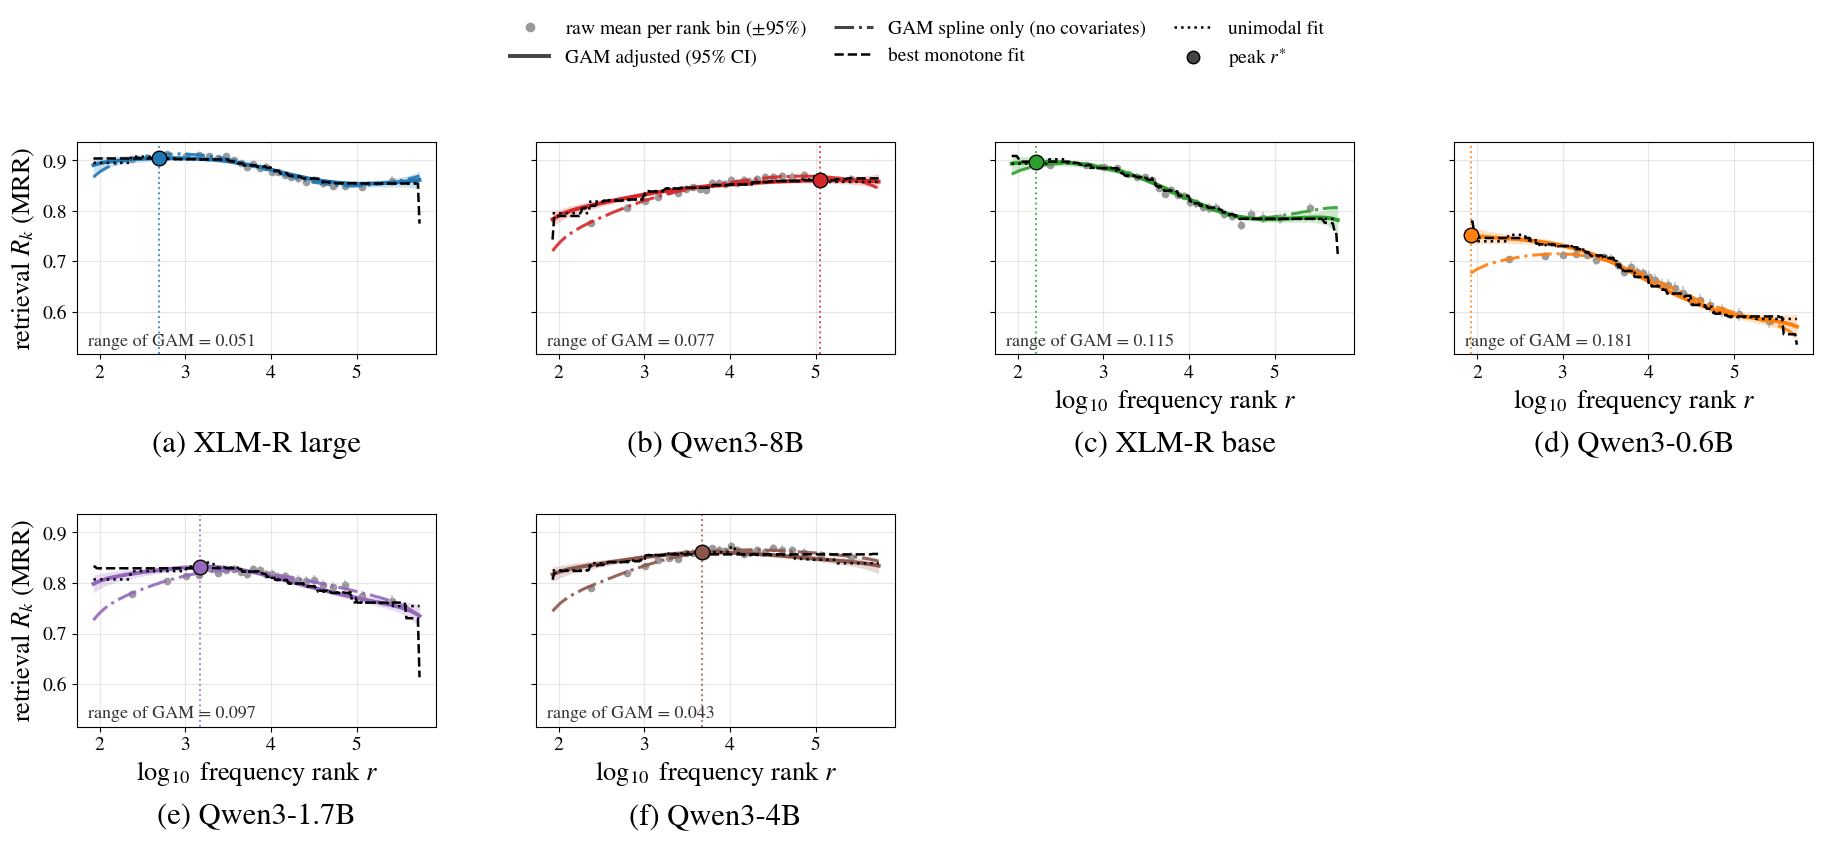

saved /mnt/cl/study4/figures/s3_peak_vs_depth_full.pdf


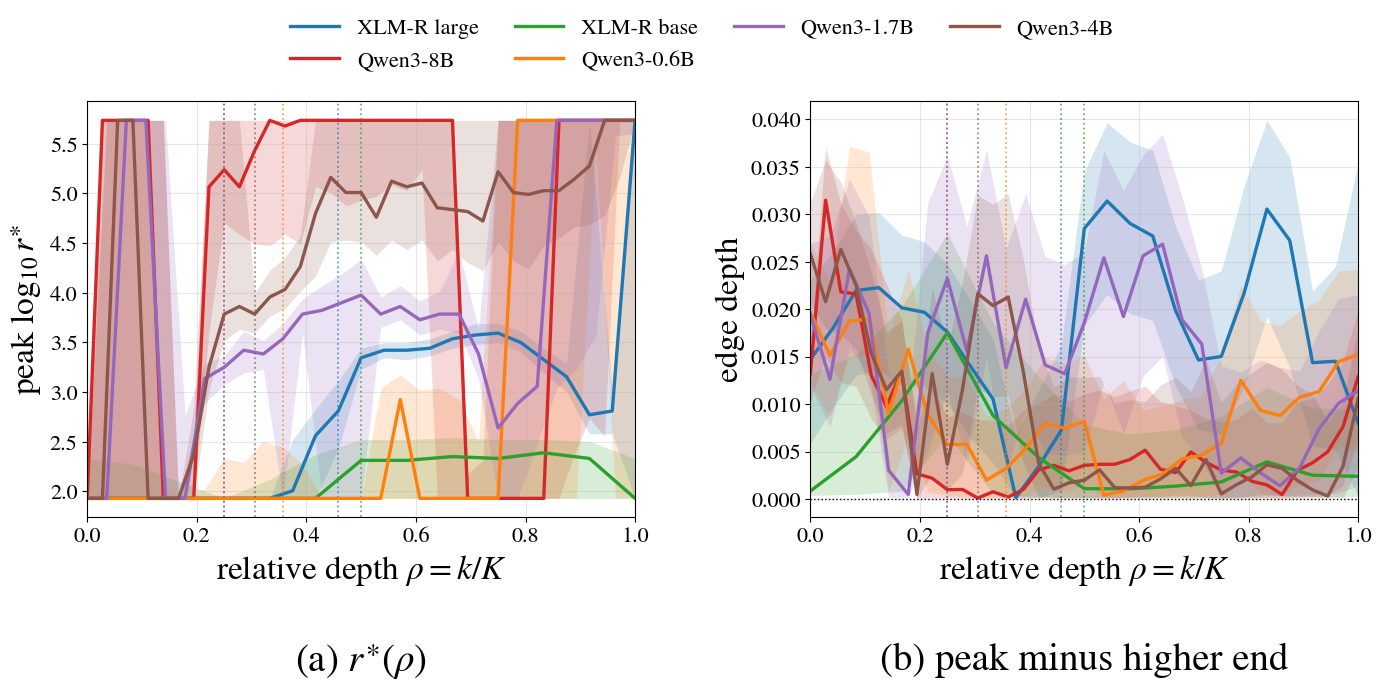

saved /mnt/cl/study4/figures/s3_heatmap_depth_x_rank_full.pdf


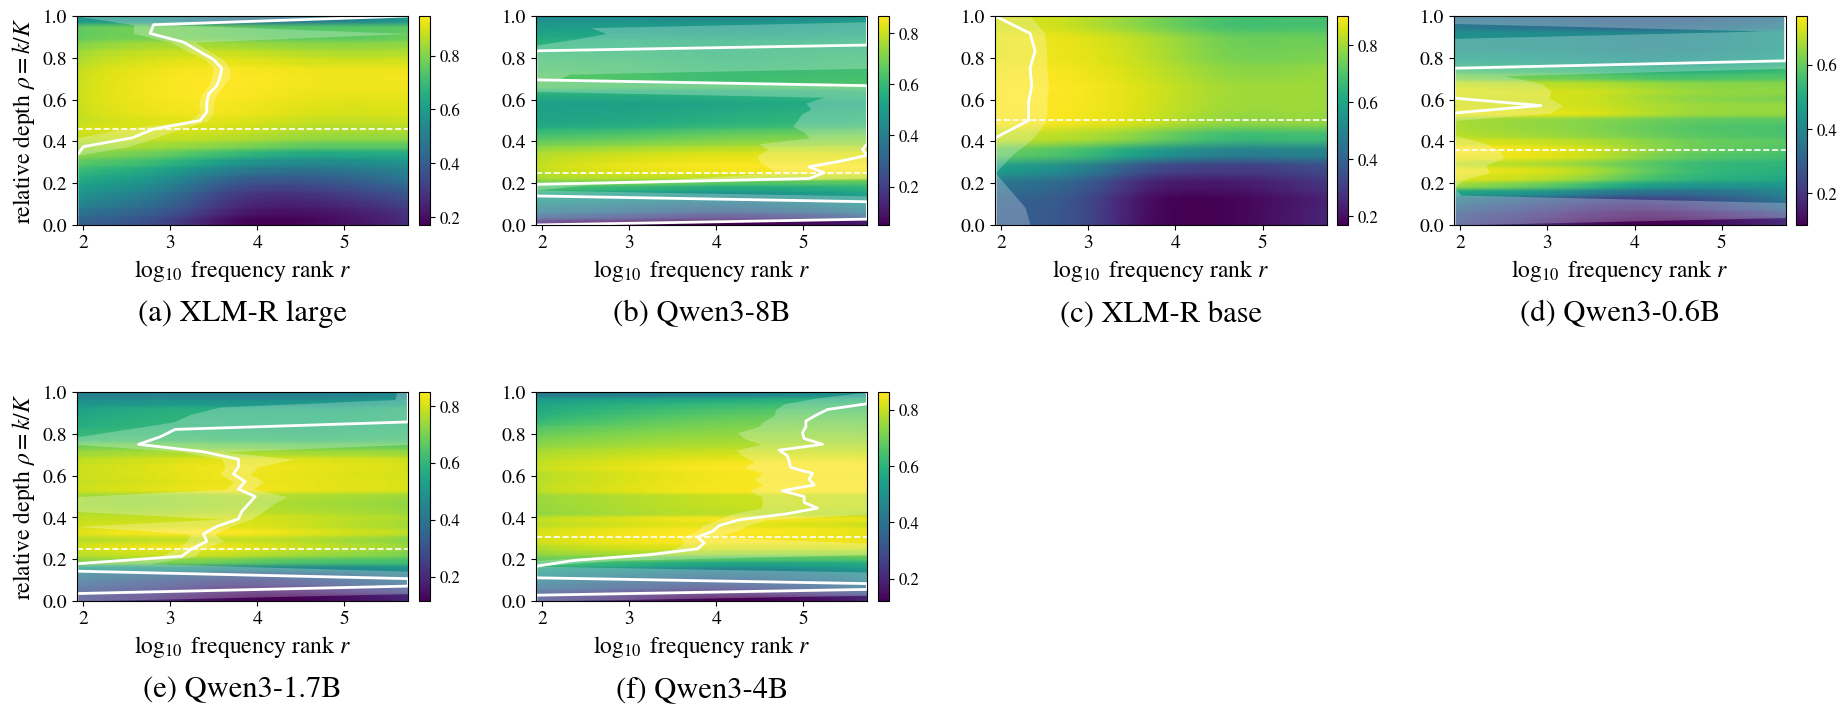

[skip] capacity: chưa có kết quả
saved /mnt/cl/study4/figures/s3_upos_effects_full.pdf


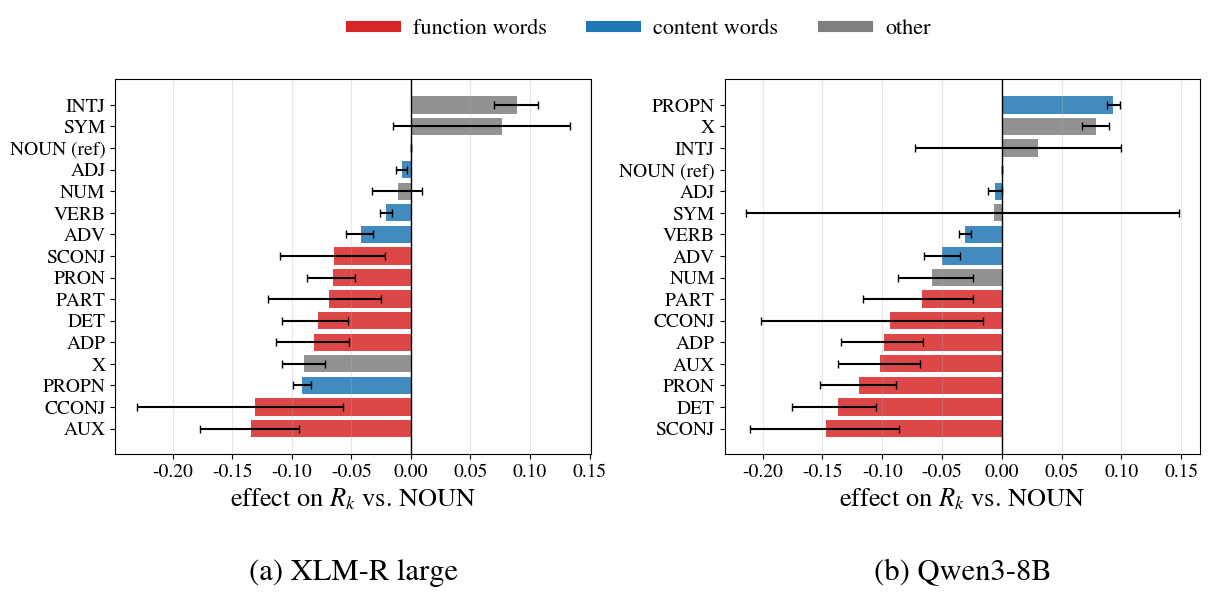

saved /mnt/cl/study4/figures/mantel_xlmr_large_syntactic_full.pdf


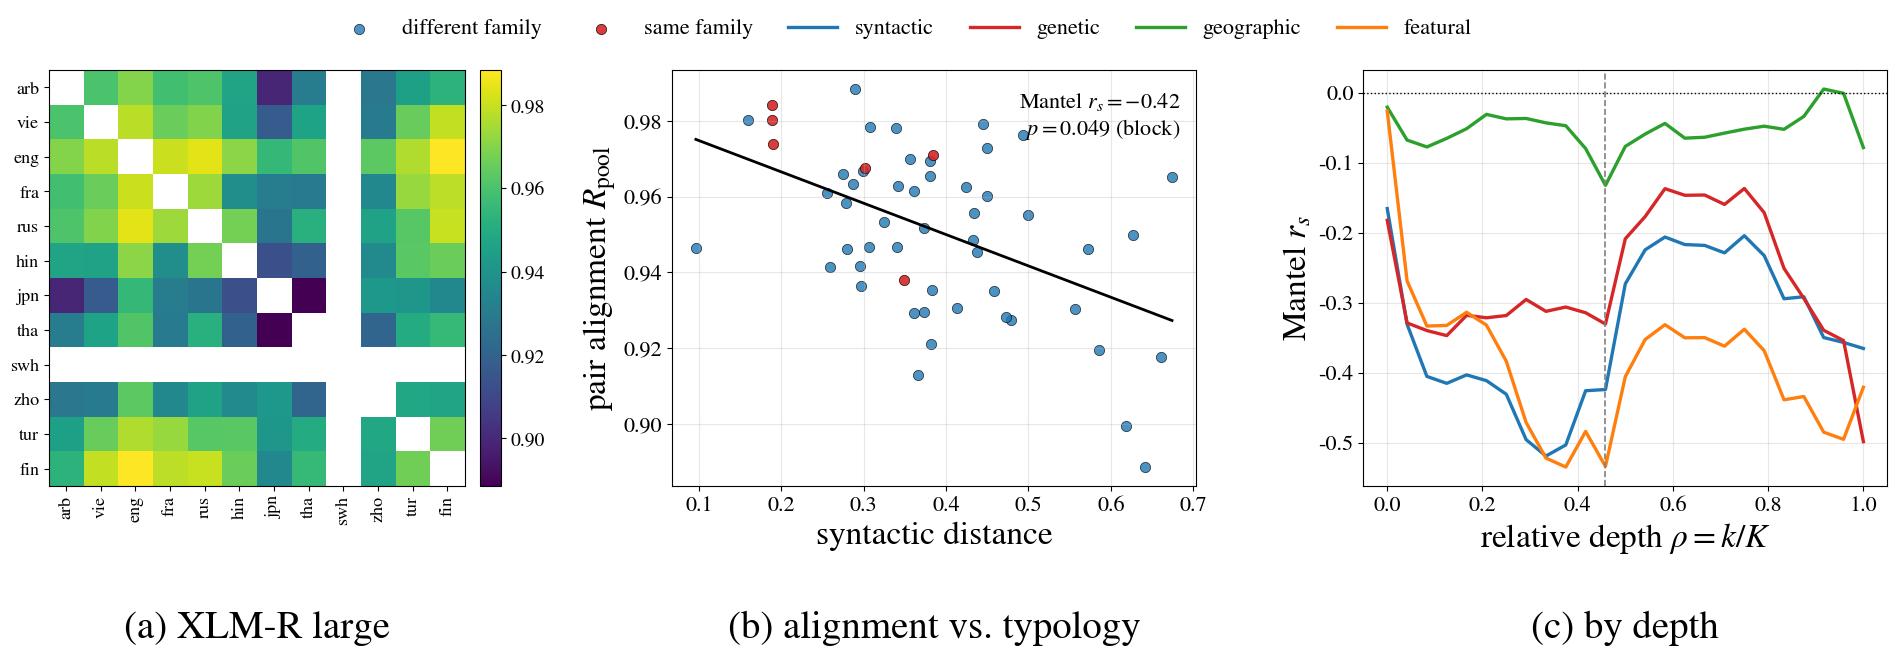

saved /mnt/cl/study4/figures/mantel_qwen3_8b_syntactic_full.pdf


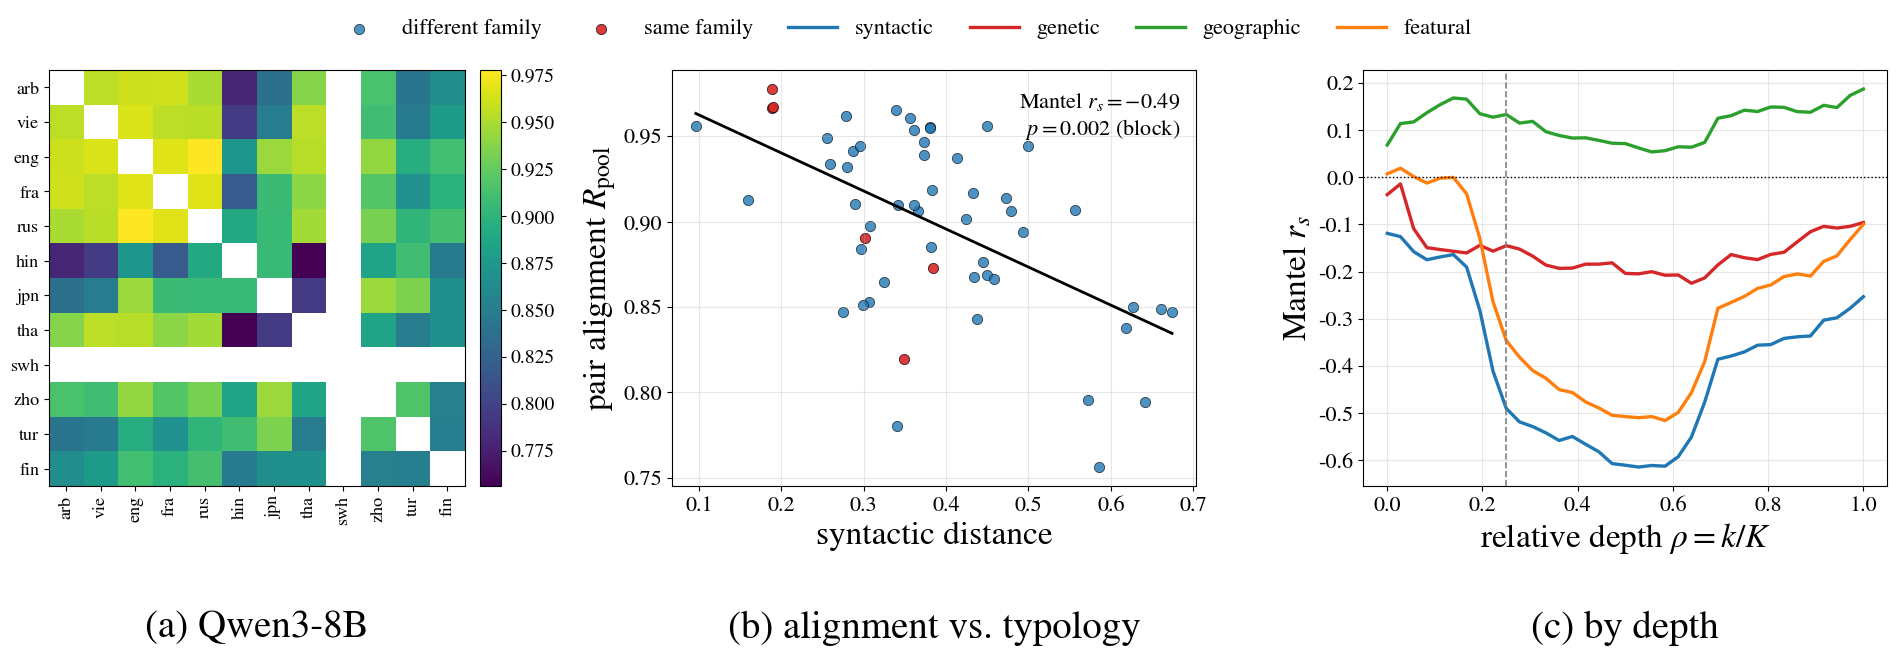

saved /mnt/cl/study4/figures/mantel_xlmr_base_syntactic_full.pdf


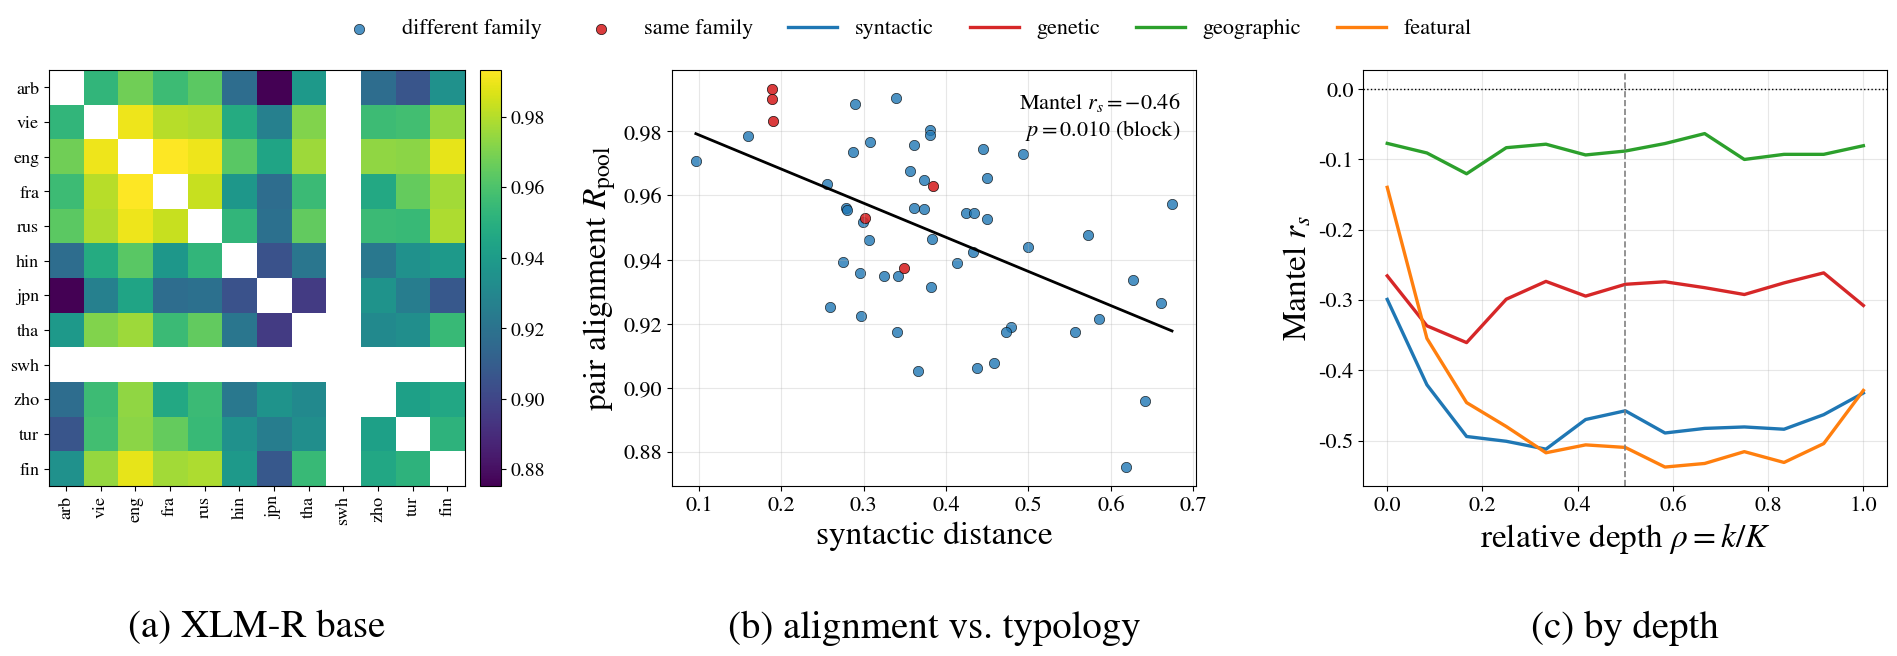

saved /mnt/cl/study4/figures/mantel_qwen3_0.6b_syntactic_full.pdf


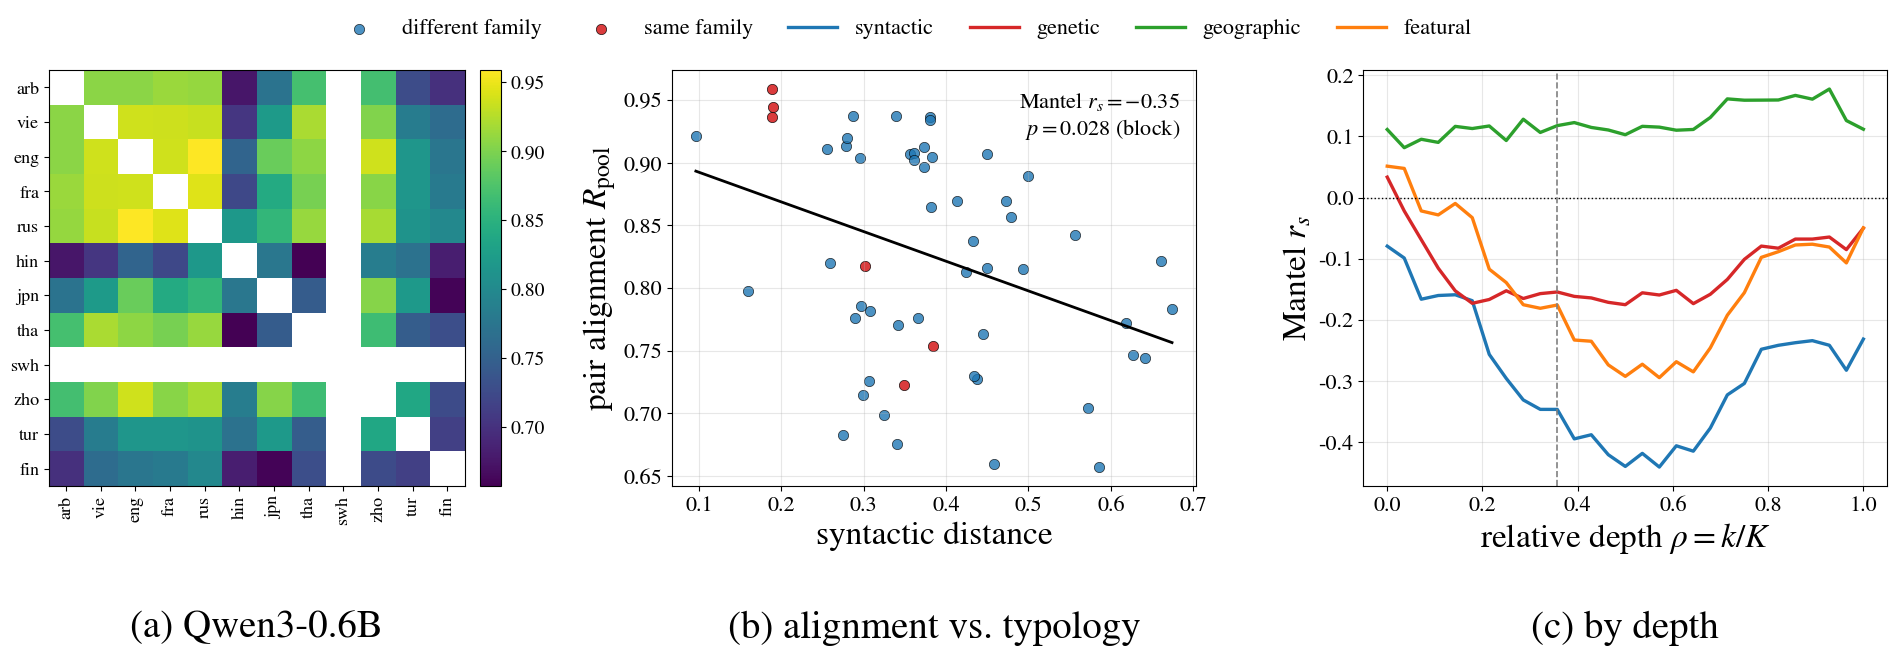

saved /mnt/cl/study4/figures/mantel_qwen3_1.7b_syntactic_full.pdf


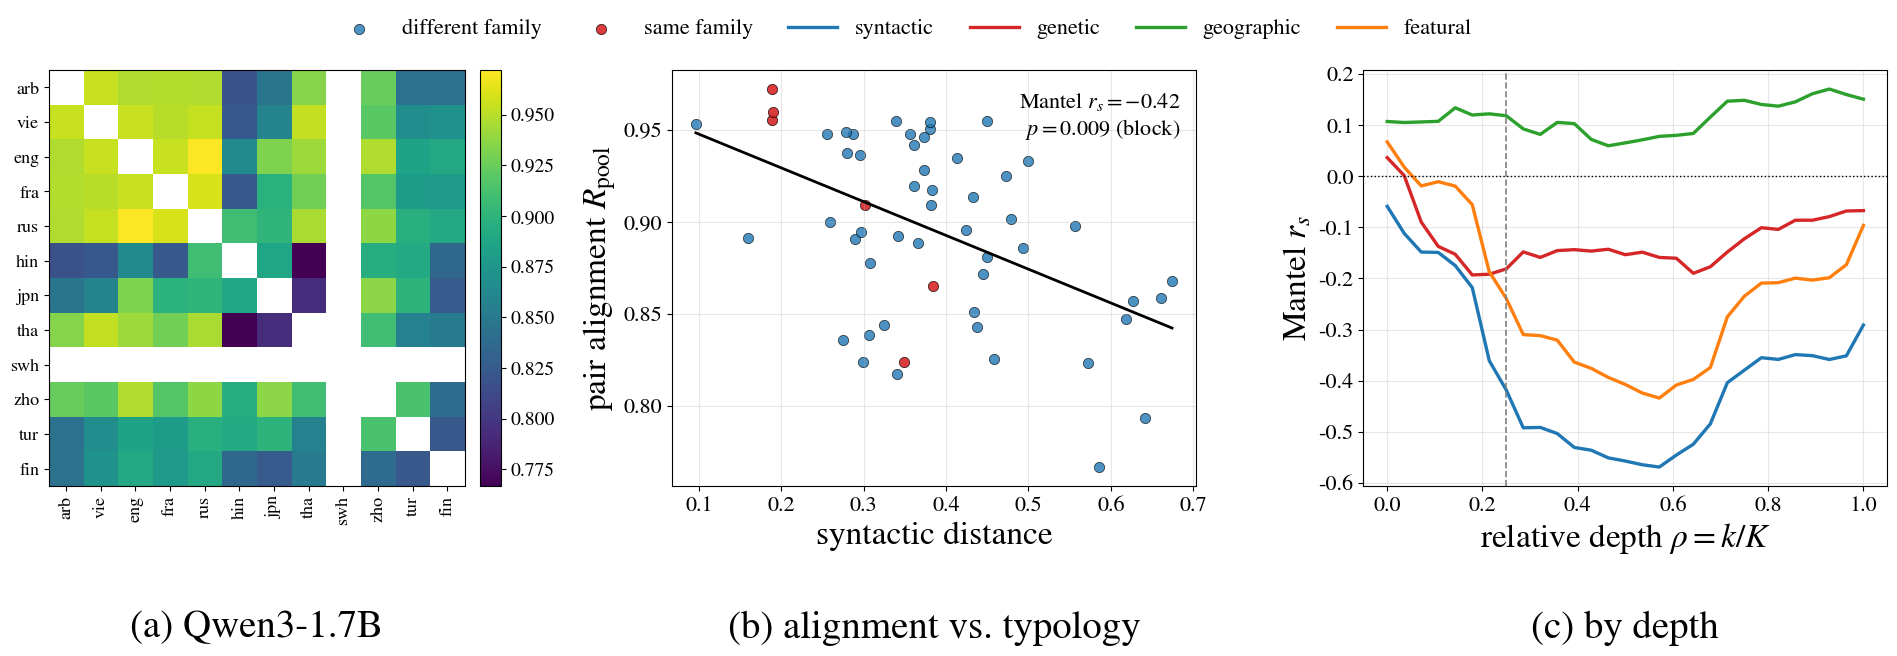

saved /mnt/cl/study4/figures/mantel_qwen3_4b_syntactic_full.pdf


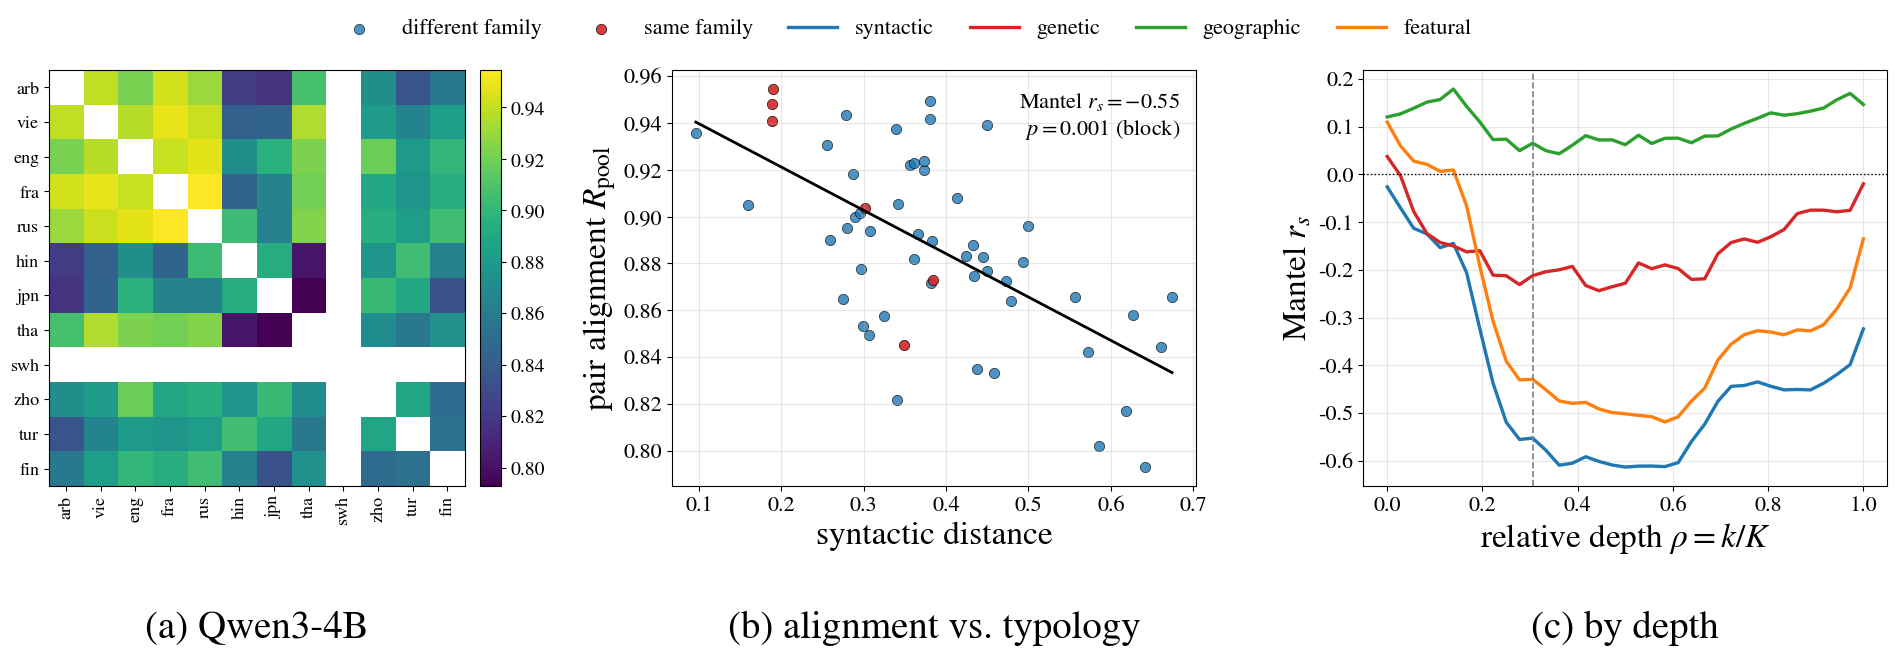

saved /mnt/cl/study4/figures/lang_alignment_vs_fertility_full.pdf


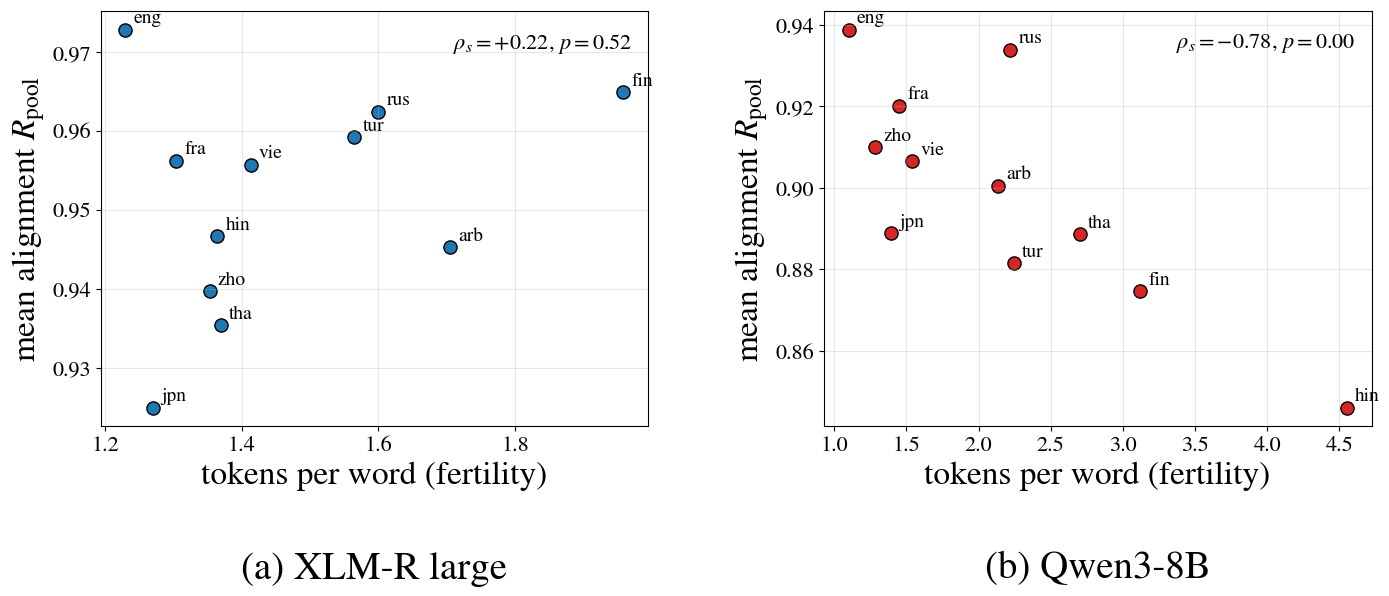

In [56]:
plot_s3_curves()
plot_peak_vs_depth()
plot_heatmaps()
plot_capacity()
plot_upos()
for _k in done_models():
    plot_mantel(_k)
plot_lang_fertility()

saved /mnt/cl/study4/figures/s3_R_vs_logrank_waist_v6_full.pdf


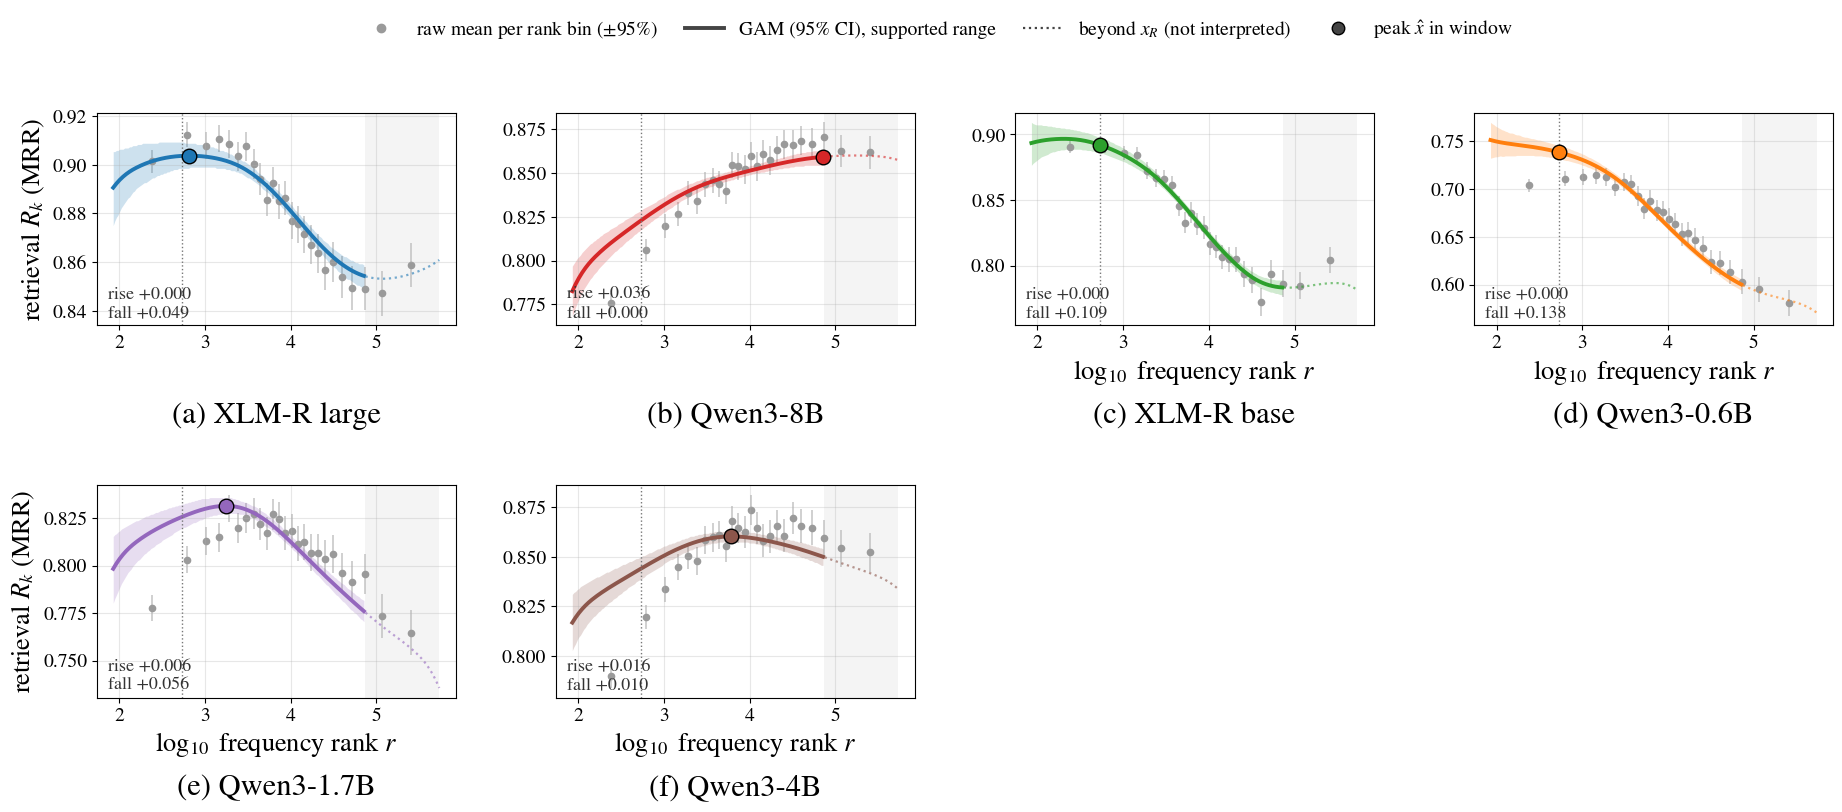

In [57]:
# ============================================================
# Cell D3 — (v6) Hình S3: đường cong chỉ vẽ ĐẬM trong vùng đủ dữ liệu (đến xR = phân vị MAIN_ANCHOR[1]); vùng sau xR xám và nét chấm (không diễn giải).
#   Chú thích mỗi panel: tăng = f(x̂) − f(xL), giảm = f(x̂) − f(xR) (độ lớn MRR; xem C4b). Mỗi panel một trục y -> đọc số, đừng đọc độ cong.
# ============================================================
from matplotlib.lines import Line2D

def plot_s3_v6(keys=None, ncols=4):
    ks = _models_with(keys=keys)
    if not ks:
        print("[skip] s3 v6: chưa có kết quả"); return
    fs = STACK_FS
    fig, axes, nr = grid_axes(len(ks), ncols, sharey=False)
    for ax, k, cap in zip(axes, ks, "abcdefghijkl"):
        z = _load_s3(k); c = load_curve(k, "all"); col = MODEL_COLOR[k]
        if c is None:
            continue
        g, fo, fb = c["grid"], c["f_obs"], c["f_boot"]
        xL, xR = float(c["xq"][MAIN_ANCHOR[0]]), float(c["xq"][MAIN_ANCHOR[1]])
        lo, hi = np.percentile(fb, [2.5, 97.5], axis=0); ins = g <= xR
        ax.errorbar(z["bin_x"], z["bin_y"], yerr=1.96 * z["bin_se"], fmt="o", ms=4.5, color="#9a9a9a", ecolor="#c8c8c8", elinewidth=1.2, zorder=1)
        band(ax, g[ins], fo[ins], lo[ins], hi[ins], col, lw=2.8, alpha=0.22)
        ax.plot(g[~ins], fo[~ins], color=col, lw=1.6, ls=":", alpha=0.6)
        ax.axvspan(xR, g[-1], color="#bbbbbb", alpha=0.15, lw=0)
        ax.axvline(xL, color="#777777", ls=":", lw=1.0)
        r = shape_contrasts(g, fo, fb, xL, xR)
        if r is not None:
            kk = int(np.argmin(np.abs(g - r["x_hat"])))
            ax.scatter([r["x_hat"]], [fo[kk]], s=110, color=col, edgecolor="black", zorder=5)
            ax.text(0.03, 0.04, f"rise {r['rise']:+.3f}\nfall {r['fall']:+.3f}", transform=ax.transAxes, fontsize=fs["tick"] - 1, color="#333333")
        ax.set_xlabel(X_RANK, fontsize=fs["label"]) if (ax in axes[-ncols:] or len(axes) <= ncols) else None
        if ax in axes[::ncols]:
            ax.set_ylabel(Y_R, fontsize=fs["label"])
        ax.grid(alpha=0.3); ax.tick_params(axis="both", labelsize=fs["tick"])
        panel_caption(ax, f"({cap}) {MODELS[k]['label']}", fs, cap_y=-0.36)
    h = [Line2D([], [], color="#9a9a9a", marker="o", ls="", ms=6), Line2D([], [], color="#444444", lw=2.8), Line2D([], [], color="#444444", lw=1.6, ls=":"),
         Line2D([], [], color="#444444", marker="o", mec="black", ls="", ms=9)]
    fig.legend(h, ["raw mean per rank bin ($\\pm$95%)", "GAM (95% CI), supported range", "beyond $x_R$ (not interpreted)", "peak $\\hat{x}$ in window"],
               loc="lower center", bbox_to_anchor=(0.5, 0.87 if nr == 1 else 0.93), ncol=4, fontsize=LEGEND_FS - 2, frameon=False, columnspacing=1.4)
    save_fig(fig, "s3_R_vs_logrank_waist_v6")

plot_s3_v6()


## Chẩn đoán bổ sung


In [59]:
# ============================================================
# Cell E1 — CHẨN ĐOÁN thiên lệch hubness của CSLS: R theo log-hạng với cosine / CSLS-theo-loại / CSLS-theo-instance (cách cũ)
# Cần cache biểu diễn mức từ (đặt KEEP_WORD_CACHE = True ở Cell A1 trước khi chạy model). Nếu "instance" thấp hơn rõ rệt ở các bin đầu so với "cos"/"type"
# thì nhánh trái cũ là artifact của CSLS-theo-instance. Giá trị = RR trung bình theo instance (phía a->b) trong từng khoảng log10-hạng của từ nguồn.
# ============================================================
@torch.no_grad()
def diag_hub_modes(key, layer=None, pair_names=("eng-fra", "eng-rus", "eng-vie", "eng-zho"), bins=(0, 2, 3, 4, 5, 9)):
    cfg = MODELS[key]; run, meta = load_run(key); kw, K1 = waist_layer(key, run); layer = kw if layer is None else layer
    tok = load_tokenizer(cfg)
    plans = {l: plan_language(tok, cfg, TEXTS[MEAS][l], WT[MEAS][l], NEED[l]) for l in LANGS}
    prow = pair_rows(ITEMS, plans)
    mms = [np.load(cache_path(key, l), mmap_mode="r") for l in LANGS]
    Xs = [torch.from_numpy(np.array(m[layer])).to(DEVICE).float() for m in mms]
    n_all = sum(x.shape[0] for x in Xs); mu = sum(x.sum(0) for x in Xs) / n_all
    sd = (sum(((x - mu) ** 2).sum(0) for x in Xs) / n_all).sqrt().clamp_min(1e-6)
    Xs = [(x - mu) / sd for x in Xs]; Xs = [x - x.mean(0, keepdim=True) for x in Xs]
    out, labels = {}, [f"{bins[i]}-{bins[i + 1]}" for i in range(len(bins) - 1)]
    for name in pair_names:
        pi = PAIR_NAME.index(name); ia, ib = PAIRS[pi]; s, e, ra, rb, v = prow[pi]
        ga, gb = ITEMS["wa"][s:e][v], ITEMS["wb"][s:e][v]
        Xa = F.normalize(Xs[ia][torch.from_numpy(ra[v]).to(DEVICE)], dim=1); Xb = F.normalize(Xs[ib][torch.from_numpy(rb[v]).to(DEVICE)], dim=1)
        C = Xa @ Xb.T
        ta = torch.from_numpy(TID[LANGS[ia]][ga]).to(DEVICE); tb = torch.from_numpy(TID[LANGS[ib]][gb]).to(DEVICE)
        la = LANGS[ia]; lr = np.array([RANKS[la].log_rank(WT[MEAS][la]["norm"][g])[0] for g in ga]); bi = np.digitize(lr, bins[1:-1])
        for mode in ("cos", "type", "instance"):
            rr = csls_mrr(C, ta, tb, mode=mode)[0].cpu().numpy()
            out[(name, mode)] = [float(rr[bi == i].mean()) if (bi == i).any() else np.nan for i in range(len(labels))]
    return pd.DataFrame(out, index=labels).T.round(3)

# Ví dụ (sau khi chạy model với KEEP_WORD_CACHE = True):  diag_hub_modes("qwen3_1.7b")


In [58]:
# ============================================================
# Cell E2 — (v5) CHẨN ĐOÁN bổ sung sau khi chạy lại (chỉ đọc kết quả; không cần GPU)
#   diag_mask_effect : mặt nạ "mọi bản dịch hợp lệ" nâng R bao nhiêu, theo khoảng hạng? (kiểm A: từ chức năng/phổ biến bị phạt oan vì nhiều dạng dịch)
#   diag_tie_block   : khối hapax / hạng bằng nhau ở biên phải chiếm bao nhiêu dữ liệu, và cửa sổ đuôi (EDGE_Q) có gồm trọn khối đó không? (kiểm C)
#   diag_criteria    : cùng một model, các tiêu chí/biến thể song song (GAM đầy đủ, chỉ spline, không nsub/độ dài/ngôn ngữ, strict, không hapax, λ khác) (kiểm B, C, E)
#   diag_numerics    : sanity batch-vs-single (bf16 và fp32), n_clip theo model (kiểm G)
# ============================================================
def _main_pairs():
    pair_muse = [pi for pi in range(P_) if PAIR_STATS.confirm_src.iloc[pi] in MAIN_SRCS]
    return pair_muse if (MAIN_PAIRS == "muse" and 0 < len(pair_muse) < P_) else None

def diag_mask_effect(key, nb=8):
    run, _ = load_run(key); kw, K1 = waist_layer(key, run)
    if "RR_AB_V" not in run:
        print("[skip] không có biến thể 'valid' (MASK_VALID_TRANSLATIONS=False khi chạy)"); return None
    d1, R1 = word_table(key, _main_pairs(), variant="strict"); d2, R2 = word_table(key, _main_pairs(), variant="valid")
    x = d1.log_rank.values; edges = np.unique(np.quantile(x, np.linspace(0, 1, nb + 1))); bi = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    rows = [dict(bin=f"{edges[i]:.2f}-{edges[i + 1]:.2f}", n=int((bi == i).sum()), R_strict=R1[bi == i, kw].mean(), R_valid=R2[bi == i, kw].mean(),
                 gain=(R2[bi == i, kw] - R1[bi == i, kw]).mean(), trans_ent=d1.trans_ent.values[bi == i].mean(),
                 func_share=d1.upos.isin(FUNC_UPOS).values[bi == i].mean()) for i in range(len(edges) - 1)]
    out = pd.DataFrame(rows); print(f"[{key}] tầng {kw}: tác động của mặt nạ 'bản dịch hợp lệ' theo log10-hạng"); print(out.round(4).to_string(index=False)); return out

def diag_tie_block(key):
    d0, R0 = word_table(key, _main_pairs()); d, R = prep_main(d0, R0)
    x = d.log_rank.values; at_max = x >= x.max() - 1e-9; tl = float(np.quantile(x, EDGE_Q[1]))
    print(f"[{key}] {len(d):,} dạng từ sau prep_main | trùng hạng ở biên phải: {at_max.mean():.1%} | từ có fw_count==1: {(d.fw_count == 1).mean():.1%} | fw_count<=3: {(d.fw_count <= 3).mean():.1%}")
    print(f"   cửa sổ đuôi (x >= phân vị {EDGE_Q[1]:.0%} = {tl:.2f}) gồm {(x >= tl).sum():,} từ, trong đó {(at_max & (x >= tl)).sum() / max((x >= tl).sum(), 1):.1%} là khối hạng-bằng-nhau ở biên")
    print(d.assign(at_max=at_max).groupby("lang").at_max.mean().round(3).to_dict())

def diag_criteria(S3_ALL, subsets=("all", "gam_bare", "gam_upos_pmix", "rr_strict", "rr_valid", "no_hapax", "lam_x0.1", "lam_x10")):
    cols = ["key", "subset", "n_words", "shape", "shape_q", "p_LM", "p_LM_q", "p_LM_amp", "amp", "amp_lo", "amp_hi", "x_star", "p_right_down", "p_right_down_q"]
    t = S3_ALL[S3_ALL.subset.isin(subsets)][[c for c in cols if c in S3_ALL]].copy()
    t["subset"] = pd.Categorical(t.subset, [s for s in subsets if s in set(t.subset)], ordered=True)
    t = t.sort_values(["key", "subset"]); print(t.round(3).to_string(index=False)); return t

def diag_numerics():
    rows = []
    for k in done_models():
        m = read_json(f"{run_dir(k)}/meta.json", {}); s = m.get("sanity") or {}; s32 = m.get("sanity_fp32") or {}
        rows.append(dict(key=k, dtype=m.get("dtype"), n_clip=m.get("n_clip"), numerics_flag=m.get("numerics_flag"),
                         max_rel_diff=max([v.get("max", np.nan) for v in s.values()], default=np.nan),
                         frac_gt_tol=max([v.get("frac", np.nan) for v in s.values()], default=np.nan),
                         fp32_ok=(None if not s32 else all(v.get("ok") for v in s32.values()))))
    t = pd.DataFrame(rows); print(t.round(4).to_string(index=False)); return t

if "S3_ALL" in globals() and len(S3_ALL):
    _ = diag_numerics(); print()
    for _k in done_models():
        diag_tie_block(_k); _ = diag_mask_effect(_k); print()
    _ = diag_criteria(S3_ALL)


       key         dtype  n_clip  numerics_flag  max_rel_diff  frac_gt_tol fp32_ok
xlmr_large torch.float32       0          False        0.0006          0.0    None
  qwen3_8b torch.float32       0          False        0.0009          0.0    None
 xlmr_base torch.float32       0          False        0.0006          0.0    None
qwen3_0.6b torch.float32       0          False        0.0006          0.0    None
qwen3_1.7b torch.float32       0          False        0.0005          0.0    None
  qwen3_4b torch.float32       0          False        0.0008          0.0    None

[xlmr_large] 82,399 dạng từ sau prep_main | trùng hạng ở biên phải: 0.0% | từ có fw_count==1: 0.0% | fw_count<=3: 0.1%
   cửa sổ đuôi (x >= phân vị 90% = 4.87) gồm 8,241 từ, trong đó 0.3% là khối hạng-bằng-nhau ở biên
{'arb': 0.0, 'eng': 0.0, 'fin': 0.002, 'fra': 0.0, 'hin': 0.0, 'jpn': 0.0, 'rus': 0.0, 'tha': 0.0, 'tur': 0.0, 'vie': 0.0, 'zho': 0.0}
[xlmr_large] tầng 11: tác động của mặt nạ 'bản dịch hợp lệ' theo 